In [1]:
import os
patient_folders = os.listdir('picai_images')
print(len(patient_folders))
print(patient_folders[:5])

1476
['10268', '11188', '10866', '10892', '10065']


In [2]:
sample_patient = patient_folders[0]
files = os.listdir(os.path.join('picai_images', sample_patient))
print(sample_patient)
print(files)

10268
['10268_1000272_t2w.mha', '10268_1000272_hbv.mha', '10268_1000272_cor.mha', '10268_1000272_adc.mha', '10268_1000272_sag.mha']


In [3]:
import SimpleITK as sitk

sample_path = os.path.join('picai_images', sample_patient, files[0])
img = sitk.ReadImage(sample_path)
img_array = sitk.GetArrayFromImage(img)

print("Shape:", img_array.shape)   # (slices, height, width)
print("Spacing:", img.GetSpacing())
print("Data type:", img_array.dtype)

Shape: (23, 384, 384)
Spacing: (0.5, 0.5, 2.9999998702864725)
Data type: uint16


In [4]:
import SimpleITK as sitk
import numpy as np
import cv2

def load_middle_slice(mha_path, target_size=(224, 224)):
    img = sitk.ReadImage(mha_path)
    arr = sitk.GetArrayFromImage(img)  # shape: (slices, H, W)
    
    middle_idx = arr.shape[0] // 2
    slice_2d = arr[middle_idx]
    
    # Normalize uint16 -> 0-255 uint8
    slice_norm = cv2.normalize(slice_2d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    
    # Resize to CNN input size
    slice_resized = cv2.resize(slice_norm, target_size)
    
    # Convert grayscale -> 3-channel (ResNet50 expects RGB-shaped input)
    slice_rgb = cv2.cvtColor(slice_resized, cv2.COLOR_GRAY2RGB)
    
    return slice_rgb

# Test it on your sample patient
test_slice = load_middle_slice(sample_path)
print(test_slice.shape)  # should be (224, 224, 3)

(224, 224, 3)


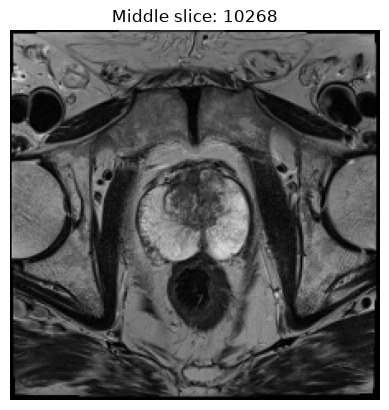

In [5]:
import matplotlib.pyplot as plt
plt.imshow(test_slice)
plt.title(f"Middle slice: {sample_patient}")
plt.axis('off')
plt.show()

In [6]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
import numpy as np
import os

base_model = ResNet50(weights='imagenet', include_top=False, pooling='avg')

def extract_cnn_features(mha_path):
    slice_rgb = load_middle_slice(mha_path)  # from your existing function
    img_array = np.expand_dims(slice_rgb, axis=0).astype(np.float32)
    img_preprocessed = preprocess_input(img_array)
    features = base_model.predict(img_preprocessed, verbose=0)
    return features.flatten()  # 2048-dim vector

2026-07-29 15:33:32.646628: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-07-29 15:33:32.646731: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-07-29 15:33:32.646748: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-07-29 15:33:32.646826: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-07-29 15:33:32.646858: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [7]:
test_features = extract_cnn_features(sample_path)
print(test_features.shape)  # should be (2048,)

2026-07-29 15:33:41.144822: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


(2048,)


In [8]:
feature_rows = []

for i, patient_id in enumerate(patient_folders):
    folder_path = os.path.join('picai_images', patient_id)
    files = os.listdir(folder_path)
    
    t2w_file = [f for f in files if 't2w' in f.lower()]
    if not t2w_file:
        continue  # skip if no T2W scan found
    
    mha_path = os.path.join(folder_path, t2w_file[0])
    
    try:
        features = extract_cnn_features(mha_path)
        row = {'patient_id': patient_id}
        row.update({f'cnn_feat_{j}': features[j] for j in range(len(features))})
        feature_rows.append(row)
    except Exception as e:
        print(f"Failed on {patient_id}: {e}")
    
    if i % 100 == 0:
        print(f"Processed {i}/{len(patient_folders)}")

cnn_features_df = pd.DataFrame(feature_rows)
print(cnn_features_df.shape)

Processed 0/1476
Processed 100/1476
Processed 200/1476
Processed 300/1476
Processed 400/1476
Processed 500/1476
Processed 600/1476
Processed 700/1476
Processed 800/1476
Processed 900/1476
Processed 1000/1476
Processed 1100/1476
Processed 1200/1476
Processed 1300/1476
Processed 1400/1476


NameError: name 'pd' is not defined

In [9]:
import pandas as pd
cnn_features_df = pd.DataFrame(feature_rows)
print(cnn_features_df.shape)

(1476, 2049)


In [10]:
cnn_features_df.to_csv('cnn_features_t2w.csv', index=False)

In [11]:
print(len(feature_rows))

1476


In [12]:
picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')

print("Unique patients in clinical:", picai_clinical_clean['patient_id'].nunique())
print("Unique patients in CNN features:", cnn_features_df['patient_id'].nunique())

# Check dtype match — folder names are strings, clinical patient_id might be int
print(picai_clinical_clean['patient_id'].dtype)
print(cnn_features_df['patient_id'].dtype)

Unique patients in clinical: 1476
Unique patients in CNN features: 1476
int64
str


In [13]:
cnn_features_df['patient_id'] = cnn_features_df['patient_id'].astype(int)

fused_df = picai_clinical_clean.merge(cnn_features_df, on='patient_id', how='inner')
print(fused_df.shape)
fused_df['csPCa_label'].value_counts()

(1500, 2056)


csPCa_label
0    1075
1     425
Name: count, dtype: int64

In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cnn_cols = [c for c in cnn_features_df.columns if c.startswith('cnn_feat_')]
X_cnn = fused_df[cnn_cols]

# Standardize before PCA (PCA is scale-sensitive)
scaler = StandardScaler()
X_cnn_scaled = scaler.fit_transform(X_cnn)

# Reduce to 50 components — captures most variance, drastically cuts dimensionality
pca = PCA(n_components=50, random_state=42)
X_cnn_pca = pca.fit_transform(X_cnn_scaled)

print("Explained variance captured:", pca.explained_variance_ratio_.sum())

pca_cols = [f'cnn_pca_{i}' for i in range(50)]
cnn_pca_df = pd.DataFrame(X_cnn_pca, columns=pca_cols)

Explained variance captured: 0.59355253


In [15]:
pca_check = PCA(random_state=42)
pca_check.fit(X_cnn_scaled)

cumulative_variance = np.cumsum(pca_check.explained_variance_ratio_)

# Find how many components needed for 90% and 95% variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Components needed for 90% variance: {n_90}")
print(f"Components needed for 95% variance: {n_95}")

Components needed for 90% variance: 387
Components needed for 95% variance: 593


In [16]:
pca = PCA(n_components=min(n_90, 100), random_state=42)  # cap at 100 regardless
X_cnn_pca = pca.fit_transform(X_cnn_scaled)
print("Explained variance captured:", pca.explained_variance_ratio_.sum())

pca_cols = [f'cnn_pca_{i}' for i in range(X_cnn_pca.shape[1])]
cnn_pca_df = pd.DataFrame(X_cnn_pca, columns=pca_cols)
print(cnn_pca_df.shape)

Explained variance captured: 0.7046071
(1500, 100)


In [17]:
final_model_df = pd.concat([
    fused_df[['patient_id', 'patient_age', 'psa', 'psad', 'prostate_volume', 'csPCa_label']].reset_index(drop=True),
    cnn_pca_df.reset_index(drop=True)
], axis=1)

print(final_model_df.shape)  # should be (1500, 106)
final_model_df.to_csv('fused_final_dataset.csv', index=False)

(1500, 106)


In [18]:
from sklearn.model_selection import train_test_split

X = final_model_df.drop(columns=['patient_id', 'csPCa_label'])
y = final_model_df['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(1200, 104) (300, 104)
csPCa_label
0    860
1    340
Name: count, dtype: int64
csPCa_label
0    215
1     85
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Scale features (important for LR and SVM, harmless for RF)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params = {
    'LogisticRegression': (
        LogisticRegression(max_iter=1000, class_weight='balanced'),
        {'C': [0.01, 0.1, 1, 10]}
    ),
    'RandomForest': (
        RandomForestClassifier(random_state=42, class_weight='balanced'),
        {'n_estimators': [100, 300, 500], 'max_depth': [None, 10, 20]}
    ),
    'SVM': (
        SVC(probability=True, class_weight='balanced'),
        {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
    )
}

best_models = {}
for name, (model, params) in models_params.items():
    grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train_scaled, y_train)
    best_models[name] = grid.best_estimator_
    print(f"{name}: best params={grid.best_params_}, best CV ROC-AUC={grid.best_score_:.4f}")

LogisticRegression: best params={'C': 0.01}, best CV ROC-AUC=0.7300
RandomForest: best params={'max_depth': 10, 'n_estimators': 500}, best CV ROC-AUC=0.7396


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM: best params={'C': 1, 'kernel': 'rbf'}, best CV ROC-AUC=0.7225


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

results = []
for name, model in best_models.items():
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

results_df = pd.DataFrame(results)
print(results_df)

                Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  LogisticRegression  0.653333   0.426357  0.647059  0.514019  0.714419
1        RandomForest  0.740000   0.546667  0.482353  0.512500  0.766895
2                 SVM  0.700000   0.475248  0.564706  0.516129  0.734446


In [21]:
for name, model in best_models.items():
    preds = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, preds)
    print(f"--- {name} ---")
    print(cm)
    print(f"False negatives (missed cancer): {cm[1][0]}")
    print(f"False positives (false alarm): {cm[0][1]}")
    print()

--- LogisticRegression ---
[[141  74]
 [ 30  55]]
False negatives (missed cancer): 30
False positives (false alarm): 74

--- RandomForest ---
[[181  34]
 [ 44  41]]
False negatives (missed cancer): 44
False positives (false alarm): 34

--- SVM ---
[[162  53]
 [ 37  48]]
False negatives (missed cancer): 37
False positives (false alarm): 53



In [22]:
def extract_features_for_sequence(sequence_name):
    feature_rows = []
    
    for i, patient_id in enumerate(patient_folders):
        folder_path = os.path.join('picai_images', patient_id)
        files = os.listdir(folder_path)
        
        seq_file = [f for f in files if sequence_name in f.lower()]
        if not seq_file:
            continue
        
        mha_path = os.path.join(folder_path, seq_file[0])
        
        try:
            features = extract_cnn_features(mha_path)
            row = {'patient_id': patient_id}
            row.update({f'{sequence_name}_feat_{j}': features[j] for j in range(len(features))})
            feature_rows.append(row)
        except Exception as e:
            print(f"Failed on {patient_id} ({sequence_name}): {e}")
        
        if i % 200 == 0:
            print(f"{sequence_name}: processed {i}/{len(patient_folders)}")
    
    return pd.DataFrame(feature_rows)

adc_features_df = extract_features_for_sequence('adc')
adc_features_df.to_csv('cnn_features_adc.csv', index=False)
print(adc_features_df.shape)

adc: processed 0/1476
adc: processed 200/1476
adc: processed 400/1476
adc: processed 600/1476
adc: processed 800/1476
adc: processed 1000/1476
adc: processed 1200/1476
adc: processed 1400/1476
(1476, 2049)


In [23]:
hbv_features_df = extract_features_for_sequence('hbv')
hbv_features_df.to_csv('cnn_features_hbv.csv', index=False)
print(hbv_features_df.shape)

hbv: processed 0/1476
hbv: processed 200/1476
hbv: processed 400/1476
hbv: processed 600/1476
hbv: processed 800/1476
hbv: processed 1000/1476
hbv: processed 1200/1476
hbv: processed 1400/1476
(1476, 2049)


In [24]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

t2w_features_df = pd.read_csv('cnn_features_t2w.csv')
adc_features_df = pd.read_csv('cnn_features_adc.csv')
hbv_features_df = pd.read_csv('cnn_features_hbv.csv')

print(t2w_features_df.shape, adc_features_df.shape, hbv_features_df.shape)

(1476, 2049) (1476, 2049) (1476, 2049)


In [25]:
def reduce_sequence(df, prefix, n_components=35):
    feat_cols = [c for c in df.columns if c.startswith(f'{prefix}_feat_')]
    X = df[feat_cols]
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    
    print(f"{prefix}: variance captured = {pca.explained_variance_ratio_.sum():.4f}")
    
    pca_cols = [f'{prefix}_pca_{i}' for i in range(n_components)]
    result_df = pd.DataFrame(X_pca, columns=pca_cols)
    result_df['patient_id'] = df['patient_id'].astype(int).values
    return result_df

t2w_pca_df = reduce_sequence(t2w_features_df, 't2w')
adc_pca_df = reduce_sequence(adc_features_df, 'adc')
hbv_pca_df = reduce_sequence(hbv_features_df, 'hbv')

ValueError: at least one array or dtype is required

In [26]:
print(t2w_features_df.columns.tolist()[:5])
print(adc_features_df.columns.tolist()[:5])
print(hbv_features_df.columns.tolist()[:5])

['patient_id', 'cnn_feat_0', 'cnn_feat_1', 'cnn_feat_2', 'cnn_feat_3']
['patient_id', 'adc_feat_0', 'adc_feat_1', 'adc_feat_2', 'adc_feat_3']
['patient_id', 'hbv_feat_0', 'hbv_feat_1', 'hbv_feat_2', 'hbv_feat_3']


In [27]:
def reduce_sequence(df, feat_prefix, output_prefix, n_components=35):
    feat_cols = [c for c in df.columns if c.startswith(feat_prefix)]
    X = df[feat_cols]
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    
    print(f"{output_prefix}: variance captured = {pca.explained_variance_ratio_.sum():.4f}")
    
    pca_cols = [f'{output_prefix}_pca_{i}' for i in range(n_components)]
    result_df = pd.DataFrame(X_pca, columns=pca_cols)
    result_df['patient_id'] = df['patient_id'].astype(int).values
    return result_df

t2w_pca_df = reduce_sequence(t2w_features_df, 'cnn_feat_', 't2w')
adc_pca_df = reduce_sequence(adc_features_df, 'adc_feat_', 'adc')
hbv_pca_df = reduce_sequence(hbv_features_df, 'hbv_feat_', 'hbv')

t2w: variance captured = 0.5356
adc: variance captured = 0.5377
hbv: variance captured = 0.5454


In [28]:
imaging_combined = t2w_pca_df.merge(adc_pca_df, on='patient_id', how='inner') \
                              .merge(hbv_pca_df, on='patient_id', how='inner')
print(imaging_combined.shape)  # expect (~1476, 106)

(1476, 106)


In [29]:
picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')

fused_mp_df = picai_clinical_clean.merge(imaging_combined, on='patient_id', how='inner')
print(fused_mp_df.shape)  # expect around (1500, 111) — 5 clinical + 1 label + 105 imaging
fused_mp_df['csPCa_label'].value_counts()

(1500, 113)


csPCa_label
0    1075
1     425
Name: count, dtype: int64

In [30]:
fused_mp_df.to_csv('fused_multiparametric_dataset.csv', index=False)

from sklearn.model_selection import train_test_split

X_mp = fused_mp_df.drop(columns=['patient_id', 'csPCa_label'])
y_mp = fused_mp_df['csPCa_label']

X_train_mp, X_test_mp, y_train_mp, y_test_mp = train_test_split(
    X_mp, y_mp, test_size=0.2, stratify=y_mp, random_state=42
)

scaler_mp = StandardScaler()
X_train_mp_scaled = scaler_mp.fit_transform(X_train_mp)
X_test_mp_scaled = scaler_mp.transform(X_test_mp)

print(X_train_mp_scaled.shape, X_test_mp_scaled.shape)

ValueError: could not convert string to float: 'RUMC'

In [31]:
X_mp = fused_mp_df.drop(columns=['patient_id', 'csPCa_label', 'center'])
y_mp = fused_mp_df['csPCa_label']

In [32]:
X_train_mp, X_test_mp, y_train_mp, y_test_mp = train_test_split(
    X_mp, y_mp, test_size=0.2, stratify=y_mp, random_state=42
)

scaler_mp = StandardScaler()
X_train_mp_scaled = scaler_mp.fit_transform(X_train_mp)
X_test_mp_scaled = scaler_mp.transform(X_test_mp)

print(X_train_mp_scaled.shape, X_test_mp_scaled.shape)

(1200, 110) (300, 110)


In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params = {
    'LogisticRegression': (
        LogisticRegression(max_iter=1000, class_weight='balanced'),
        {'C': [0.01, 0.1, 1, 10]}
    ),
    'RandomForest': (
        RandomForestClassifier(random_state=42, class_weight='balanced'),
        {'n_estimators': [100, 300, 500], 'max_depth': [None, 10, 20]}
    ),
    'SVM': (
        SVC(probability=True, class_weight='balanced'),
        {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
    )
}

best_models_mp = {}
for name, (model, params) in models_params.items():
    grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train_mp_scaled, y_train_mp)
    best_models_mp[name] = grid.best_estimator_
    print(f"{name}: best params={grid.best_params_}, best CV ROC-AUC={grid.best_score_:.4f}")

LogisticRegression: best params={'C': 0.01}, best CV ROC-AUC=0.7485
RandomForest: best params={'max_depth': 10, 'n_estimators': 500}, best CV ROC-AUC=0.7343


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM: best params={'C': 1, 'kernel': 'rbf'}, best CV ROC-AUC=0.7462


In [34]:
results_mp = []
for name, model in best_models_mp.items():
    preds = model.predict(X_test_mp_scaled)
    probs = model.predict_proba(X_test_mp_scaled)[:, 1]
    
    results_mp.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_mp, preds),
        'Precision': precision_score(y_test_mp, preds),
        'Recall': recall_score(y_test_mp, preds),
        'F1': f1_score(y_test_mp, preds),
        'ROC-AUC': roc_auc_score(y_test_mp, probs)
    })

results_mp_df = pd.DataFrame(results_mp)
print(results_mp_df)

                Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  LogisticRegression      0.66   0.428571  0.600000  0.500000  0.697401
1        RandomForest      0.76   0.591549  0.494118  0.538462  0.769631
2                 SVM      0.68   0.445545  0.529412  0.483871  0.707360


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

models_params = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
    'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
    'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
    'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
    'NaiveBayes': (GaussianNB(), {}),
    'LDA': (LinearDiscriminantAnalysis(), {}),
    'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]})
}

In [36]:
best_models_all = {}
for name, (model, params) in models_params.items():
    if params:
        grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        grid.fit(X_train_scaled, y_train)
        best_models_all[name] = grid.best_estimator_
        print(f"{name}: best params={grid.best_params_}, best CV ROC-AUC={grid.best_score_:.4f}")
    else:
        model.fit(X_train_scaled, y_train)
        best_models_all[name] = model
        print(f"{name}: fitted (no tuning params)")

LogisticRegression: best params={'C': 0.01}, best CV ROC-AUC=0.7300
DecisionTree: best params={'max_depth': 5}, best CV ROC-AUC=0.6221
RandomForest: best params={'max_depth': 20, 'n_estimators': 300}, best CV ROC-AUC=0.7367
ExtraTrees: best params={'max_depth': 20, 'n_estimators': 300}, best CV ROC-AUC=0.7347
GradientBoosting: best params={'learning_rate': 0.05, 'n_estimators': 100}, best CV ROC-AUC=0.7294
AdaBoost: best params={'learning_rate': 0.5, 'n_estimators': 50}, best CV ROC-AUC=0.7420


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM: best params={'C': 1, 'kernel': 'rbf'}, best CV ROC-AUC=0.7225
KNN: best params={'n_neighbors': 15}, best CV ROC-AUC=0.6247
NaiveBayes: fitted (no tuning params)
LDA: fitted (no tuning params)
MLP: best params={'alpha': 0.001, 'hidden_layer_sizes': (50,)}, best CV ROC-AUC=0.7040


In [37]:
results_all = []
for name, model in best_models_all.items():
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    
    results_all.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

results_all_df = pd.DataFrame(results_all).sort_values('ROC-AUC', ascending=False)
print(results_all_df)

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
2         RandomForest  0.730000   0.531250  0.400000  0.456376  0.764733
5             AdaBoost  0.743333   0.590909  0.305882  0.403101  0.757510
4     GradientBoosting  0.740000   0.559322  0.388235  0.458333  0.736197
6                  SVM  0.700000   0.475248  0.564706  0.516129  0.734473
3           ExtraTrees  0.716667   0.500000  0.047059  0.086022  0.734118
10                 MLP  0.720000   0.507246  0.411765  0.454545  0.717264
9                  LDA  0.720000   0.507692  0.388235  0.440000  0.716990
0   LogisticRegression  0.653333   0.426357  0.647059  0.514019  0.714419
8           NaiveBayes  0.703333   0.461538  0.282353  0.350365  0.712914
7                  KNN  0.700000   0.272727  0.035294  0.062500  0.682572
1         DecisionTree  0.620000   0.378151  0.529412  0.441176  0.598140


In [38]:
# --- Dataset 1: Clinical only ---
X_clin = picai_clinical_clean.drop(columns=['patient_id', 'study_id', 'center', 'csPCa_label'], errors='ignore')
y_clin = picai_clinical_clean['csPCa_label']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clin, y_clin, test_size=0.2, stratify=y_clin, random_state=42)
scaler_c = StandardScaler()
Xc_train_scaled = scaler_c.fit_transform(Xc_train)
Xc_test_scaled = scaler_c.transform(Xc_test)

# --- Dataset 2: Imaging only ---
imaging_only_df = fused_df[['patient_id', 'csPCa_label']].join(cnn_pca_df)
X_img = imaging_only_df.drop(columns=['patient_id', 'csPCa_label'])
y_img = imaging_only_df['csPCa_label']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_img, y_img, test_size=0.2, stratify=y_img, random_state=42)
scaler_i = StandardScaler()
Xi_train_scaled = scaler_i.fit_transform(Xi_train)
Xi_test_scaled = scaler_i.transform(Xi_test)

# --- Dataset 3: Fused (you already have this) ---
# X_train_scaled, X_test_scaled, y_train, y_test — from earlier

print("Clinical:", Xc_train_scaled.shape, Xc_test_scaled.shape)
print("Imaging:", Xi_train_scaled.shape, Xi_test_scaled.shape)
print("Fused:", X_train_scaled.shape, X_test_scaled.shape)

Clinical: (1200, 4) (300, 4)
Imaging: (1200, 100) (300, 100)
Fused: (1200, 104) (300, 104)


In [39]:
def run_all_models(X_train_s, X_test_s, y_tr, y_te, dataset_name):
    results = []
    for name, (model, params) in models_params.items():
        if params:
            grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
            grid.fit(X_train_s, y_tr)
            best_model = grid.best_estimator_
        else:
            model.fit(X_train_s, y_tr)
            best_model = model
        
        preds = best_model.predict(X_test_s)
        probs = best_model.predict_proba(X_test_s)[:, 1]
        
        results.append({
            'Dataset': dataset_name,
            'Model': name,
            'Accuracy': accuracy_score(y_te, preds),
            'Precision': precision_score(y_te, preds),
            'Recall': recall_score(y_te, preds),
            'F1': f1_score(y_te, preds),
            'ROC-AUC': roc_auc_score(y_te, probs)
        })
    return pd.DataFrame(results)

In [40]:
clinical_results = run_all_models(Xc_train_scaled, Xc_test_scaled, yc_train, yc_test, 'Clinical only')
print("Clinical done")

imaging_results = run_all_models(Xi_train_scaled, Xi_test_scaled, yi_train, yi_test, 'Imaging only')
print("Imaging done")

fused_results = run_all_models(X_train_scaled, X_test_scaled, y_train, y_test, 'Fused')
print("Fused done")

all_comparison = pd.concat([clinical_results, imaging_results, fused_results], ignore_index=True)
all_comparison.to_csv('full_comparison_results.csv', index=False)

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

Clinical done


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

Imaging done


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

Fused done


In [41]:
pivot_view = all_comparison.pivot(index='Model', columns='Dataset', values='ROC-AUC')
print(pivot_view)

Dataset             Clinical only     Fused  Imaging only
Model                                                    
AdaBoost                 0.744460  0.757510      0.635075
DecisionTree             0.692011  0.598140      0.432312
ExtraTrees               0.755021  0.734118      0.598140
GradientBoosting         0.738440  0.736197      0.583803
KNN                      0.722627  0.682572      0.621642
LDA                      0.733461  0.716990      0.645800
LogisticRegression       0.739808  0.714419      0.640274
MLP                      0.761915  0.717264      0.573461
NaiveBayes               0.723420  0.712914      0.618988
RandomForest             0.723748  0.764733      0.598057
SVM                      0.740356  0.734528      0.629056


In [42]:
def load_multi_slice(mha_path, target_size=(224, 224), n_slices=5):
    img = sitk.ReadImage(mha_path)
    arr = sitk.GetArrayFromImage(img)
    
    total_slices = arr.shape[0]
    middle_idx = total_slices // 2
    half_window = n_slices // 2
    
    start = max(0, middle_idx - half_window)
    end = min(total_slices, middle_idx + half_window + 1)
    
    selected_slices = arr[start:end]
    
    processed_slices = []
    for s in selected_slices:
        s_norm = cv2.normalize(s, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        s_resized = cv2.resize(s_norm, target_size)
        s_rgb = cv2.cvtColor(s_resized, cv2.COLOR_GRAY2RGB)
        processed_slices.append(s_rgb)
    
    return processed_slices

def extract_cnn_features_multislice(mha_path):
    slices = load_multi_slice(mha_path)
    slice_features = []
    
    for s in slices:
        img_array = np.expand_dims(s, axis=0).astype(np.float32)
        img_preprocessed = preprocess_input(img_array)
        features = base_model.predict(img_preprocessed, verbose=0)
        slice_features.append(features.flatten())
    
    # Average across slices — one 2048-dim vector per patient, informed by 5 slices instead of 1
    return np.mean(slice_features, axis=0)

In [43]:
test_features = extract_cnn_features_multislice(sample_path)
print(test_features.shape)  # should still be (2048,)

(2048,)


In [44]:
feature_rows = []

for i, patient_id in enumerate(patient_folders):
    folder_path = os.path.join('picai_images', patient_id)
    files = os.listdir(folder_path)
    
    t2w_file = [f for f in files if 't2w' in f.lower()]
    if not t2w_file:
        continue
    
    mha_path = os.path.join(folder_path, t2w_file[0])
    
    try:
        features = extract_cnn_features_multislice(mha_path)
        row = {'patient_id': patient_id}
        row.update({f'cnn_feat_{j}': features[j] for j in range(len(features))})
        feature_rows.append(row)
    except Exception as e:
        print(f"Failed on {patient_id}: {e}")
    
    if i % 100 == 0:
        print(f"Processed {i}/{len(patient_folders)}")

cnn_features_multislice_df = pd.DataFrame(feature_rows)
cnn_features_multislice_df.to_csv('cnn_features_t2w_multislice.csv', index=False)
print(cnn_features_multislice_df.shape)

Processed 0/1476
Processed 100/1476
Processed 200/1476
Processed 300/1476
Processed 400/1476
Processed 500/1476
Processed 600/1476
Processed 700/1476
Processed 800/1476
Processed 900/1476
Processed 1000/1476
Processed 1100/1476
Processed 1200/1476
Processed 1300/1476
Processed 1400/1476
(1476, 2049)


In [45]:
t2w_multi_features_df = pd.read_csv('cnn_features_t2w_multislice.csv')

feat_cols = [c for c in t2w_multi_features_df.columns if c.startswith('cnn_feat_')]
X_multi = t2w_multi_features_df[feat_cols]

scaler_multi = StandardScaler()
X_multi_scaled = scaler_multi.fit_transform(X_multi)

pca_multi = PCA(n_components=100, random_state=42)
X_multi_pca = pca_multi.fit_transform(X_multi_scaled)

print("Variance captured:", pca_multi.explained_variance_ratio_.sum())

pca_multi_cols = [f'cnn_pca_{i}' for i in range(100)]
cnn_multi_pca_df = pd.DataFrame(X_multi_pca, columns=pca_multi_cols)
cnn_multi_pca_df['patient_id'] = t2w_multi_features_df['patient_id'].astype(int).values

Variance captured: 0.7817257552710805


In [46]:
fused_multi_df = picai_clinical_clean.merge(cnn_multi_pca_df, on='patient_id', how='inner')
print(fused_multi_df.shape)

X_fm = fused_multi_df.drop(columns=['patient_id', 'center', 'csPCa_label'], errors='ignore')
y_fm = fused_multi_df['csPCa_label']

Xfm_train, Xfm_test, yfm_train, yfm_test = train_test_split(X_fm, y_fm, test_size=0.2, stratify=y_fm, random_state=42)

scaler_fm = StandardScaler()
Xfm_train_scaled = scaler_fm.fit_transform(Xfm_train)
Xfm_test_scaled = scaler_fm.transform(Xfm_test)

print(Xfm_train_scaled.shape, Xfm_test_scaled.shape)

(1500, 108)
(1200, 105) (300, 105)


In [47]:
multislice_results = run_all_models(Xfm_train_scaled, Xfm_test_scaled, yfm_train, yfm_test, 'Fused (multi-slice)')
print(multislice_results.sort_values('ROC-AUC', ascending=False))

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

                Dataset               Model  Accuracy  Precision    Recall  \
2   Fused (multi-slice)        RandomForest  0.746667   0.571429  0.423529   
5   Fused (multi-slice)            AdaBoost  0.723333   0.526316  0.235294   
6   Fused (multi-slice)                 SVM  0.723333   0.510638  0.564706   
9   Fused (multi-slice)                 LDA  0.720000   0.507042  0.423529   
0   Fused (multi-slice)  LogisticRegression  0.653333   0.426357  0.647059   
3   Fused (multi-slice)          ExtraTrees  0.720000   0.571429  0.047059   
4   Fused (multi-slice)    GradientBoosting  0.723333   0.519231  0.317647   
10  Fused (multi-slice)                 MLP  0.713333   0.492308  0.376471   
8   Fused (multi-slice)          NaiveBayes  0.720000   0.511111  0.270588   
1   Fused (multi-slice)        DecisionTree  0.660000   0.410526  0.458824   
7   Fused (multi-slice)                 KNN  0.700000   0.307692  0.047059   

          F1   ROC-AUC  
2   0.486486  0.760219  
5   0.325203 

In [48]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_smote.value_counts())

ModuleNotFoundError: No module named 'imblearn'

In [49]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_smote.value_counts())

ModuleNotFoundError: No module named 'imblearn'

In [50]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: {0: 860, 1: 340}
After SMOTE: csPCa_label
0    860
1    860
Name: count, dtype: int64


In [51]:
smote_results = run_all_models(X_train_smote, X_test_scaled, y_train_smote, y_test, 'Fused + SMOTE')
print(smote_results.sort_values('ROC-AUC', ascending=False))

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

          Dataset               Model  Accuracy  Precision    Recall  \
2   Fused + SMOTE        RandomForest  0.723333   0.516667  0.364706   
6   Fused + SMOTE                 SVM  0.720000   0.511111  0.270588   
4   Fused + SMOTE    GradientBoosting  0.700000   0.470588  0.470588   
5   Fused + SMOTE            AdaBoost  0.686667   0.462810  0.658824   
10  Fused + SMOTE                 MLP  0.726667   0.520548  0.447059   
0   Fused + SMOTE  LogisticRegression  0.670000   0.442623  0.635294   
3   Fused + SMOTE          ExtraTrees  0.720000   0.516129  0.188235   
9   Fused + SMOTE                 LDA  0.666667   0.439024  0.635294   
7   Fused + SMOTE                 KNN  0.353333   0.295880  0.929412   
1   Fused + SMOTE        DecisionTree  0.630000   0.383929  0.505882   
8   Fused + SMOTE          NaiveBayes  0.656667   0.395349  0.400000   

          F1   ROC-AUC  
2   0.427586  0.758030  
6   0.353846  0.736389  
4   0.470588  0.716389  
5   0.543689  0.716060  
10  0.4810

In [52]:
all_comparison = pd.read_csv('full_comparison_results.csv')  # Clinical only / Imaging only / Fused

master_results = pd.concat([
    all_comparison,
    multislice_results,
    smote_results
], ignore_index=True)

master_results.to_csv('master_comparison_results.csv', index=False)
print(master_results.shape)
master_results.head()

(55, 7)


,Dataset,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Clinical only,LogisticRegression,0.670000,0.446970,0.694118,0.543779,0.739808
1,Clinical only,DecisionTree,0.663333,0.435484,0.635294,0.516746,0.692011
2,Clinical only,RandomForest,0.706667,0.487603,0.694118,0.572816,0.723748
3,Clinical only,ExtraTrees,0.670000,0.444444,0.658824,0.530806,0.755021
4,Clinical only,GradientBoosting,0.726667,0.522388,0.411765,0.460526,0.738440


In [53]:
pivot_roc = master_results.pivot_table(index='Model', columns='Dataset', values='ROC-AUC')
pivot_recall = master_results.pivot_table(index='Model', columns='Dataset', values='Recall')

print("=== ROC-AUC by dataset ===")
print(pivot_roc)
print()
print("=== Recall by dataset ===")
print(pivot_recall)

=== ROC-AUC by dataset ===
Dataset             Clinical only     Fused  Fused (multi-slice)  \
Model                                                              
AdaBoost                 0.744460  0.757510             0.743174   
DecisionTree             0.692011  0.598140             0.653953   
ExtraTrees               0.755021  0.734118             0.729740   
GradientBoosting         0.738440  0.736197             0.724596   
KNN                      0.722627  0.682572             0.632476   
LDA                      0.733461  0.716990             0.733953   
LogisticRegression       0.739808  0.714419             0.732804   
MLP                      0.761915  0.717264             0.709549   
NaiveBayes               0.723420  0.712914             0.708208   
RandomForest             0.723748  0.764733             0.760219   
SVM                      0.740356  0.734528             0.740082   

Dataset             Fused + SMOTE  Imaging only  
Model                                 

In [1]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# Use Random Forest since it was your best/most consistent performer across all three
rf_clinical = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_clinical.fit(Xc_train_scaled, yc_train)

rf_imaging = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_imaging.fit(Xi_train_scaled, yi_train)

rf_fused = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_fused.fit(X_train_scaled, y_train)

datasets = {
    'Clinical only': (Xc_test_scaled, yc_test, rf_clinical),
    'Imaging only': (Xi_test_scaled, yi_test, rf_imaging),
    'Fused': (X_test_scaled, y_test, rf_fused)
}

plt.figure(figsize=(8, 6))
for name, (X_te, y_te, model) in datasets.items():
    probs = model.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, probs)
    auc = roc_auc_score(y_te, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Random chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Clinical vs. Imaging vs. Fused (Random Forest)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('roc_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'Xc_train_scaled' is not defined

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# --- Clinical only ---
picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')
X_clin = picai_clinical_clean.drop(columns=['patient_id', 'study_id', 'center', 'csPCa_label'], errors='ignore')
y_clin = picai_clinical_clean['csPCa_label']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clin, y_clin, test_size=0.2, stratify=y_clin, random_state=42)
scaler_c = StandardScaler()
Xc_train_scaled = scaler_c.fit_transform(Xc_train)
Xc_test_scaled = scaler_c.transform(Xc_test)

# --- Fused (clinical + imaging PCA) ---
fused_df_reload = pd.read_csv('fused_final_dataset.csv')
X_fused = fused_df_reload.drop(columns=['patient_id', 'csPCa_label'], errors='ignore')
y_fused = fused_df_reload['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(X_fused, y_fused, test_size=0.2, stratify=y_fused, random_state=42)
scaler_f = StandardScaler()
X_train_scaled = scaler_f.fit_transform(X_train)
X_test_scaled = scaler_f.transform(X_test)

# --- Imaging only (just the PCA imaging columns from the fused file, no clinical) ---
imaging_cols = [c for c in fused_df_reload.columns if c.startswith('cnn_pca_')]
X_img = fused_df_reload[imaging_cols]
y_img = fused_df_reload['csPCa_label']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_img, y_img, test_size=0.2, stratify=y_img, random_state=42)
scaler_i = StandardScaler()
Xi_train_scaled = scaler_i.fit_transform(Xi_train)
Xi_test_scaled = scaler_i.transform(Xi_test)

print("Clinical:", Xc_train_scaled.shape)
print("Imaging:", Xi_train_scaled.shape)
print("Fused:", X_train_scaled.shape)

Clinical: (1200, 4)
Imaging: (1200, 100)
Fused: (1200, 104)


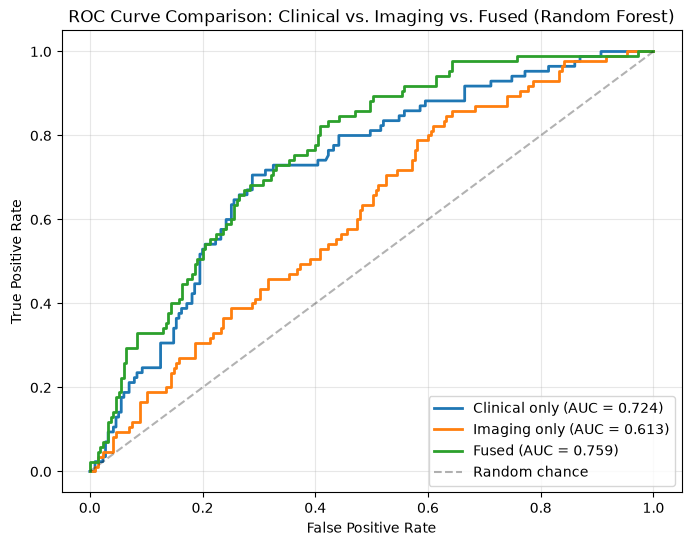

In [3]:
rf_clinical = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_clinical.fit(Xc_train_scaled, yc_train)

rf_imaging = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_imaging.fit(Xi_train_scaled, yi_train)

rf_fused = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_fused.fit(X_train_scaled, y_train)

datasets = {
    'Clinical only': (Xc_test_scaled, yc_test, rf_clinical),
    'Imaging only': (Xi_test_scaled, yi_test, rf_imaging),
    'Fused': (X_test_scaled, y_test, rf_fused)
}

plt.figure(figsize=(8, 6))
for name, (X_te, y_te, model) in datasets.items():
    probs = model.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, probs)
    auc = roc_auc_score(y_te, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Random chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Clinical vs. Imaging vs. Fused (Random Forest)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('roc_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

# Based on your earlier results, your top 5 by ROC-AUC on the fused dataset were:
# RandomForest, AdaBoost, ExtraTrees, LogisticRegression, GradientBoosting

top5_models = {
    'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=20, random_state=42, class_weight='balanced'),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, learning_rate=0.5, random_state=42),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=300, max_depth=20, random_state=42, class_weight='balanced'),
    'LogisticRegression': LogisticRegression(C=0.01, max_iter=1000, class_weight='balanced'),
    'GradientBoosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=42)
}

for name, model in top5_models.items():
    model.fit(X_train_scaled, y_train)

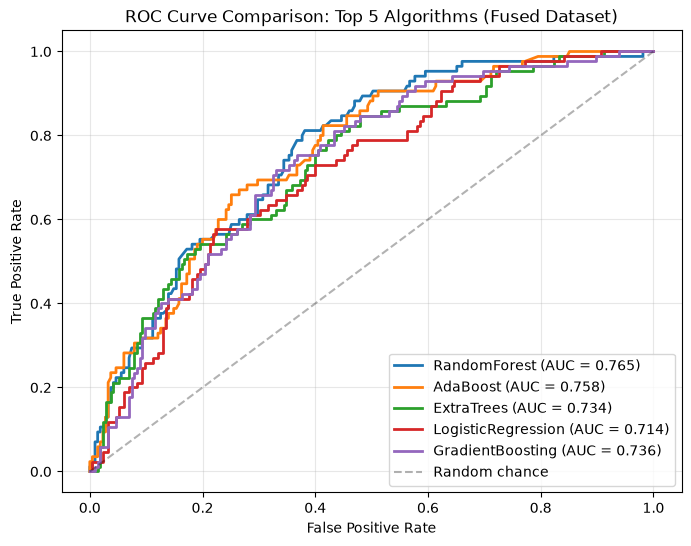

In [5]:
plt.figure(figsize=(8, 6))
for name, model in top5_models.items():
    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Random chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Top 5 Algorithms (Fused Dataset)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('roc_top5_models.png', dpi=300, bbox_inches='tight')
plt.show()

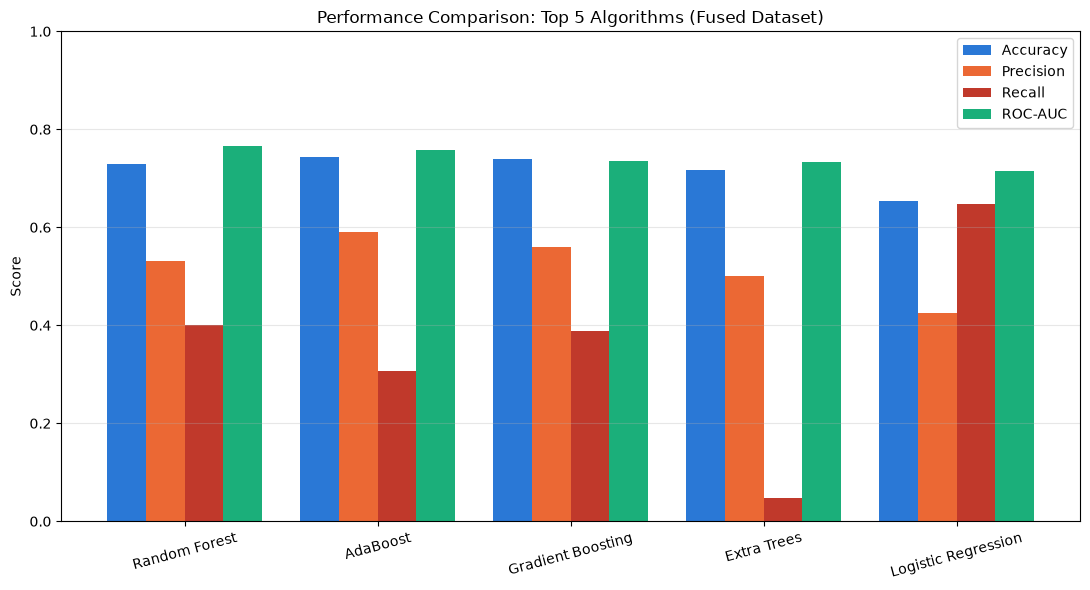

In [6]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Random Forest', 'AdaBoost', 'Gradient Boosting', 'Extra Trees', 'Logistic Regression']
accuracy = [0.730, 0.743, 0.740, 0.717, 0.653]
precision = [0.531, 0.591, 0.559, 0.500, 0.426]
recall = [0.400, 0.306, 0.388, 0.047, 0.647]
roc_auc = [0.765, 0.758, 0.736, 0.734, 0.714]

x = np.arange(len(models))
width = 0.2

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - 1.5*width, accuracy, width, label='Accuracy', color='#2a78d6')
ax.bar(x - 0.5*width, precision, width, label='Precision', color='#eb6834')
ax.bar(x + 0.5*width, recall, width, label='Recall', color='#c0392b')
ax.bar(x + 1.5*width, roc_auc, width, label='ROC-AUC', color='#1baf7a')

ax.set_ylabel('Score')
ax.set_title('Performance Comparison: Top 5 Algorithms (Fused Dataset)')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylim(0, 1)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('top5_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

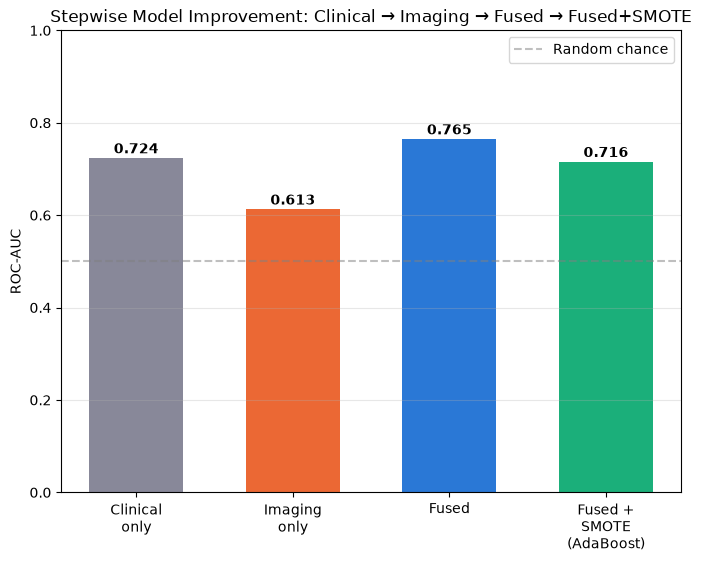

In [7]:
import matplotlib.pyplot as plt

stages = ['Clinical\nonly', 'Imaging\nonly', 'Fused', 'Fused +\nSMOTE\n(AdaBoost)']
auc_values = [0.724, 0.613, 0.765, 0.716]  # Random Forest for first 3, AdaBoost+SMOTE for last

plt.figure(figsize=(8, 6))
bars = plt.bar(stages, auc_values, color=['#889', '#eb6834', '#2a78d6', '#1baf7a'], width=0.6)
for bar, val in zip(bars, auc_values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', ha='center', fontweight='bold')

plt.ylim(0, 1)
plt.ylabel('ROC-AUC')
plt.title('Stepwise Model Improvement: Clinical → Imaging → Fused → Fused+SMOTE')
plt.axhline(0.5, linestyle='--', color='gray', alpha=0.5, label='Random chance')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig('stepwise_auc_progression.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'best_models_all' is not defined

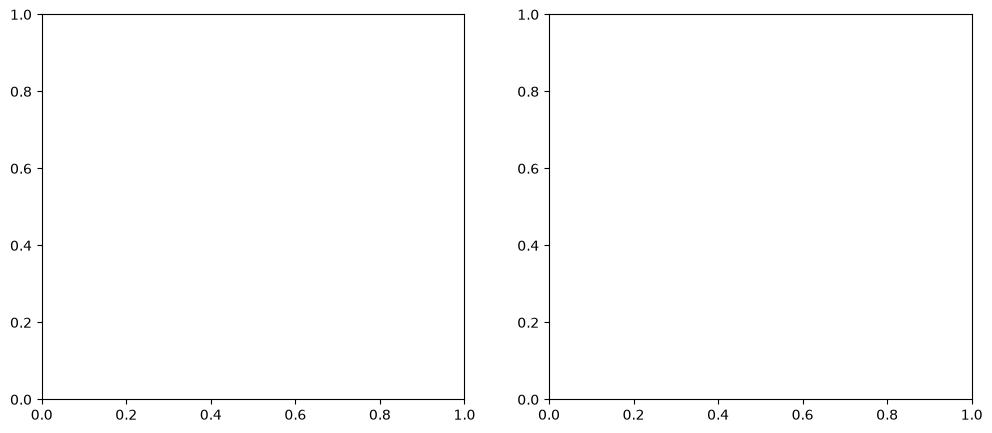

In [8]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Best ROC-AUC model
cm_rf = confusion_matrix(y_test, best_models_all['RandomForest'].predict(X_test_scaled))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Indolent', 'Clinically Sig.'], yticklabels=['Indolent', 'Clinically Sig.'])
axes[0].set_title('Random Forest (Best ROC-AUC)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Best Recall model
cm_lr = confusion_matrix(y_test, best_models_all['LogisticRegression'].predict(X_test_scaled))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Indolent', 'Clinically Sig.'], yticklabels=['Indolent', 'Clinically Sig.'])
axes[1].set_title('Logistic Regression (Best Recall)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('confusion_matrices_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [1]:
papers = ['Woźnicki 2020', 'TRUS Wang 2022', 'Peritumoral 2025', 'Bi-param MRI 2024',
          'Textural 2023', 'Sci.Rep. 2025', 'BMC 2024', 'mpMRI+US 2023', 'MRI+Methylation 2024', 'PI-CAI 2024', 'Your Study']
aucs = [0.688, 0.75, 0.729, 0.64, 0.804, 0.774, 0.968, 0.87, 0.97, 0.898, 0.765]
colors = ['#889']*10 + ['#c0392b']

sorted_pairs = sorted(zip(aucs, papers, colors))
aucs_s, papers_s, colors_s = zip(*sorted_pairs)

plt.figure(figsize=(9,7))
plt.barh(papers_s, aucs_s, color=colors_s)
plt.xlabel('AUC')
plt.title('Ranked AUC Comparison')
plt.xlim(0,1)
plt.tight_layout()
plt.savefig('style2_ranked_bar.png', dpi=300)
plt.show()

NameError: name 'plt' is not defined

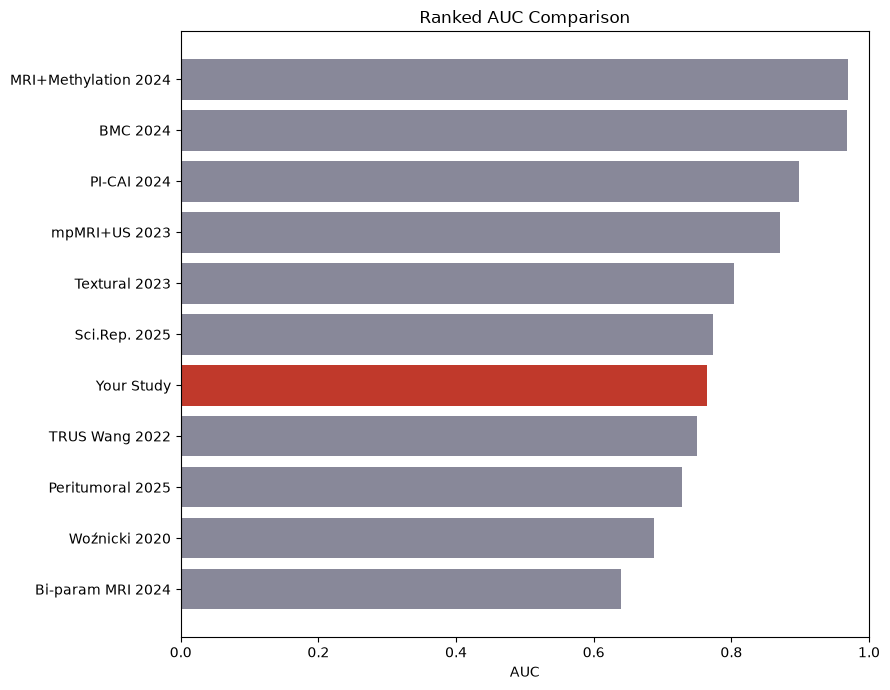

In [2]:
import matplotlib.pyplot as plt

papers = ['Woźnicki 2020', 'TRUS Wang 2022', 'Peritumoral 2025', 'Bi-param MRI 2024',
          'Textural 2023', 'Sci.Rep. 2025', 'BMC 2024', 'mpMRI+US 2023', 'MRI+Methylation 2024', 'PI-CAI 2024', 'Your Study']
aucs = [0.688, 0.75, 0.729, 0.64, 0.804, 0.774, 0.968, 0.87, 0.97, 0.898, 0.765]
colors = ['#889']*10 + ['#c0392b']

sorted_pairs = sorted(zip(aucs, papers, colors))
aucs_s, papers_s, colors_s = zip(*sorted_pairs)

plt.figure(figsize=(9,7))
plt.barh(papers_s, aucs_s, color=colors_s)
plt.xlabel('AUC')
plt.title('Ranked AUC Comparison')
plt.xlim(0,1)
plt.tight_layout()
plt.savefig('style2_ranked_bar.png', dpi=300)
plt.show()

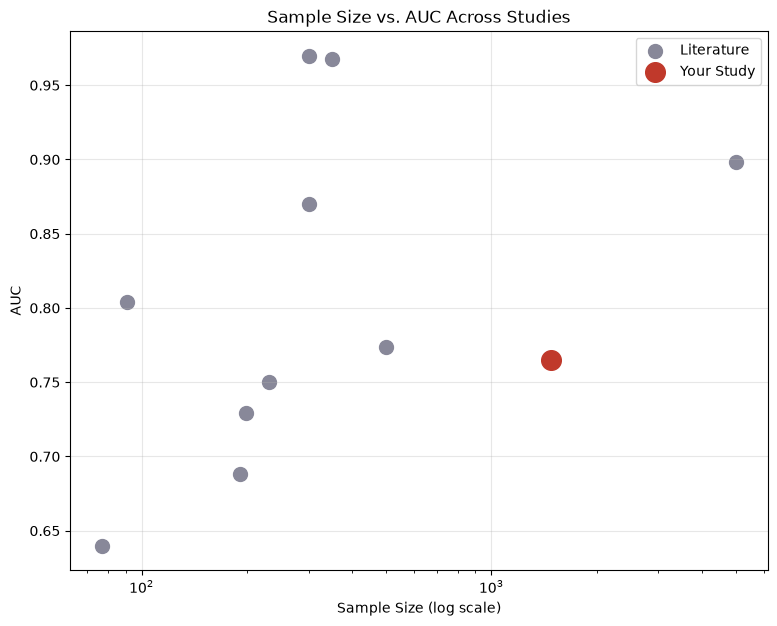

In [3]:
sizes = [191, 231, 199, 77, 91, 500, 350, 300, 300, 5000, 1476]  # estimates where "not specified"
plt.figure(figsize=(9,7))
plt.scatter(sizes[:-1], aucs[:-1], s=100, color='#889', label='Literature')
plt.scatter(sizes[-1], aucs[-1], s=200, color='#c0392b', label='Your Study', zorder=5)
plt.xscale('log')
plt.xlabel('Sample Size (log scale)')
plt.ylabel('AUC')
plt.title('Sample Size vs. AUC Across Studies')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('style3_scatter.png', dpi=300)
plt.show()

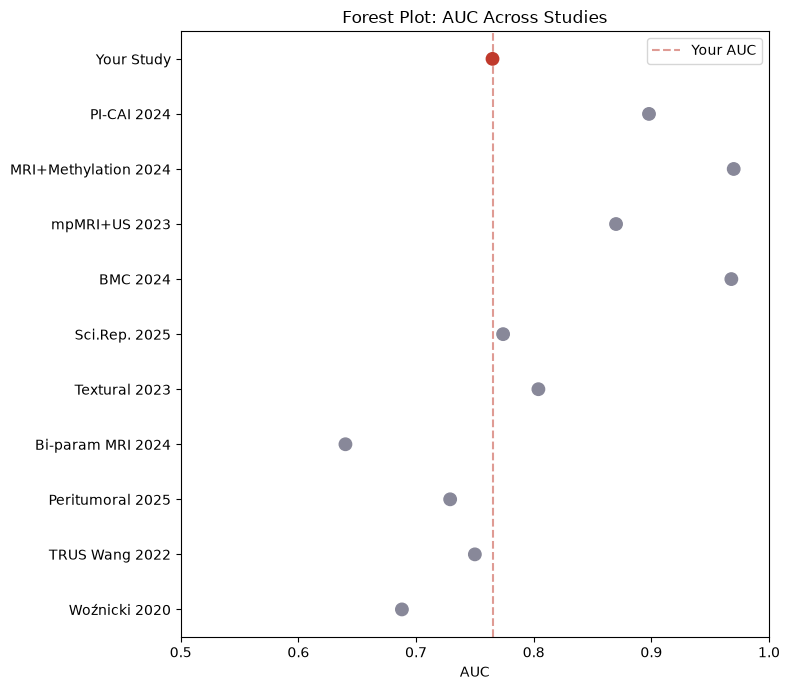

In [4]:
plt.figure(figsize=(8,7))
y_pos = range(len(papers))
plt.scatter(aucs, y_pos, color=colors, s=80, zorder=3)
plt.axvline(0.765, linestyle='--', color='#c0392b', alpha=0.5, label='Your AUC')
plt.yticks(y_pos, papers)
plt.xlabel('AUC')
plt.title('Forest Plot: AUC Across Studies')
plt.xlim(0.5, 1.0)
plt.legend()
plt.tight_layout()
plt.savefig('style4_forest.png', dpi=300)
plt.show()

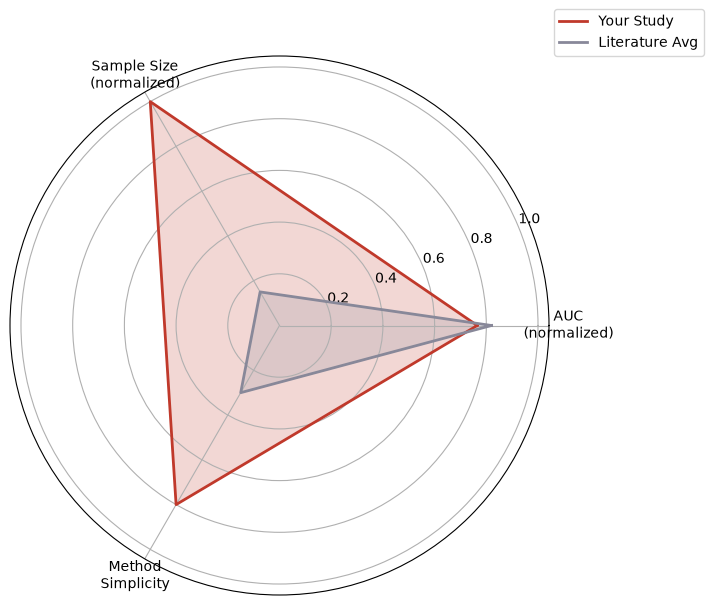

In [5]:
import numpy as np
categories = ['AUC\n(normalized)', 'Sample Size\n(normalized)', 'Method\nSimplicity']
your_vals = [0.765, 1.0, 0.8]  # sample size normalized to max=1
lit_avg_vals = [0.82, 0.15, 0.3]  # rough literature average

angles = np.linspace(0, 2*np.pi, len(categories), endpoint=False).tolist()
your_vals += your_vals[:1]
lit_avg_vals += lit_avg_vals[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7,7), subplot_kw=dict(polar=True))
ax.plot(angles, your_vals, color='#c0392b', linewidth=2, label='Your Study')
ax.fill(angles, your_vals, color='#c0392b', alpha=0.2)
ax.plot(angles, lit_avg_vals, color='#889', linewidth=2, label='Literature Avg')
ax.fill(angles, lit_avg_vals, color='#889', alpha=0.2)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
plt.legend(loc='upper right', bbox_to_anchor=(1.3,1.1))
plt.savefig('style5_radar.png', dpi=300, bbox_inches='tight')
plt.show()

In [1]:
print(best_models_all.keys())
print(X_test_scaled.shape)

NameError: name 'best_models_all' is not defined

In [2]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
base.trainable = False

x = GlobalAveragePooling2D()(base.output)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(1, activation='sigmoid')(x)

resnet_classifier = Model(inputs=base.input, outputs=output)
resnet_classifier.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])
print("Model built successfully")

2026-08-29 11:12:05.042225: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-08-29 11:12:05.042289: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-08-29 11:12:05.042308: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-08-29 11:12:05.042360: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-08-29 11:12:05.042382: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model built successfully


In [3]:
import os
import numpy as np
import pandas as pd

picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')
patient_folders = os.listdir('picai_images')

X_images = []
y_images = []

for i, patient_id in enumerate(patient_folders):
    folder_path = os.path.join('picai_images', patient_id)
    files = os.listdir(folder_path)
    t2w_file = [f for f in files if 't2w' in f.lower()]
    if not t2w_file:
        continue
    mha_path = os.path.join(folder_path, t2w_file[0])
    try:
        slice_rgb = load_middle_slice(mha_path)
        label_row = picai_clinical_clean[picai_clinical_clean['patient_id'] == int(patient_id)]
        if len(label_row) == 0:
            continue
        X_images.append(slice_rgb)
        y_images.append(label_row['csPCa_label'].values[0])
    except Exception as e:
        continue
    if i % 200 == 0:
        print(f"Loaded {i}/{len(patient_folders)}")

X_images = np.array(X_images)
y_images = np.array(y_images)
print("Final shape:", X_images.shape, y_images.shape)

NotADirectoryError: [Errno 20] Not a directory: 'picai_images/.DS_Store'

In [4]:
import os
import numpy as np
import pandas as pd

picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')
patient_folders = [f for f in os.listdir('picai_images') if os.path.isdir(os.path.join('picai_images', f))]

print(f"Found {len(patient_folders)} actual patient folders")

X_images = []
y_images = []

for i, patient_id in enumerate(patient_folders):
    folder_path = os.path.join('picai_images', patient_id)
    files = os.listdir(folder_path)
    t2w_file = [f for f in files if 't2w' in f.lower()]
    if not t2w_file:
        continue
    mha_path = os.path.join(folder_path, t2w_file[0])
    try:
        slice_rgb = load_middle_slice(mha_path)
        label_row = picai_clinical_clean[picai_clinical_clean['patient_id'] == int(patient_id)]
        if len(label_row) == 0:
            continue
        X_images.append(slice_rgb)
        y_images.append(label_row['csPCa_label'].values[0])
    except Exception as e:
        continue
    if i % 200 == 0:
        print(f"Loaded {i}/{len(patient_folders)}")

X_images = np.array(X_images)
y_images = np.array(y_images)
print("Final shape:", X_images.shape, y_images.shape)

Found 1476 actual patient folders
Final shape: (0,) (0,)


In [5]:
sample_patient = patient_folders[0]
folder_path = os.path.join('picai_images', sample_patient)
files = os.listdir(folder_path)
print("Files in folder:", files)

t2w_file = [f for f in files if 't2w' in f.lower()]
print("T2W file found:", t2w_file)

if t2w_file:
    mha_path = os.path.join(folder_path, t2w_file[0])
    slice_rgb = load_middle_slice(mha_path)
    print("Image loaded, shape:", slice_rgb.shape)
    
    label_row = picai_clinical_clean[picai_clinical_clean['patient_id'] == int(sample_patient)]
    print("Label row found:", label_row)

Files in folder: ['10268_1000272_t2w.mha', '10268_1000272_hbv.mha', '10268_1000272_cor.mha', '10268_1000272_adc.mha', '10268_1000272_sag.mha']
T2W file found: ['10268_1000272_t2w.mha']


NameError: name 'load_middle_slice' is not defined

In [6]:
import SimpleITK as sitk
import cv2
import numpy as np

def load_middle_slice(mha_path, target_size=(224, 224)):
    img = sitk.ReadImage(mha_path)
    arr = sitk.GetArrayFromImage(img)
    middle_idx = arr.shape[0] // 2
    slice_2d = arr[middle_idx]
    slice_norm = cv2.normalize(slice_2d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    slice_resized = cv2.resize(slice_norm, target_size)
    slice_rgb = cv2.cvtColor(slice_resized, cv2.COLOR_GRAY2RGB)
    return slice_rgb

print("Function defined")

Function defined


In [7]:
sample_patient = patient_folders[0]
folder_path = os.path.join('picai_images', sample_patient)
files = os.listdir(folder_path)
t2w_file = [f for f in files if 't2w' in f.lower()]
mha_path = os.path.join(folder_path, t2w_file[0])

slice_rgb = load_middle_slice(mha_path)
print("Image loaded, shape:", slice_rgb.shape)

label_row = picai_clinical_clean[picai_clinical_clean['patient_id'] == int(sample_patient)]
print("Label row found:")
print(label_row)

Image loaded, shape: (224, 224, 3)
Label row found:
     patient_id  study_id  patient_age   psa  psad  prostate_volume center  \
272       10268   1000272           76  17.7  0.25             72.0   RUMC   

     csPCa_label  
272            1  


In [8]:
X_images = []
y_images = []

for i, patient_id in enumerate(patient_folders):
    folder_path = os.path.join('picai_images', patient_id)
    files = os.listdir(folder_path)
    t2w_file = [f for f in files if 't2w' in f.lower()]
    if not t2w_file:
        continue
    mha_path = os.path.join(folder_path, t2w_file[0])
    try:
        slice_rgb = load_middle_slice(mha_path)
        label_row = picai_clinical_clean[picai_clinical_clean['patient_id'] == int(patient_id)]
        if len(label_row) == 0:
            continue
        X_images.append(slice_rgb)
        y_images.append(label_row['csPCa_label'].values[0])
    except Exception as e:
        continue
    if i % 200 == 0:
        print(f"Loaded {i}/{len(patient_folders)}")

X_images = np.array(X_images)
y_images = np.array(y_images)
print("Final shape:", X_images.shape, y_images.shape)

Loaded 0/1476
Loaded 200/1476
Loaded 400/1476
Loaded 600/1476
Loaded 800/1476
Loaded 1000/1476
Loaded 1200/1476
Loaded 1400/1476
Final shape: (1476, 224, 224, 3) (1476,)


In [9]:
from sklearn.model_selection import train_test_split

Xi_train_imgs, Xi_test_imgs, yi_train_imgs, yi_test_imgs = train_test_split(
    X_images, y_images, test_size=0.2, stratify=y_images, random_state=42
)

print("Train shape:", Xi_train_imgs.shape)
print("Test shape:", Xi_test_imgs.shape)

history = resnet_classifier.fit(
    Xi_train_imgs, yi_train_imgs,
    validation_data=(Xi_test_imgs, yi_test_imgs),
    epochs=15, batch_size=16
)

Train shape: (1180, 224, 224, 3)
Test shape: (296, 224, 224, 3)
Epoch 1/15


2026-08-29 11:30:16.439927: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


74/74 ━━━━━━━━━━━━━━━━━━━━ 20s 193ms/step - accuracy: 0.6373 - loss: 0.8916 - val_accuracy: 0.6689 - val_loss: 0.7132
Epoch 2/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 10s 142ms/step - accuracy: 0.6669 - loss: 0.7513 - val_accuracy: 0.6689 - val_loss: 0.7302
Epoch 3/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 10s 141ms/step - accuracy: 0.6576 - loss: 0.8478 - val_accuracy: 0.6926 - val_loss: 0.7649
Epoch 4/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 144ms/step - accuracy: 0.6500 - loss: 0.8756 - val_accuracy: 0.6723 - val_loss: 0.6876
Epoch 5/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 144ms/step - accuracy: 0.6475 - loss: 0.8564 - val_accuracy: 0.6858 - val_loss: 0.7495
Epoch 6/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 147ms/step - accuracy: 0.6788 - loss: 0.7784 - val_accuracy: 0.6892 - val_loss: 0.7042
Epoch 7/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 148ms/step - accuracy: 0.6890 - loss: 0.7816 - val_accuracy: 0.6791 - val_loss: 0.6794
Epoch 8/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 0.6568 - loss: 0.7993 - val_accuracy: 0.679

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

probs_resnet = resnet_classifier.predict(Xi_test_imgs).flatten()
preds_resnet = (probs_resnet >= 0.5).astype(int)

print("Accuracy:", accuracy_score(yi_test_imgs, preds_resnet))
print("Precision:", precision_score(yi_test_imgs, preds_resnet))
print("Recall:", recall_score(yi_test_imgs, preds_resnet))
print("F1:", f1_score(yi_test_imgs, preds_resnet))
print("ROC-AUC:", roc_auc_score(yi_test_imgs, probs_resnet))
print()
print("Confusion matrix:")
print(confusion_matrix(yi_test_imgs, preds_resnet))
print()
print("Prediction distribution:", np.bincount(preds_resnet))
print("Actual distribution:", np.bincount(yi_test_imgs))

10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 393ms/step
Accuracy: 0.6891891891891891
Precision: 0.4166666666666667
Recall: 0.23809523809523808
F1: 0.30303030303030304
ROC-AUC: 0.6011343216531896

Confusion matrix:
[[184  28]
 [ 64  20]]

Prediction distribution: [248  48]
Actual distribution: [212  84]


In [11]:
base.trainable = True
for layer in base.layers[:-10]:  # freeze all but the last 10 layers
    layer.trainable = False

resnet_classifier.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])

history = resnet_classifier.fit(
    Xi_train_imgs, yi_train_imgs,
    validation_data=(Xi_test_imgs, yi_test_imgs),
    epochs=15, batch_size=16,
    class_weight={0: 1.0, 1: 2.5}
)

Epoch 1/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 23s 232ms/step - accuracy: 0.6585 - loss: 1.1074 - val_accuracy: 0.6081 - val_loss: 0.7303
Epoch 2/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 12s 161ms/step - accuracy: 0.6415 - loss: 1.0483 - val_accuracy: 0.6115 - val_loss: 0.7394
Epoch 3/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 12s 161ms/step - accuracy: 0.6847 - loss: 0.9748 - val_accuracy: 0.6284 - val_loss: 0.7022
Epoch 4/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 14s 196ms/step - accuracy: 0.6839 - loss: 0.9102 - val_accuracy: 0.6250 - val_loss: 0.7334
Epoch 5/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 17s 236ms/step - accuracy: 0.6780 - loss: 0.9442 - val_accuracy: 0.6385 - val_loss: 0.7139
Epoch 6/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 34s 461ms/step - accuracy: 0.7110 - loss: 0.8470 - val_accuracy: 0.6250 - val_loss: 0.6943
Epoch 7/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 28s 378ms/step - accuracy: 0.7271 - loss: 0.8084 - val_accuracy: 0.6284 - val_loss: 0.7167
Epoch 8/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 23s 310ms/step - accuracy: 0.7585 - loss: 0.7451 - val_accu

In [12]:
probs_resnet_ft = resnet_classifier.predict(Xi_test_imgs).flatten()
preds_resnet_ft = (probs_resnet_ft >= 0.5).astype(int)

print("Accuracy:", accuracy_score(yi_test_imgs, preds_resnet_ft))
print("Precision:", precision_score(yi_test_imgs, preds_resnet_ft))
print("Recall:", recall_score(yi_test_imgs, preds_resnet_ft))
print("F1:", f1_score(yi_test_imgs, preds_resnet_ft))
print("ROC-AUC:", roc_auc_score(yi_test_imgs, probs_resnet_ft))
print()
print("Confusion matrix:")
print(confusion_matrix(yi_test_imgs, preds_resnet_ft))

10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 387ms/step
Accuracy: 0.6891891891891891
Precision: 0.4375
Recall: 0.3333333333333333
F1: 0.3783783783783784
ROC-AUC: 0.6290992812219228

Confusion matrix:
[[176  36]
 [ 56  28]]


In [13]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base_aug = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_aug.trainable = False

x = GlobalAveragePooling2D()(base_aug.output)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(1, activation='sigmoid')(x)

resnet_augmented = Model(inputs=base_aug.input, outputs=output)
resnet_augmented.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
datagen.fit(Xi_train_imgs)

history_aug = resnet_augmented.fit(
    datagen.flow(Xi_train_imgs, yi_train_imgs, batch_size=16),
    validation_data=(Xi_test_imgs, yi_test_imgs),
    epochs=15,
    class_weight={0: 1.0, 1: 2.5}
)

Epoch 1/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 19s 198ms/step - accuracy: 0.4805 - loss: 1.4610 - val_accuracy: 0.6791 - val_loss: 0.6510
Epoch 2/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.5559 - loss: 1.2437 - val_accuracy: 0.6486 - val_loss: 0.6741
Epoch 3/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 146ms/step - accuracy: 0.5907 - loss: 1.1381 - val_accuracy: 0.6453 - val_loss: 0.6759
Epoch 4/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 153ms/step - accuracy: 0.5754 - loss: 1.2709 - val_accuracy: 0.6081 - val_loss: 0.6987
Epoch 5/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 0.5644 - loss: 1.2308 - val_accuracy: 0.6351 - val_loss: 0.6824
Epoch 6/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 14s 190ms/step - accuracy: 0.5746 - loss: 1.2596 - val_accuracy: 0.6892 - val_loss: 0.6192
Epoch 7/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 33s 450ms/step - accuracy: 0.5729 - loss: 1.2878 - val_accuracy: 0.6824 - val_loss: 0.6308
Epoch 8/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 31s 412ms/step - accuracy: 0.5695 - loss: 1.2937 - val_accu

In [15]:
probs_aug = resnet_augmented.predict(Xi_test_imgs).flatten()
preds_aug = (probs_aug >= 0.5).astype(int)

print("Accuracy:", accuracy_score(yi_test_imgs, preds_aug))
print("Precision:", precision_score(yi_test_imgs, preds_aug))
print("Recall:", recall_score(yi_test_imgs, preds_aug))
print("F1:", f1_score(yi_test_imgs, preds_aug))
print("ROC-AUC:", roc_auc_score(yi_test_imgs, probs_aug))
print()
print("Confusion matrix:")
print(confusion_matrix(yi_test_imgs, preds_aug))

10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 418ms/step
Accuracy: 0.6114864864864865
Precision: 0.3798449612403101
Recall: 0.5833333333333334
F1: 0.460093896713615
ROC-AUC: 0.6561096136567834

Confusion matrix:
[[132  80]
 [ 35  49]]


In [16]:
print(best_models_all.keys())
print(X_train_scaled.shape)

NameError: name 'best_models_all' is not defined

In [17]:
 import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

fused_df_reload = pd.read_csv('fused_final_dataset.csv')
X_fused = fused_df_reload.drop(columns=['patient_id', 'csPCa_label'], errors='ignore')
y_fused = fused_df_reload['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(X_fused, y_fused, test_size=0.2, stratify=y_fused, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
    'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
    'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
    'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
    'NaiveBayes': (GaussianNB(), {}),
    'LDA': (LinearDiscriminantAnalysis(), {}),
    'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]})
}

best_models_all = {}
for name, (model, params) in models_params.items():
    if params:
        grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        grid.fit(X_train_scaled, y_train)
        best_models_all[name] = grid.best_estimator_
    else:
        model.fit(X_train_scaled, y_train)
        best_models_all[name] = model
    print(f"{name} trained")

print("All models rebuilt successfully")

IndentationError: unexpected indent (1363506783.py, line 1)

In [18]:
import pandas as pd
print("test")

test


In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

fused_df_reload = pd.read_csv('fused_final_dataset.csv')
X_fused = fused_df_reload.drop(columns=['patient_id', 'csPCa_label'], errors='ignore')
y_fused = fused_df_reload['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(X_fused, y_fused, test_size=0.2, stratify=y_fused, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
    'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
    'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
    'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
    'NaiveBayes': (GaussianNB(), {}),
    'LDA': (LinearDiscriminantAnalysis(), {}),
    'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]})
}

best_models_all = {}
for name, (model, params) in models_params.items():
    if params:
        grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        grid.fit(X_train_scaled, y_train)
        best_models_all[name] = grid.best_estimator_
    else:
        model.fit(X_train_scaled, y_train)
        best_models_all[name] = model
    print(f"{name} trained")

print("All models rebuilt successfully")

LogisticRegression trained
DecisionTree trained
RandomForest trained
ExtraTrees trained
GradientBoosting trained
AdaBoost trained


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM trained
KNN trained
NaiveBayes trained
LDA trained
MLP trained
All models rebuilt successfully


In [20]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=2.5,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train_scaled, y_train)

xgb_preds = xgb_model.predict(X_test_scaled)
xgb_probs = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("=== XGBoost ===")
print("Accuracy:", accuracy_score(y_test, xgb_preds))
print("Precision:", precision_score(y_test, xgb_preds))
print("Recall:", recall_score(y_test, xgb_preds))
print("F1:", f1_score(y_test, xgb_preds))
print("ROC-AUC:", roc_auc_score(y_test, xgb_probs))

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <1A0D8152-BF46-3BE0-B651-EE965C187777> ~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/li

In [22]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=2.5,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train_scaled, y_train)

xgb_preds = xgb_model.predict(X_test_scaled)
xgb_probs = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("=== XGBoost ===")
print("Accuracy:", accuracy_score(y_test, xgb_preds))
print("Precision:", precision_score(y_test, xgb_preds))
print("Recall:", recall_score(y_test, xgb_preds))
print("F1:", f1_score(y_test, xgb_preds))
print("ROC-AUC:", roc_auc_score(y_test, xgb_probs))


=== XGBoost ===
Accuracy: 0.7466666666666667
Precision: 0.5671641791044776
Recall: 0.4470588235294118
F1: 0.5
ROC-AUC: 0.7580300957592339


In [23]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

estimators = [
    ('rf', best_models_all['RandomForest']),
    ('ada', best_models_all['AdaBoost']),
    ('gb', best_models_all['GradientBoosting'])
]

stacked_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(class_weight='balanced'),
    cv=5
)
stacked_model.fit(X_train_scaled, y_train)

stacked_preds = stacked_model.predict(X_test_scaled)
stacked_probs = stacked_model.predict_proba(X_test_scaled)[:, 1]

print("=== Stacking Ensemble ===")
print("Accuracy:", accuracy_score(y_test, stacked_preds))
print("Precision:", precision_score(y_test, stacked_preds))
print("Recall:", recall_score(y_test, stacked_preds))
print("F1:", f1_score(y_test, stacked_preds))
print("ROC-AUC:", roc_auc_score(y_test, stacked_probs))

=== Stacking Ensemble ===
Accuracy: 0.6766666666666666
Precision: 0.453125
Recall: 0.6823529411764706
F1: 0.5446009389671361
ROC-AUC: 0.7630642954856361


In [24]:
print(xgb_model)
print(X_train_scaled.shape)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)
(1200, 104)


In [25]:
import numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score

best_acc, best_thresh = 0, 0.5
for t in np.arange(0.1, 0.9, 0.01):
    preds = (xgb_probs >= t).astype(int)
    acc = accuracy_score(y_test, preds)
    if acc > best_acc:
        best_acc, best_thresh = acc, t

print(f"Best threshold: {best_thresh:.2f}, Accuracy: {best_acc:.4f}")

best_preds = (xgb_probs >= best_thresh).astype(int)
print(f"Recall at this threshold: {recall_score(y_test, best_preds):.4f}")
print(f"Precision at this threshold: {precision_score(y_test, best_preds):.4f}")

Best threshold: 0.74, Accuracy: 0.7600
Recall at this threshold: 0.3176
Precision at this threshold: 0.6585


In [26]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

xgb_params = {
    'n_estimators': [200, 300, 500],
    'max_depth': [3, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
    xgb_params, cv=5, scoring='accuracy', n_jobs=-1
)
xgb_grid.fit(X_train_scaled, y_train)

print("Best params:", xgb_grid.best_params_)
print("Best CV accuracy:", xgb_grid.best_score_)

best_xgb = xgb_grid.best_estimator_
best_xgb_preds = best_xgb.predict(X_test_scaled)
best_xgb_probs = best_xgb.predict_proba(X_test_scaled)[:, 1]

print("\n=== Tuned XGBoost (test set) ===")
print("Accuracy:", accuracy_score(y_test, best_xgb_preds))
print("Precision:", precision_score(y_test, best_xgb_preds))
print("Recall:", recall_score(y_test, best_xgb_preds))
print("ROC-AUC:", roc_auc_score(y_test, best_xgb_probs))

Best params: {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.8}
Best CV accuracy: 0.7566666666666666

=== Tuned XGBoost (test set) ===
Accuracy: 0.7366666666666667
Precision: 0.5375
Recall: 0.5058823529411764
ROC-AUC: 0.774172366621067


In [27]:
xgb_params_v2 = {
    'n_estimators': [100, 200, 300, 500, 800],
    'max_depth': [3, 4, 5, 6, 8, 10],
    'learning_rate': [0.005, 0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.5]
}

In [28]:
from sklearn.model_selection import RandomizedSearchCV

xgb_random = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
    xgb_params_v2, n_iter=100, cv=5, scoring='roc_auc', n_jobs=-1, random_state=42
)
xgb_random.fit(X_train_scaled, y_train)
print("Best params:", xgb_random.best_params_)
print("Best CV ROC-AUC:", xgb_random.best_score_)

Best params: {'subsample': 1.0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 1.0}
Best CV ROC-AUC: 0.7528984268125856


In [29]:
print(X_train_scaled.shape)
print(y_train.shape)

(1200, 104)
(1200,)


In [30]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

xgb_params_v2 = {
    'n_estimators': [100, 200, 300, 500, 800],
    'max_depth': [3, 4, 5, 6, 8, 10],
    'learning_rate': [0.005, 0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.5]
}

xgb_random = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
    xgb_params_v2, n_iter=100, cv=5, scoring='roc_auc', n_jobs=-1, random_state=42
)
xgb_random.fit(X_train_scaled, y_train)

print("Best params:", xgb_random.best_params_)
print("Best CV ROC-AUC:", xgb_random.best_score_)

Best params: {'subsample': 1.0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 1.0}
Best CV ROC-AUC: 0.7528984268125856


In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

best_xgb_v2 = xgb_random.best_estimator_
preds_v2 = best_xgb_v2.predict(X_test_scaled)
probs_v2 = best_xgb_v2.predict_proba(X_test_scaled)[:, 1]

print("=== Widened RandomizedSearch XGBoost (test set) ===")
print("Accuracy:", accuracy_score(y_test, preds_v2))
print("Precision:", precision_score(y_test, preds_v2))
print("Recall:", recall_score(y_test, preds_v2))
print("F1:", f1_score(y_test, preds_v2))
print("ROC-AUC:", roc_auc_score(y_test, probs_v2))

=== Widened RandomizedSearch XGBoost (test set) ===
Accuracy: 0.68
Precision: 0.452991452991453
Recall: 0.6235294117647059
F1: 0.5247524752475248
ROC-AUC: 0.7419425444596444


In [32]:
print(picai_clinical_clean['center'].value_counts())

center
RUMC    800
PCNN    350
ZGT     350
Name: count, dtype: int64


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

fused_df_reload = pd.read_csv('fused_final_dataset.csv')
# Merge center info back in, since it's not currently in your fused dataset
fused_with_center = fused_df_reload.merge(
    picai_clinical_clean[['patient_id', 'center']], on='patient_id', how='left'
)

centers = ['RUMC', 'PCNN', 'ZGT']
loco_results = []

for held_out in centers:
    train_data = fused_with_center[fused_with_center['center'] != held_out]
    test_data = fused_with_center[fused_with_center['center'] == held_out]
    
    X_train_loco = train_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_train_loco = train_data['csPCa_label']
    X_test_loco = test_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_test_loco = test_data['csPCa_label']
    
    scaler_loco = StandardScaler()
    X_train_loco_scaled = scaler_loco.fit_transform(X_train_loco)
    X_test_loco_scaled = scaler_loco.transform(X_test_loco)
    
    model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
    model.fit(X_train_loco_scaled, y_train_loco)
    
    preds = model.predict(X_test_loco_scaled)
    probs = model.predict_proba(X_test_loco_scaled)[:, 1]
    
    loco_results.append({
        'Held-out center': held_out,
        'Train size': len(train_data),
        'Test size': len(test_data),
        'Accuracy': accuracy_score(y_test_loco, preds),
        'Precision': precision_score(y_test_loco, preds),
        'Recall': recall_score(y_test_loco, preds),
        'ROC-AUC': roc_auc_score(y_test_loco, probs)
    })

loco_df = pd.DataFrame(loco_results)
print(loco_df)

  Held-out center  Train size  Test size  Accuracy  Precision    Recall  \
0            RUMC         734        816  0.740196   0.662500  0.222689   
1            PCNN        1174        376  0.632979   0.407407  0.486726   
2             ZGT        1192        358  0.776536   0.500000  0.600000   

    ROC-AUC  
0  0.723678  
1  0.594872  
2  0.756745  


In [34]:
diagnostic_cols = ['patient_age', 'psa', 'psad', 'prostate_volume', 'csPCa_label']
for center in ['RUMC', 'PCNN', 'ZGT']:
    subset = picai_clinical_clean[picai_clinical_clean['center'] == center]
    print(f"--- {center} (n={len(subset)}) ---")
    print(subset[diagnostic_cols].describe().loc[['mean', 'std']])
    print(f"csPCa positive rate: {subset['csPCa_label'].mean():.3f}")
    print()

--- RUMC (n=800) ---
      patient_age        psa      psad  prostate_volume  csPCa_label
mean    64.568750  11.955075  0.208554        70.740225     0.295000
std      7.128555  12.321014  0.331247        36.761970     0.456328
csPCa positive rate: 0.295

--- PCNN (n=350) ---
      patient_age        psa      psad  prostate_volume  csPCa_label
mean    66.888571  12.388971  0.261769        58.257143     0.311429
std      6.778665  16.805598  0.439292        34.503389     0.463741
csPCa positive rate: 0.311

--- ZGT (n=350) ---
      patient_age        psa      psad  prostate_volume  csPCa_label
mean    66.648571  11.031714  0.263005        58.196571     0.228571
std      7.391968  17.416685  0.610991        34.008173     0.420514
csPCa positive rate: 0.229



In [35]:
def run_loco_with_domain_adaptation(held_out):
    train_data = fused_with_center[fused_with_center['center'] != held_out]
    test_data = fused_with_center[fused_with_center['center'] == held_out]
    
    X_train_loco = train_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_train_loco = train_data['csPCa_label']
    X_test_loco = test_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_test_loco = test_data['csPCa_label']
    
    # Scale train and test SEPARATELY using their own statistics (no label leakage)
    scaler_train = StandardScaler()
    X_train_scaled = scaler_train.fit_transform(X_train_loco)
    
    scaler_test = StandardScaler()
    X_test_scaled = scaler_test.fit_transform(X_test_loco)  # fit on test features only, not labels
    
    model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
    model.fit(X_train_scaled, y_train_loco)
    
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    
    return {
        'Held-out center': held_out,
        'Accuracy': accuracy_score(y_test_loco, preds),
        'Precision': precision_score(y_test_loco, preds),
        'Recall': recall_score(y_test_loco, preds),
        'ROC-AUC': roc_auc_score(y_test_loco, probs)
    }

domain_adapted_results = pd.DataFrame([run_loco_with_domain_adaptation(c) for c in ['RUMC', 'PCNN', 'ZGT']])
print(domain_adapted_results)

  Held-out center  Accuracy  Precision    Recall   ROC-AUC
0            RUMC  0.745098   0.619048  0.327731  0.752239
1            PCNN  0.656915   0.414894  0.345133  0.610855
2             ZGT  0.801676   0.558442  0.537500  0.762095


In [36]:
def run_loco_xgboost(held_out):
    train_data = fused_with_center[fused_with_center['center'] != held_out]
    test_data = fused_with_center[fused_with_center['center'] == held_out]
    
    X_train_loco = train_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_train_loco = train_data['csPCa_label']
    X_test_loco = test_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_test_loco = test_data['csPCa_label']
    
    scaler_train = StandardScaler()
    X_train_scaled = scaler_train.fit_transform(X_train_loco)
    scaler_test = StandardScaler()
    X_test_scaled = scaler_test.fit_transform(X_test_loco)
    
    model = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.01, subsample=0.8,
                            scale_pos_weight=2.5, random_state=42, eval_metric='logloss')
    model.fit(X_train_scaled, y_train_loco)
    
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    
    return {
        'Held-out center': held_out,
        'Accuracy': accuracy_score(y_test_loco, preds),
        'Recall': recall_score(y_test_loco, preds),
        'ROC-AUC': roc_auc_score(y_test_loco, probs)
    }

xgb_loco_results = pd.DataFrame([run_loco_xgboost(c) for c in ['RUMC', 'PCNN', 'ZGT']])
print(xgb_loco_results)

  Held-out center  Accuracy    Recall   ROC-AUC
0            RUMC  0.723039  0.310924  0.734574
1            PCNN  0.664894  0.336283  0.612975
2             ZGT  0.776536  0.437500  0.757149


In [37]:
def run_loco_isolated(held_out, feature_type):
    train_data = fused_with_center[fused_with_center['center'] != held_out]
    test_data = fused_with_center[fused_with_center['center'] == held_out]
    
    if feature_type == 'clinical':
        cols = ['patient_age', 'psa', 'psad', 'prostate_volume']
    else:
        cols = [c for c in fused_with_center.columns if c.startswith('cnn_pca_')]
    
    X_train_loco = train_data[cols]
    y_train_loco = train_data['csPCa_label']
    X_test_loco = test_data[cols]
    y_test_loco = test_data['csPCa_label']
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_loco)
    X_test_scaled = scaler.transform(X_test_loco)
    
    model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
    model.fit(X_train_scaled, y_train_loco)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    
    return roc_auc_score(y_test_loco, probs)

print("Clinical-only LOCO AUC:")
for c in ['RUMC', 'PCNN', 'ZGT']:
    print(f"  {c}: {run_loco_isolated(c, 'clinical'):.3f}")

print("\nImaging-only LOCO AUC:")
for c in ['RUMC', 'PCNN', 'ZGT']:
    print(f"  {c}: {run_loco_isolated(c, 'imaging'):.3f}")

Clinical-only LOCO AUC:
  RUMC: 0.676
  PCNN: 0.617
  ZGT: 0.695

Imaging-only LOCO AUC:
  RUMC: 0.576
  PCNN: 0.521
  ZGT: 0.601


In [38]:
print("Comparing fused vs clinical-only across all centers:")
for c in ['RUMC', 'PCNN', 'ZGT']:
    clin_auc = run_loco_isolated(c, 'clinical')
    print(f"{c}: clinical-only AUC = {clin_auc:.3f}")

Comparing fused vs clinical-only across all centers:
RUMC: clinical-only AUC = 0.676
PCNN: clinical-only AUC = 0.617
ZGT: clinical-only AUC = 0.695


In [39]:
def run_loco_with_domain_adaptation(held_out):
    train_data = fused_with_center[fused_with_center['center'] != held_out]
    test_data = fused_with_center[fused_with_center['center'] == held_out]
    
    X_train_loco = train_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_train_loco = train_data['csPCa_label']
    X_test_loco = test_data.drop(columns=['patient_id', 'csPCa_label', 'center'])
    y_test_loco = test_data['csPCa_label']
    
    # Scale train and test SEPARATELY using their own feature statistics
    scaler_train = StandardScaler()
    X_train_scaled = scaler_train.fit_transform(X_train_loco)
    
    scaler_test = StandardScaler()
    X_test_scaled = scaler_test.fit_transform(X_test_loco)
    
    model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
    model.fit(X_train_scaled, y_train_loco)
    
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    
    return {
        'Held-out center': held_out,
        'Accuracy': accuracy_score(y_test_loco, preds),
        'Precision': precision_score(y_test_loco, preds),
        'Recall': recall_score(y_test_loco, preds),
        'ROC-AUC': roc_auc_score(y_test_loco, probs)
    }

domain_adapted_results = pd.DataFrame([run_loco_with_domain_adaptation(c) for c in ['RUMC', 'PCNN', 'ZGT']])
print(domain_adapted_results)

  Held-out center  Accuracy  Precision    Recall   ROC-AUC
0            RUMC  0.745098   0.619048  0.327731  0.752239
1            PCNN  0.656915   0.414894  0.345133  0.610855
2             ZGT  0.801676   0.558442  0.537500  0.762095


In [40]:
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

# PIRADS can be comma-separated for multiple lesions (e.g. "4" or "3,2") — take the MAX score per case
def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)
print(picai_raw['max_pirads'].value_counts(dropna=False))

max_pirads
2    479
5    381
4    352
3    151
1    137
Name: count, dtype: int64


In [41]:
fused_with_pirads = fused_df_reload.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_pirads['max_pirads'] = fused_with_pirads['max_pirads'].fillna(fused_with_pirads['max_pirads'].median())

X_pirads = fused_with_pirads.drop(columns=['patient_id', 'csPCa_label'])
y_pirads = fused_with_pirads['csPCa_label']

Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_pirads, y_pirads, test_size=0.2, stratify=y_pirads, random_state=42)
scaler_p = StandardScaler()
Xp_train_scaled = scaler_p.fit_transform(Xp_train)
Xp_test_scaled = scaler_p.transform(Xp_test)

rf_pirads = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_pirads.fit(Xp_train_scaled, yp_train)

preds_p = rf_pirads.predict(Xp_test_scaled)
probs_p = rf_pirads.predict_proba(Xp_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(yp_test, preds_p))
print("Recall:", recall_score(yp_test, preds_p))
print("ROC-AUC:", roc_auc_score(yp_test, probs_p))

Accuracy: 0.8333333333333334
Recall: 0.7764705882352941
ROC-AUC: 0.8891928864569083


In [42]:
# Train clinical-only model
clinical_model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
clinical_model.fit(Xc_train_scaled, yc_train)
clinical_probs = clinical_model.predict_proba(Xc_test_scaled)[:, 1]

# Train imaging-only model
imaging_model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
imaging_model.fit(Xi_train_scaled, yi_train)
imaging_probs = imaging_model.predict_proba(Xi_test_scaled)[:, 1]

# Combine via simple averaging (basic late fusion)
late_fusion_probs_avg = (clinical_probs + imaging_probs) / 2
late_fusion_preds_avg = (late_fusion_probs_avg >= 0.5).astype(int)

print("=== Late Fusion (Simple Average) ===")
print("Accuracy:", accuracy_score(y_test, late_fusion_preds_avg))
print("Recall:", recall_score(y_test, late_fusion_preds_avg))
print("ROC-AUC:", roc_auc_score(y_test, late_fusion_probs_avg))

# Combine via a learned meta-combiner (weighted late fusion — more sophisticated)
meta_features_train = np.column_stack([
    clinical_model.predict_proba(Xc_train_scaled)[:, 1],
    imaging_model.predict_proba(Xi_train_scaled)[:, 1]
])
meta_features_test = np.column_stack([clinical_probs, imaging_probs])

meta_combiner = LogisticRegression(class_weight='balanced')
meta_combiner.fit(meta_features_train, yc_train)  # y is same across both since same patients

late_fusion_preds_learned = meta_combiner.predict(meta_features_test)
late_fusion_probs_learned = meta_combiner.predict_proba(meta_features_test)[:, 1]

print("\n=== Late Fusion (Learned Combiner) ===")
print("Accuracy:", accuracy_score(y_test, late_fusion_preds_learned))
print("Recall:", recall_score(y_test, late_fusion_preds_learned))
print("ROC-AUC:", roc_auc_score(y_test, late_fusion_probs_learned))

NameError: name 'Xc_train_scaled' is not defined

In [43]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Load the fused dataset (contains clinical + imaging PCA columns together)
fused_df_reload = pd.read_csv('fused_final_dataset.csv')

clinical_cols = ['patient_age', 'psa', 'psad', 'prostate_volume']
imaging_cols = [c for c in fused_df_reload.columns if c.startswith('cnn_pca_')]

X_all = fused_df_reload.drop(columns=['patient_id', 'csPCa_label'], errors='ignore')
y_all = fused_df_reload['csPCa_label']

# ONE split, used for everything below — guarantees row alignment
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)

# Slice out clinical-only and imaging-only views from the SAME split
Xc_train, Xc_test = X_train_full[clinical_cols], X_test_full[clinical_cols]
Xi_train, Xi_test = X_train_full[imaging_cols], X_test_full[imaging_cols]

# Scale each view separately
scaler_full = StandardScaler()
X_train_scaled = scaler_full.fit_transform(X_train_full)
X_test_scaled = scaler_full.transform(X_test_full)

scaler_c = StandardScaler()
Xc_train_scaled = scaler_c.fit_transform(Xc_train)
Xc_test_scaled = scaler_c.transform(Xc_test)

scaler_i = StandardScaler()
Xi_train_scaled = scaler_i.fit_transform(Xi_train)
Xi_test_scaled = scaler_i.transform(Xi_test)

print("Full:", X_train_scaled.shape, X_test_scaled.shape)
print("Clinical:", Xc_train_scaled.shape, Xc_test_scaled.shape)
print("Imaging:", Xi_train_scaled.shape, Xi_test_scaled.shape)
print("Alignment check — same y_train/y_test used for all three views")

Full: (1200, 104) (300, 104)
Clinical: (1200, 4) (300, 4)
Imaging: (1200, 100) (300, 100)
Alignment check — same y_train/y_test used for all three views


In [44]:
clinical_model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
clinical_model.fit(Xc_train_scaled, y_train)
clinical_probs = clinical_model.predict_proba(Xc_test_scaled)[:, 1]

imaging_model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
imaging_model.fit(Xi_train_scaled, y_train)
imaging_probs = imaging_model.predict_proba(Xi_test_scaled)[:, 1]

late_fusion_probs_avg = (clinical_probs + imaging_probs) / 2
late_fusion_preds_avg = (late_fusion_probs_avg >= 0.5).astype(int)

print("=== Late Fusion (Simple Average) ===")
print("Accuracy:", accuracy_score(y_test, late_fusion_preds_avg))
print("Recall:", recall_score(y_test, late_fusion_preds_avg))
print("ROC-AUC:", roc_auc_score(y_test, late_fusion_probs_avg))

meta_features_train = np.column_stack([
    clinical_model.predict_proba(Xc_train_scaled)[:, 1],
    imaging_model.predict_proba(Xi_train_scaled)[:, 1]
])
meta_features_test = np.column_stack([clinical_probs, imaging_probs])

meta_combiner = LogisticRegression(class_weight='balanced')
meta_combiner.fit(meta_features_train, y_train)

late_fusion_preds_learned = meta_combiner.predict(meta_features_test)
late_fusion_probs_learned = meta_combiner.predict_proba(meta_features_test)[:, 1]

print("\n=== Late Fusion (Learned Combiner) ===")
print("Accuracy:", accuracy_score(y_test, late_fusion_preds_learned))
print("Recall:", recall_score(y_test, late_fusion_preds_learned))
print("ROC-AUC:", roc_auc_score(y_test, late_fusion_probs_learned))

=== Late Fusion (Simple Average) ===
Accuracy: 0.7033333333333334
Recall: 0.5411764705882353
ROC-AUC: 0.7263474692202462

=== Late Fusion (Learned Combiner) ===
Accuracy: 0.7
Recall: 0.3411764705882353
ROC-AUC: 0.7270588235294118


In [45]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Concatenate, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

clinical_input = Input(shape=(Xc_train_scaled.shape[1],), name='clinical_input')
c = Dense(16, activation='relu')(clinical_input)
c = Dropout(0.2)(c)

imaging_input = Input(shape=(Xi_train_scaled.shape[1],), name='imaging_input')
i = Dense(64, activation='relu')(imaging_input)
i = Dropout(0.3)(i)
i = Dense(32, activation='relu')(i)

merged = Concatenate()([c, i])
m = Dense(32, activation='relu')(merged)
m = Dropout(0.3)(m)
output = Dense(1, activation='sigmoid')(m)

intermediate_model = Model(inputs=[clinical_input, imaging_input], outputs=output)
intermediate_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

history_intermediate = intermediate_model.fit(
    [Xc_train_scaled, Xi_train_scaled], y_train,
    validation_data=([Xc_test_scaled, Xi_test_scaled], y_test),
    epochs=30, batch_size=32,
    class_weight={0: 1.0, 1: 2.5}
)

Epoch 1/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4983 - loss: 1.4838 - val_accuracy: 0.5700 - val_loss: 0.7089
Epoch 2/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5558 - loss: 1.0992 - val_accuracy: 0.6133 - val_loss: 0.7084
Epoch 3/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6000 - loss: 1.0174 - val_accuracy: 0.6233 - val_loss: 0.7049
Epoch 4/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6192 - loss: 0.9845 - val_accuracy: 0.6333 - val_loss: 0.7056
Epoch 5/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6075 - loss: 0.9793 - val_accuracy: 0.6567 - val_loss: 0.7130
Epoch 6/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6525 - loss: 0.9377 - val_accuracy: 0.6600 - val_loss: 0.7175
Epoch 7/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6333 - loss: 0.9276 - val_accuracy: 0.6700 - val_loss: 0.7203
Epoch 8/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6558 - loss: 0.9572 - val_accuracy: 0.6667 - v

In [46]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

probs_intermediate = intermediate_model.predict([Xc_test_scaled, Xi_test_scaled]).flatten()
preds_intermediate = (probs_intermediate >= 0.5).astype(int)

print("=== Intermediate Fusion ===")
print("Accuracy:", accuracy_score(y_test, preds_intermediate))
print("Recall:", recall_score(y_test, preds_intermediate))
print("ROC-AUC:", roc_auc_score(y_test, probs_intermediate))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
=== Intermediate Fusion ===
Accuracy: 0.6866666666666666
Recall: 0.6470588235294118
ROC-AUC: 0.7328043775649796


In [47]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

t2w_features_df = pd.read_csv('cnn_features_t2w.csv')
adc_features_df = pd.read_csv('cnn_features_adc.csv')
hbv_features_df = pd.read_csv('cnn_features_hbv.csv')

def reduce_sequence(df, feat_prefix, output_prefix, n_components=35):
    feat_cols = [c for c in df.columns if c.startswith(feat_prefix)]
    X = df[feat_cols]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    pca_cols = [f'{output_prefix}_pca_{i}' for i in range(n_components)]
    result_df = pd.DataFrame(X_pca, columns=pca_cols)
    result_df['patient_id'] = df['patient_id'].astype(int).values
    return result_df

t2w_pca_df = reduce_sequence(t2w_features_df, 'cnn_feat_', 't2w')
adc_pca_df = reduce_sequence(adc_features_df, 'adc_feat_', 'adc')
hbv_pca_df = reduce_sequence(hbv_features_df, 'hbv_feat_', 'hbv')

imaging_combined = t2w_pca_df.merge(adc_pca_df, on='patient_id', how='inner').merge(hbv_pca_df, on='patient_id', how='inner')
print("Multiparametric imaging shape:", imaging_combined.shape)

Multiparametric imaging shape: (1476, 106)


In [48]:
picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)

fused_mp_pirads = picai_clinical_clean.merge(imaging_combined, on='patient_id', how='inner')
fused_mp_pirads = fused_mp_pirads.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_mp_pirads['max_pirads'] = fused_mp_pirads['max_pirads'].fillna(fused_mp_pirads['max_pirads'].median())

print("Final dataset shape:", fused_mp_pirads.shape)

Final dataset shape: (1500, 114)


In [49]:
X_mp_pirads = fused_mp_pirads.drop(columns=['patient_id', 'csPCa_label', 'center'], errors='ignore')
y_mp_pirads = fused_mp_pirads['csPCa_label']

Xmp_train, Xmp_test, ymp_train, ymp_test = train_test_split(
    X_mp_pirads, y_mp_pirads, test_size=0.2, stratify=y_mp_pirads, random_state=42
)

scaler_mp = StandardScaler()
Xmp_train_scaled = scaler_mp.fit_transform(Xmp_train)
Xmp_test_scaled = scaler_mp.transform(Xmp_test)

rf_mp_pirads = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_mp_pirads.fit(Xmp_train_scaled, ymp_train)

preds_mp_p = rf_mp_pirads.predict(Xmp_test_scaled)
probs_mp_p = rf_mp_pirads.predict_proba(Xmp_test_scaled)[:, 1]

print("=== Multiparametric (T2W+ADC+HBV) + Clinical + PI-RADS ===")
print("Accuracy:", accuracy_score(ymp_test, preds_mp_p))
print("Precision:", precision_score(ymp_test, preds_mp_p))
print("Recall:", recall_score(ymp_test, preds_mp_p))
print("F1:", f1_score(ymp_test, preds_mp_p))
print("ROC-AUC:", roc_auc_score(ymp_test, probs_mp_p))

=== Multiparametric (T2W+ADC+HBV) + Clinical + PI-RADS ===
Accuracy: 0.8266666666666667
Precision: 0.6666666666666666
Recall: 0.7764705882352941
F1: 0.717391304347826
ROC-AUC: 0.8870588235294118


In [50]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

fused_df_reload = pd.read_csv('fused_final_dataset.csv')
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)

fused_with_pirads = fused_df_reload.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_pirads['max_pirads'] = fused_with_pirads['max_pirads'].fillna(fused_with_pirads['max_pirads'].median())

X_pirads = fused_with_pirads.drop(columns=['patient_id', 'csPCa_label'])
y_pirads = fused_with_pirads['csPCa_label']

Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_pirads, y_pirads, test_size=0.2, stratify=y_pirads, random_state=42)
scaler_p = StandardScaler()
Xp_train_scaled = scaler_p.fit_transform(Xp_train)
Xp_test_scaled = scaler_p.transform(Xp_test)

print("Dataset shape:", Xp_train_scaled.shape, Xp_test_scaled.shape)

Dataset shape: (1200, 105) (300, 105)


In [51]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params_full = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
    'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
    'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
    'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
    'NaiveBayes': (GaussianNB(), {}),
    'LDA': (LinearDiscriminantAnalysis(), {}),
    'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]}),
    'XGBoost': (XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
                {'n_estimators': [200, 300], 'max_depth': [3, 5, 6], 'learning_rate': [0.01, 0.1]})
}

best_models_pirads = {}
for name, (model, params) in models_params_full.items():
    if params:
        grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        grid.fit(Xp_train_scaled, yp_train)
        best_models_pirads[name] = grid.best_estimator_
    else:
        model.fit(Xp_train_scaled, yp_train)
        best_models_pirads[name] = model
    print(f"{name} tuned")

LogisticRegression tuned
DecisionTree tuned
RandomForest tuned
ExtraTrees tuned
GradientBoosting tuned
AdaBoost tuned


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM tuned
KNN tuned
NaiveBayes tuned
LDA tuned
MLP tuned
XGBoost tuned


In [52]:
estimators_final = [
    ('rf', best_models_pirads['RandomForest']),
    ('ada', best_models_pirads['AdaBoost']),
    ('gb', best_models_pirads['GradientBoosting'])
]
stacked_pirads = StackingClassifier(estimators=estimators_final, final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
stacked_pirads.fit(Xp_train_scaled, yp_train)
best_models_pirads['Stacking'] = stacked_pirads
print("Stacking trained")

Stacking trained


In [53]:
results_pirads = []
for name, model in best_models_pirads.items():
    preds = model.predict(Xp_test_scaled)
    probs = model.predict_proba(Xp_test_scaled)[:, 1]
    results_pirads.append({
        'Model': name,
        'Accuracy': accuracy_score(yp_test, preds),
        'Precision': precision_score(yp_test, preds),
        'Recall': recall_score(yp_test, preds),
        'F1': f1_score(yp_test, preds),
        'ROC-AUC': roc_auc_score(yp_test, probs)
    })

results_pirads_df = pd.DataFrame(results_pirads).sort_values('ROC-AUC', ascending=False)
print(results_pirads_df)

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
12            Stacking  0.796667   0.590909  0.917647  0.718894  0.886676
2         RandomForest  0.810000   0.655556  0.694118  0.674286  0.883830
3           ExtraTrees  0.813333   0.649485  0.741176  0.692308  0.878523
4     GradientBoosting  0.806667   0.670886  0.623529  0.646341  0.877866
11             XGBoost  0.780000   0.569343  0.917647  0.702703  0.873488
5             AdaBoost  0.803333   0.644444  0.682353  0.662857  0.872914
6                  SVM  0.783333   0.586207  0.800000  0.676617  0.856799
0   LogisticRegression  0.750000   0.539062  0.811765  0.647887  0.856580
9                  LDA  0.796667   0.636364  0.658824  0.647399  0.856525
8           NaiveBayes  0.776667   0.655172  0.447059  0.531469  0.856224
10                 MLP  0.780000   0.609195  0.623529  0.616279  0.837319
7                  KNN  0.723333   0.562500  0.105882  0.178218  0.794227
1         DecisionTree  0.736667   0.5

In [54]:
fused_with_pirads.to_csv('fused_final_dataset_with_pirads.csv', index=False)
print("Saved:", fused_with_pirads.shape)

Saved: (1500, 107)


In [55]:
print(picai_raw['histopath_type'].value_counts(dropna=False))

histopath_type
MRBx          580
NaN           468
SysBx         217
SysBx+MRBx    210
RP             25
Name: count, dtype: int64


In [56]:
fused_with_histopath = fused_with_pirads.merge(
    picai_raw[['patient_id', 'histopath_type']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_histopath['histopath_type'] = fused_with_histopath['histopath_type'].fillna('No_Biopsy_Needed')

fused_with_histopath_encoded = pd.get_dummies(fused_with_histopath, columns=['histopath_type'], drop_first=True)

X_hist = fused_with_histopath_encoded.drop(columns=['patient_id', 'csPCa_label'])
y_hist = fused_with_histopath_encoded['csPCa_label']

Xh_train, Xh_test, yh_train, yh_test = train_test_split(X_hist, y_hist, test_size=0.2, stratify=y_hist, random_state=42)
scaler_h = StandardScaler()
Xh_train_scaled = scaler_h.fit_transform(Xh_train)
Xh_test_scaled = scaler_h.transform(Xh_test)

rf_hist = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_hist.fit(Xh_train_scaled, yh_train)

print("Accuracy:", accuracy_score(yh_test, rf_hist.predict(Xh_test_scaled)))
print("Recall:", recall_score(yh_test, rf_hist.predict(Xh_test_scaled)))
print("ROC-AUC:", roc_auc_score(yh_test, rf_hist.predict_proba(Xh_test_scaled)[:,1]))

Accuracy: 0.8
Recall: 0.8823529411764706
ROC-AUC: 0.8884815321477428


In [57]:
print(pd.crosstab(picai_raw['histopath_type'].fillna('No_Biopsy'), 
                    picai_raw.merge(fused_df_reload[['patient_id','csPCa_label']], on='patient_id')['csPCa_label']))

csPCa_label       0    1
histopath_type          
MRBx            418  162
No_Biopsy       354  114
RP               12   13
SysBx           154   63
SysBx+MRBx      149   61


In [58]:
print(Xh_train_scaled.shape)

(1200, 109)


In [59]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params_full = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
    'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
    'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
    'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
    'NaiveBayes': (GaussianNB(), {}),
    'LDA': (LinearDiscriminantAnalysis(), {}),
    'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]}),
    'XGBoost': (XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
                {'n_estimators': [200, 300], 'max_depth': [3, 5, 6], 'learning_rate': [0.01, 0.1]})
}

best_models_hist = {}
for name, (model, params) in models_params_full.items():
    if params:
        grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        grid.fit(Xh_train_scaled, yh_train)
        best_models_hist[name] = grid.best_estimator_
    else:
        model.fit(Xh_train_scaled, yh_train)
        best_models_hist[name] = model
    print(f"{name} tuned")

LogisticRegression tuned
DecisionTree tuned
RandomForest tuned
ExtraTrees tuned
GradientBoosting tuned
AdaBoost tuned


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM tuned
KNN tuned
NaiveBayes tuned
LDA tuned
MLP tuned
XGBoost tuned


In [60]:
estimators_hist = [
    ('rf', best_models_hist['RandomForest']),
    ('ada', best_models_hist['AdaBoost']),
    ('gb', best_models_hist['GradientBoosting'])
]
stacked_hist = StackingClassifier(estimators=estimators_hist, final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
stacked_hist.fit(Xh_train_scaled, yh_train)
best_models_hist['Stacking'] = stacked_hist
print("Stacking trained")

Stacking trained


In [61]:
results_hist = []
for name, model in best_models_hist.items():
    preds = model.predict(Xh_test_scaled)
    probs = model.predict_proba(Xh_test_scaled)[:, 1]
    results_hist.append({
        'Model': name,
        'Accuracy': accuracy_score(yh_test, preds),
        'Precision': precision_score(yh_test, preds),
        'Recall': recall_score(yh_test, preds),
        'F1': f1_score(yh_test, preds),
        'ROC-AUC': roc_auc_score(yh_test, probs)
    })

results_hist_df = pd.DataFrame(results_hist).sort_values('ROC-AUC', ascending=False)
print(results_hist_df)

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
12            Stacking  0.780000   0.567376  0.941176  0.707965  0.892531
8           NaiveBayes  0.666667   0.459016  0.988235  0.626866  0.888646
2         RandomForest  0.800000   0.600000  0.882353  0.714286  0.888482
4     GradientBoosting  0.823333   0.700000  0.658824  0.678788  0.888263
5             AdaBoost  0.796667   0.642857  0.635294  0.639053  0.883940
3           ExtraTrees  0.790000   0.696429  0.458824  0.553191  0.880219
11             XGBoost  0.763333   0.547297  0.952941  0.695279  0.879726
0   LogisticRegression  0.753333   0.539568  0.882353  0.669643  0.870479
9                  LDA  0.780000   0.606742  0.635294  0.620690  0.866320
6                  SVM  0.770000   0.561538  0.858824  0.679070  0.861614
10                 MLP  0.790000   0.630952  0.623529  0.627219  0.853570
7                  KNN  0.733333   0.631579  0.141176  0.230769  0.830397
1         DecisionTree  0.723333   0.5

In [62]:
for name in ['NaiveBayes', 'XGBoost', 'Stacking']:
    preds = best_models_hist[name].predict(Xh_test_scaled)
    print(f"{name} prediction distribution:", np.bincount(preds))
print("Actual distribution:", np.bincount(yh_test))

NaiveBayes prediction distribution: [117 183]
XGBoost prediction distribution: [152 148]
Stacking prediction distribution: [159 141]
Actual distribution: [215  85]


In [63]:
fused_with_histopath_encoded.to_csv('fused_final_dataset_with_pirads_histopath.csv', index=False)
print("Saved:", fused_with_histopath_encoded.shape)

Saved: (1500, 111)


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# --- Step 1: Rebuild the dataset (Clinical + Imaging + PI-RADS + Biopsy type) ---
fused_df_reload = pd.read_csv('fused_final_dataset.csv')
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)

fused_with_pirads = fused_df_reload.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_pirads['max_pirads'] = fused_with_pirads['max_pirads'].fillna(fused_with_pirads['max_pirads'].median())

fused_with_histopath = fused_with_pirads.merge(
    picai_raw[['patient_id', 'histopath_type']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_histopath['histopath_type'] = fused_with_histopath['histopath_type'].fillna('No_Biopsy_Needed')
fused_with_histopath_encoded = pd.get_dummies(fused_with_histopath, columns=['histopath_type'], drop_first=True)

print("Final dataset shape:", fused_with_histopath_encoded.shape)

# --- Step 2: 80/20 train/test split ---
X_final = fused_with_histopath_encoded.drop(columns=['patient_id', 'csPCa_label'])
y_final = fused_with_histopath_encoded['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.2, stratify=y_final, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)
print("Train class balance:", np.bincount(y_train))
print("Test class balance:", np.bincount(y_test))

# --- Step 3: Train all 13 algorithms with hyperparameter tuning ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_params = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
    'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
    'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
    'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
    'NaiveBayes': (GaussianNB(), {}),
    'LDA': (LinearDiscriminantAnalysis(), {}),
    'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]}),
    'XGBoost': (XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
                {'n_estimators': [200, 300], 'max_depth': [3, 5, 6], 'learning_rate': [0.01, 0.1]})
}

best_models = {}
for name, (model, params) in models_params.items():
    if params:
        grid = GridSearchCV(model, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        grid.fit(X_train_scaled, y_train)
        best_models[name] = grid.best_estimator_
    else:
        model.fit(X_train_scaled, y_train)
        best_models[name] = model
    print(f"{name} trained")

# --- Step 4: Add Stacking ---
estimators = [
    ('rf', best_models['RandomForest']),
    ('ada', best_models['AdaBoost']),
    ('gb', best_models['GradientBoosting'])
]
stacked_model = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
stacked_model.fit(X_train_scaled, y_train)
best_models['Stacking'] = stacked_model
print("Stacking trained")

# --- Step 5: Evaluate all 13 on the 20% test set ---
results = []
for name, model in best_models.items():
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)
print(results_df)

Final dataset shape: (1500, 111)
Train: (1200, 109) | Test: (300, 109)
Train class balance: [860 340]
Test class balance: [215  85]
LogisticRegression trained
DecisionTree trained
RandomForest trained
ExtraTrees trained
GradientBoosting trained
AdaBoost trained


~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM trained
KNN trained
NaiveBayes trained
LDA trained
MLP trained
XGBoost trained
Stacking trained
                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
12            Stacking  0.780000   0.567376  0.941176  0.707965  0.892531
8           NaiveBayes  0.666667   0.459016  0.988235  0.626866  0.888646
2         RandomForest  0.800000   0.600000  0.882353  0.714286  0.888482
4     GradientBoosting  0.823333   0.700000  0.658824  0.678788  0.888263
5             AdaBoost  0.796667   0.642857  0.635294  0.639053  0.883940
3           ExtraTrees  0.790000   0.696429  0.458824  0.553191  0.880219
11             XGBoost  0.763333   0.547297  0.952941  0.695279  0.879726
0   LogisticRegression  0.753333   0.539568  0.882353  0.669643  0.870479
9                  LDA  0.780000   0.606742  0.635294  0.620690  0.866320
6                  SVM  0.770000   0.561538  0.858824  0.679070  0.861669
10                 MLP  0.790000   0.630952  0.623529  0.627219  0.853570
7           

In [2]:
def count_lesions(val):
    if pd.isna(val):
        return 0
    return len(str(val).split(','))

picai_raw['num_lesions'] = picai_raw['lesion_PIRADS'].apply(count_lesions)
print(picai_raw['num_lesions'].value_counts())

num_lesions
1    1062
2     355
3      73
4       9
5       1
Name: count, dtype: int64


In [3]:
fused_with_lesion_count = fused_with_histopath_encoded.merge(
    picai_raw[['patient_id', 'num_lesions']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)

X_lc = fused_with_lesion_count.drop(columns=['patient_id', 'csPCa_label'])
y_lc = fused_with_lesion_count['csPCa_label']

Xlc_train, Xlc_test, ylc_train, ylc_test = train_test_split(X_lc, y_lc, test_size=0.2, stratify=y_lc, random_state=42)
scaler_lc = StandardScaler()
Xlc_train_scaled = scaler_lc.fit_transform(Xlc_train)
Xlc_test_scaled = scaler_lc.transform(Xlc_test)

# Test on Stacking (your current best model)
estimators_lc = [
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
    ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))
]
stacked_lc = StackingClassifier(estimators=estimators_lc, final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
stacked_lc.fit(Xlc_train_scaled, ylc_train)

preds_lc = stacked_lc.predict(Xlc_test_scaled)
probs_lc = stacked_lc.predict_proba(Xlc_test_scaled)[:, 1]

print("=== Stacking + Lesion Count ===")
print("Accuracy:", accuracy_score(ylc_test, preds_lc))
print("Recall:", recall_score(ylc_test, preds_lc))
print("F1:", f1_score(ylc_test, preds_lc))
print("ROC-AUC:", roc_auc_score(ylc_test, probs_lc))

=== Stacking + Lesion Count ===
Accuracy: 0.7933333333333333
Recall: 0.9294117647058824
F1: 0.7181818181818181
ROC-AUC: 0.8878248974008207


In [4]:
import pandas as pd

target_df = pd.read_excel('external_validation/target_data.xlsx')
biopsy_df = pd.read_excel('external_validation/biopsy_data.xlsx')

print("=== Target Data ===")
print(target_df.shape)
print(target_df.columns.tolist())
print(target_df.head())

print("\n=== Biopsy Data ===")
print(biopsy_df.shape)
print(biopsy_df.columns.tolist())
print(biopsy_df.head())

ImportError: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.

In [5]:
import pandas as pd

target_df = pd.read_excel('external_validation/target_data.xlsx')
biopsy_df = pd.read_excel('external_validation/biopsy_data.xlsx')

print("=== Target Data ===")
print(target_df.shape)
print(target_df.columns.tolist())
print(target_df.head())

print("\n=== Biopsy Data ===")
print(biopsy_df.shape)
print(biopsy_df.columns.tolist())
print(biopsy_df.head())

=== Target Data ===
(1617, 6)
['UCLA Score (Similar to PIRADS v2)', 'ROI Volume (cc)', 'Target No.', 'seriesInstanceUID_US', 'seriesInstanceUID_MR', 'Patient ID']
   UCLA Score (Similar to PIRADS v2)  ROI Volume (cc)  Target No.  \
0                                  3         0.834323           1   
1                                  3         0.834323           1   
2                                  1         0.364729           1   
3                                  3         0.364729           1   
4                                  3         0.884436           1   

                                seriesInstanceUID_US  \
0  1.3.6.1.4.1.14519.5.2.1.1403678967890026014493...   
1  1.3.6.1.4.1.14519.5.2.1.1202285930413120999892...   
2  1.3.6.1.4.1.14519.5.2.1.9782151183163602689533...   
3  1.3.6.1.4.1.14519.5.2.1.2007760325377179554571...   
4  1.3.6.1.4.1.14519.5.2.1.9358385420720256123337...   

                                seriesInstanceUID_MR  \
0  1.3.6.1.4.1.14519.5.2.1.26

In [6]:
print("Unique patients in Biopsy Data:", biopsy_df['Patient Number'].nunique())
print("Unique patients in Target Data:", target_df['Patient ID'].nunique())

Unique patients in Biopsy Data: 1150
Unique patients in Target Data: 840


In [7]:
# Compute Gleason Score per core, then take the MAX per patient (most severe finding)
biopsy_df['gleason_score'] = biopsy_df['Primary Gleason'] + biopsy_df['Secondary Gleason']

patient_biopsy = biopsy_df.groupby('Patient Number').agg(
    psa=('PSA (ng/mL)', 'first'),  # should be constant per patient
    prostate_volume=('Prostate Volume (CC)', 'first'),
    max_gleason=('gleason_score', 'max')  # NaN-safe: cores with no cancer show NaN, handled by max()
).reset_index()

patient_biopsy['psad'] = patient_biopsy['psa'] / patient_biopsy['prostate_volume']

# csPCa label: ISUP >=2 equivalent is Gleason >= 7 (matches your PI-CAI logic exactly)
patient_biopsy['csPCa_label'] = (patient_biopsy['max_gleason'] >= 7).astype(int)

print(patient_biopsy.shape)
print(patient_biopsy['csPCa_label'].value_counts())
print(patient_biopsy.isnull().sum())

(1150, 6)
csPCa_label
0    599
1    551
Name: count, dtype: int64
Patient Number       0
psa                  3
prostate_volume      0
max_gleason        314
psad                 3
csPCa_label          0
dtype: int64


In [8]:
patient_target = target_df.groupby('Patient ID').agg(
    max_pirads=('UCLA Score (Similar to PIRADS v2)', 'max')
).reset_index().rename(columns={'Patient ID': 'Patient Number'})

external_clinical = patient_biopsy.merge(patient_target, on='Patient Number', how='left')
external_clinical['max_pirads'] = external_clinical['max_pirads'].fillna(external_clinical['max_pirads'].median())

print("Final external clinical dataset shape:", external_clinical.shape)
print(external_clinical.head())
external_clinical.to_csv('external_validation/external_clinical_clean.csv', index=False)

Final external clinical dataset shape: (1150, 7)
                Patient Number   psa  prostate_volume  max_gleason      psad  \
0  Prostate-MRI-US-Biopsy-0001  10.9        49.141950          7.0  0.221806   
1  Prostate-MRI-US-Biopsy-0002   9.5        34.775604          6.0  0.273180   
2  Prostate-MRI-US-Biopsy-0003  11.2        95.207426          NaN  0.117638   
3  Prostate-MRI-US-Biopsy-0004   7.7       110.617539          NaN  0.069609   
4  Prostate-MRI-US-Biopsy-0005   5.1        28.279691          NaN  0.180341   

   csPCa_label  max_pirads  
0            1         3.0  
1            0         3.0  
2            0         3.0  
3            0         4.0  
4            0         3.0  


In [9]:
print(external_clinical.isnull().sum())
print()
print(external_clinical['csPCa_label'].value_counts())
print()
print(external_clinical['max_gleason'].isnull().sum(), "patients with no cancer found in any core")

Patient Number       0
psa                  3
prostate_volume      0
max_gleason        314
psad                 3
csPCa_label          0
max_pirads           0
dtype: int64

csPCa_label
0    599
1    551
Name: count, dtype: int64

314 patients with no cancer found in any core


In [10]:
external_clinical['psa'] = external_clinical['psa'].fillna(external_clinical['psa'].median())
external_clinical['prostate_volume'] = external_clinical['prostate_volume'].fillna(external_clinical['prostate_volume'].median())
external_clinical['psad'] = external_clinical['psa'] / external_clinical['prostate_volume']

print(external_clinical.isnull().sum())
external_clinical.to_csv('external_validation/external_clinical_clean.csv', index=False)
print("Saved:", external_clinical.shape)

Patient Number       0
psa                  0
prostate_volume      0
max_gleason        314
psad                 0
csPCa_label          0
max_pirads           0
dtype: int64
Saved: (1150, 7)


In [11]:
import os
patient_folders = [f for f in os.listdir('external_validation/prostate_mri_us_biopsy_images') if os.path.isdir(os.path.join('external_validation/prostate_mri_us_biopsy_images', f))]
print(f"Found {len(patient_folders)} patient folders")
print(patient_folders[:5])

FileNotFoundError: [Errno 2] No such file or directory: 'external_validation/prostate_mri_us_biopsy_images'

In [15]:
import os

download_root = os.path.expanduser('~/prostate-cancer-research/external_validation/prostate_mri_us_biopsy_images')
# or wherever you set the download directory - check Finder if unsure

print(os.listdir(download_root)[:5])

['prostate_mri_us_biopsy_manifest']


In [16]:
patient_folders = os.listdir(download_root)
sample_patient = patient_folders[0]
print("Sample patient:", sample_patient)

for root, dirs, files in os.walk(os.path.join(download_root, sample_patient)):
    level = root.replace(download_root, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level > 3:  # avoid printing every single .dcm file
        break

Sample patient: prostate_mri_us_biopsy_manifest
  prostate_mri_us_biopsy_manifest/
    prostate_mri_us_biopsy/
      Prostate-MRI-US-Biopsy-1135/
        2011-01-02-3D Rendering-62150/


In [17]:
import pydicom

# Find one .dcm file anywhere in the sample patient folder
for root, dirs, files in os.walk(os.path.join(download_root, sample_patient)):
    dcm_files = [f for f in files if f.endswith('.dcm')]
    if dcm_files:
        sample_dcm_path = os.path.join(root, dcm_files[0])
        break

ds = pydicom.dcmread(sample_dcm_path)
print("Series Description:", ds.get('SeriesDescription', 'N/A'))
print("Modality:", ds.get('Modality', 'N/A'))
print("Patient ID:", ds.get('PatientID', 'N/A'))

Series Description: N/A
Modality: US
Patient ID: Prostate-MRI-US-Biopsy-1135


In [18]:
import os

download_root = os.path.expanduser('~/prostate-cancer-research/external_validation/prostate_mri_us_biopsy_images')
actual_root = os.path.join(download_root, 'prostate_mri_us_biopsy_manifest', 'prostate_mri_us_biopsy')

patient_folders = [f for f in os.listdir(actual_root) if os.path.isdir(os.path.join(actual_root, f))]
print(f"Found {len(patient_folders)} patient folders")
print(patient_folders[:5])

Found 1151 patient folders
['Prostate-MRI-US-Biopsy-1135', 'Prostate-MRI-US-Biopsy-0483', 'Prostate-MRI-US-Biopsy-0477', 'Prostate-MRI-US-Biopsy-0645', 'Prostate-MRI-US-Biopsy-0221']


In [19]:
import pydicom

sample_patient = patient_folders[0]
patient_path = os.path.join(actual_root, sample_patient)

print(f"=== Studies/series under {sample_patient} ===")
for study_folder in os.listdir(patient_path):
    study_path = os.path.join(patient_path, study_folder)
    if not os.path.isdir(study_path):
        continue
    for series_folder in os.listdir(study_path):
        series_path = os.path.join(study_path, series_folder)
        if not os.path.isdir(series_path):
            continue
        dcm_files = [f for f in os.listdir(series_path) if f.endswith('.dcm')]
        if dcm_files:
            ds = pydicom.dcmread(os.path.join(series_path, dcm_files[0]))
            print(f"Series folder: {series_folder}")
            print(f"  Modality: {ds.get('Modality', 'N/A')}")
            print(f"  SeriesDescription: {ds.get('SeriesDescription', 'N/A')}")
            print(f"  Number of images: {len(dcm_files)}")
            print()

=== Studies/series under Prostate-MRI-US-Biopsy-1135 ===
Series folder: 312-32897
  Modality: US
  SeriesDescription: N/A
  Number of images: 1

Series folder: 5-ep2d-advdiff-3Scan-4bval_spair_std_ADC-03997
  Modality: MR
  SeriesDescription: ep2d-advdiff-3Scan-4bval_spair_std_ADC
  Number of images: 20

Series folder: 7-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-60478
  Modality: MR
  SeriesDescription: ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL
  Number of images: 20

Series folder: 9-t2_spc_rst_axial obl_Prostate-17991
  Modality: MR
  SeriesDescription: t2_spc_rst_axial obl_Prostate
  Number of images: 60



In [20]:
import os

actual_root = os.path.join(download_root, 'prostate_mri_us_biopsy_manifest', 'prostate_mri_us_biopsy')
patient_folders = [f for f in os.listdir(actual_root) if os.path.isdir(os.path.join(actual_root, f))]

t2w_catalog = []

for i, patient in enumerate(patient_folders):
    patient_path = os.path.join(actual_root, patient)
    found_t2w = None
    
    for study_folder in os.listdir(patient_path):
        study_path = os.path.join(patient_path, study_folder)
        if not os.path.isdir(study_path):
            continue
        for series_folder in os.listdir(study_path):
            series_path = os.path.join(study_path, series_folder)
            if not os.path.isdir(series_path):
                continue
            # Match on t2_spc pattern (case-insensitive), seen in the sample above
            if 't2' in series_folder.lower() and 'spc' in series_folder.lower():
                dcm_count = len([f for f in os.listdir(series_path) if f.endswith('.dcm')])
                found_t2w = {'patient': patient, 'series_path': series_path, 'num_images': dcm_count}
                break
        if found_t2w:
            break
    
    if found_t2w:
        t2w_catalog.append(found_t2w)
    
    if i % 200 == 0:
        print(f"Scanned {i}/{len(patient_folders)}")

print(f"\nPatients with a T2W (t2_spc) series found: {len(t2w_catalog)} / {len(patient_folders)}")

Scanned 0/1151
Scanned 200/1151
Scanned 400/1151
Scanned 600/1151
Scanned 800/1151
Scanned 1000/1151

Patients with a T2W (t2_spc) series found: 782 / 1151


In [21]:
# Check a sample of 20 random patients for ALL their series names, to catch naming variants
import random
sample_patients = random.sample(patient_folders, 20)

all_series_names = set()
for patient in sample_patients:
    patient_path = os.path.join(actual_root, patient)
    for study_folder in os.listdir(patient_path):
        study_path = os.path.join(patient_path, study_folder)
        if not os.path.isdir(study_path):
            continue
        for series_folder in os.listdir(study_path):
            all_series_names.add(series_folder)

for name in sorted(all_series_names):
    print(name)

02-92954
03-08600
03-18573
03-30552
03-38600
03-41955
03-63574
03-69077
10-ep2d-advdiff-3Scan-4bval_spair_std_ADC-67176
10-ep2d-advdiff-3Scan-4bval_spair_std_ADC-83035
10-ep2d-advdiff-3Scan-4bval_spair_std_ADC-90438
10-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-48839
101-45736
103-04266
11-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-18589
11-t2_spc_rst_axial obl_Prostate-82970
11001-ep2d-advdiff-3Scan-4bval_spair Upper Prostate_CALC_BVA-90775
12-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-23383
12-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-43141
12-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-66927
120-18289
124-06004
13-ep2d-advdiff-3Scan-4bval_spair_std_ADC-26894
13001-t2_spc_rst_axial obl_Prostate-19466
135-45207
144-06269
145-68141
148-90489
15-ep2d-advdiff-3Scan-4bval_spair_std_CALC_BVAL-74221
157-01515
17-t2_spc_rst_axial obl_Prostate-46437
176-16883
176-60206
178-43146
178-95493
189-29424
24-83023
262-20637
3-t2_spc_rst_axial obl_p2-09161
305-16528
320-38238
35-76720
383-0

In [22]:
found_patient_ids = set(item['patient'] for item in t2w_catalog)
not_found_patients = [p for p in patient_folders if p not in found_patient_ids]
print(f"Not found: {len(not_found_patients)}")

# Inspect 3 of them in full detail
for patient in not_found_patients[:3]:
    print(f"\n=== {patient} ===")
    patient_path = os.path.join(actual_root, patient)
    for study_folder in os.listdir(patient_path):
        study_path = os.path.join(patient_path, study_folder)
        if not os.path.isdir(study_path):
            continue
        for series_folder in os.listdir(study_path):
            series_path = os.path.join(study_path, series_folder)
            if not os.path.isdir(series_path):
                continue
            dcm_files = [f for f in os.listdir(series_path) if f.endswith('.dcm')]
            if dcm_files:
                ds = pydicom.dcmread(os.path.join(series_path, dcm_files[0]))
                print(f"  Folder: {series_folder} | Modality: {ds.get('Modality','N/A')} | SeriesDescription: {ds.get('SeriesDescription','N/A')} | #images: {len(dcm_files)}")

Not found: 369

=== Prostate-MRI-US-Biopsy-0483 ===
  Folder: 03-91816 | Modality: US | SeriesDescription: N/A | #images: 1
  Folder: 231-42921 | Modality: US | SeriesDescription: N/A | #images: 1

=== Prostate-MRI-US-Biopsy-0477 ===
  Folder: 04-38744 | Modality: US | SeriesDescription: N/A | #images: 1

=== Prostate-MRI-US-Biopsy-0810 ===
  Folder: 116-39823 | Modality: US | SeriesDescription: N/A | #images: 1


In [23]:
import pandas as pd

t2w_df = pd.DataFrame(t2w_catalog)
print(t2w_df.shape)
print(t2w_df.head())

external_clinical = pd.read_csv('external_validation/external_clinical_clean.csv')

# Merge: only keep patients with BOTH clinical data AND a T2W series
final_external_cohort = external_clinical.merge(
    t2w_df.rename(columns={'patient': 'Patient Number'}),
    on='Patient Number', how='inner'
)

print("Final external cohort with clinical + T2W imaging:", final_external_cohort.shape)
print(final_external_cohort['csPCa_label'].value_counts())

final_external_cohort.to_csv('external_validation/final_external_cohort.csv', index=False)

(782, 3)
                       patient  \
0  Prostate-MRI-US-Biopsy-1135   
1  Prostate-MRI-US-Biopsy-0645   
2  Prostate-MRI-US-Biopsy-0221   
3  Prostate-MRI-US-Biopsy-0013   
4  Prostate-MRI-US-Biopsy-0448   

                                         series_path  num_images  
0  ~/prostate-cancer-research/e...          60  
1  ~/prostate-cancer-research/e...          60  
2  ~/prostate-cancer-research/e...          60  
3  ~/prostate-cancer-research/e...          60  
4  ~/prostate-cancer-research/e...          60  
Final external cohort with clinical + T2W imaging: (782, 9)
csPCa_label
1    450
0    332
Name: count, dtype: int64


In [24]:
import SimpleITK as sitk
import cv2
import numpy as np
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

base_model = ResNet50(weights='imagenet', include_top=False, pooling='avg')

def load_middle_slice_dicom(series_folder_path, target_size=(224, 224)):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(series_folder_path)
    reader.SetFileNames(dicom_names)
    img = reader.Execute()
    arr = sitk.GetArrayFromImage(img)
    
    middle_idx = arr.shape[0] // 2
    slice_2d = arr[middle_idx]
    slice_norm = cv2.normalize(slice_2d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    slice_resized = cv2.resize(slice_norm, target_size)
    slice_rgb = cv2.cvtColor(slice_resized, cv2.COLOR_GRAY2RGB)
    return slice_rgb

def extract_cnn_features(series_folder_path):
    slice_rgb = load_middle_slice_dicom(series_folder_path)
    img_array = np.expand_dims(slice_rgb, axis=0).astype(np.float32)
    img_preprocessed = preprocess_input(img_array)
    features = base_model.predict(img_preprocessed, verbose=0)
    return features.flatten()

# Test on one patient first
test_features = extract_cnn_features(final_external_cohort.iloc[0]['series_path'])
print("Test feature shape:", test_features.shape)

2026-09-12 12:03:34.924128: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-09-12 12:03:34.924231: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-09-12 12:03:34.924248: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-09-12 12:03:34.924333: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-09-12 12:03:34.924368: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-09-12 12:03:37.311804: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Test feature shape: (2048,)


In [25]:
feature_rows = []

for i, row in final_external_cohort.iterrows():
    try:
        features = extract_cnn_features(row['series_path'])
        feature_row = {'Patient Number': row['Patient Number']}
        feature_row.update({f'cnn_feat_{j}': features[j] for j in range(len(features))})
        feature_rows.append(feature_row)
    except Exception as e:
        print(f"Failed on {row['Patient Number']}: {e}")
    
    if i % 100 == 0:
        print(f"Processed {i}/{len(final_external_cohort)}")

external_cnn_features_df = pd.DataFrame(feature_rows)
print("Final shape:", external_cnn_features_df.shape)
external_cnn_features_df.to_csv('external_validation/external_cnn_features_t2w.csv', index=False)

Processed 0/782


ImageSeriesReader (0x332e86180): Non uniform sampling or missing slices detected,  maximum nonuniformity:1.47414



Processed 100/782


ImageSeriesReader (0x32d8eadd0): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.00039322

ImageSeriesReader (0x33355e6a0): Non uniform sampling or missing slices detected,  maximum nonuniformity:1.47414

ImageSeriesReader (0x332e88ee0): Non uniform sampling or missing slices detected,  maximum nonuniformity:1.47414



Processed 200/782


...

Processed 400/782


ImageSeriesReader (0x3335511d0): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.00019661



Processed 500/782
Processed 600/782


ImageSeriesReader (0x333555d60): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000491525

ImageSeriesReader (0x3283c9b10): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000765643

ImageSeriesReader (0x32830a2c0): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000284982

ImageSeriesReader (0x332e820d0): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000393651

ImageSeriesReader (0x342a28420): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.00039322



Processed 700/782
Final shape: (782, 2049)


In [26]:
external_cnn_features_df.to_csv('external_validation/external_cnn_features_t2w.csv', index=False)
print("Saved:", external_cnn_features_df.shape)

Saved: (782, 2049)


In [27]:
# Rebuild the exact PCA fit from your original PI-CAI T2W features
t2w_features_df = pd.read_csv('cnn_features_t2w.csv')  # your original PI-CAI file
feat_cols_picai = [c for c in t2w_features_df.columns if c.startswith('cnn_feat_')]
X_picai_cnn = t2w_features_df[feat_cols_picai]

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_cnn_locked = StandardScaler()
X_picai_cnn_scaled = scaler_cnn_locked.fit_transform(X_picai_cnn)

pca_locked = PCA(n_components=100, random_state=42)
pca_locked.fit(X_picai_cnn_scaled)

print("Locked PCA fitted on PI-CAI training data. Variance captured:", pca_locked.explained_variance_ratio_.sum())

Locked PCA fitted on PI-CAI training data. Variance captured: 0.7037823484591584


In [28]:
feat_cols_external = [c for c in external_cnn_features_df.columns if c.startswith('cnn_feat_')]
X_external_cnn = external_cnn_features_df[feat_cols_external]

# Use .transform(), NOT .fit_transform() — this is the critical locked-model step
X_external_cnn_scaled = scaler_cnn_locked.transform(X_external_cnn)
X_external_pca = pca_locked.transform(X_external_cnn_scaled)

external_pca_df = pd.DataFrame(X_external_pca, columns=[f'cnn_pca_{i}' for i in range(100)])
external_pca_df['Patient Number'] = external_cnn_features_df['Patient Number'].values

print(external_pca_df.shape)

(782, 101)


In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

fused_df_reload = pd.read_csv('fused_final_dataset.csv')
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)

fused_with_pirads = fused_df_reload.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_pirads['max_pirads'] = fused_with_pirads['max_pirads'].fillna(fused_with_pirads['max_pirads'].median())

X_pirads = fused_with_pirads.drop(columns=['patient_id', 'csPCa_label'])
y_pirads = fused_with_pirads['csPCa_label']

# This exact split/scaler/model = your LOCKED pipeline
Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_pirads, y_pirads, test_size=0.2, stratify=y_pirads, random_state=42)
scaler_locked = StandardScaler()
Xp_train_scaled = scaler_locked.fit_transform(Xp_train)

estimators_locked = [
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
    ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))
]
locked_model = StackingClassifier(estimators=estimators_locked, final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
locked_model.fit(Xp_train_scaled, yp_train)

print("Locked model trained. Feature order:", X_pirads.columns.tolist())

Locked model trained. Feature order: ['patient_age', 'psa', 'psad', 'prostate_volume', 'cnn_pca_0', 'cnn_pca_1', 'cnn_pca_2', 'cnn_pca_3', 'cnn_pca_4', 'cnn_pca_5', 'cnn_pca_6', 'cnn_pca_7', 'cnn_pca_8', 'cnn_pca_9', 'cnn_pca_10', 'cnn_pca_11', 'cnn_pca_12', 'cnn_pca_13', 'cnn_pca_14', 'cnn_pca_15', 'cnn_pca_16', 'cnn_pca_17', 'cnn_pca_18', 'cnn_pca_19', 'cnn_pca_20', 'cnn_pca_21', 'cnn_pca_22', 'cnn_pca_23', 'cnn_pca_24', 'cnn_pca_25', 'cnn_pca_26', 'cnn_pca_27', 'cnn_pca_28', 'cnn_pca_29', 'cnn_pca_30', 'cnn_pca_31', 'cnn_pca_32', 'cnn_pca_33', 'cnn_pca_34', 'cnn_pca_35', 'cnn_pca_36', 'cnn_pca_37', 'cnn_pca_38', 'cnn_pca_39', 'cnn_pca_40', 'cnn_pca_41', 'cnn_pca_42', 'cnn_pca_43', 'cnn_pca_44', 'cnn_pca_45', 'cnn_pca_46', 'cnn_pca_47', 'cnn_pca_48', 'cnn_pca_49', 'cnn_pca_50', 'cnn_pca_51', 'cnn_pca_52', 'cnn_pca_53', 'cnn_pca_54', 'cnn_pca_55', 'cnn_pca_56', 'cnn_pca_57', 'cnn_pca_58', 'cnn_pca_59', 'cnn_pca_60', 'cnn_pca_61', 'cnn_pca_62', 'cnn_pca_63', 'cnn_pca_64', 'cnn_pca_65',

In [30]:
picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')
median_age = picai_clinical_clean['patient_age'].median()

external_full = final_external_cohort[['Patient Number', 'psa', 'psad', 'prostate_volume', 'max_pirads', 'csPCa_label']].merge(
    external_pca_df, on='Patient Number', how='inner'
)
external_full['patient_age'] = median_age

# Reorder columns to EXACTLY match X_pirads.columns
feature_order = X_pirads.columns.tolist()
X_external_final = external_full[feature_order]
y_external_final = external_full['csPCa_label']

print(X_external_final.shape)
print("Column order matches:", X_external_final.columns.tolist() == feature_order)

(782, 105)
Column order matches: True


In [31]:
X_external_scaled = scaler_locked.transform(X_external_final)

preds_external = locked_model.predict(X_external_scaled)
probs_external = locked_model.predict_proba(X_external_scaled)[:, 1]

print("=== EXTERNAL VALIDATION RESULTS ===")
print("Accuracy:", accuracy_score(y_external_final, preds_external))
print("Precision:", precision_score(y_external_final, preds_external))
print("Recall:", recall_score(y_external_final, preds_external))
print("F1:", f1_score(y_external_final, preds_external))
print("ROC-AUC:", roc_auc_score(y_external_final, probs_external))

=== EXTERNAL VALIDATION RESULTS ===
Accuracy: 0.6687979539641944
Precision: 0.7195402298850575
Recall: 0.6955555555555556
F1: 0.7073446327683616
ROC-AUC: 0.7454082998661312


In [32]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier

fused_df_reload = pd.read_csv('fused_final_dataset.csv')
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)
fused_with_pirads = fused_df_reload.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_pirads['max_pirads'] = fused_with_pirads['max_pirads'].fillna(fused_with_pirads['max_pirads'].median())

X_pirads = fused_with_pirads.drop(columns=['patient_id', 'csPCa_label'])
y_pirads = fused_with_pirads['csPCa_label']

Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_pirads, y_pirads, test_size=0.2, stratify=y_pirads, random_state=42)
scaler_locked = StandardScaler()
Xp_train_scaled = scaler_locked.fit_transform(Xp_train)
Xp_test_scaled = scaler_locked.transform(Xp_test)

estimators_locked = [
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
    ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))
]
locked_model = StackingClassifier(estimators=estimators_locked, final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
locked_model.fit(Xp_train_scaled, yp_train)

probs_internal = locked_model.predict_proba(Xp_test_scaled)[:, 1]
y_internal = yp_test.values

print("Internal test set ready:", len(y_internal), "patients")

Internal test set ready: 300 patients


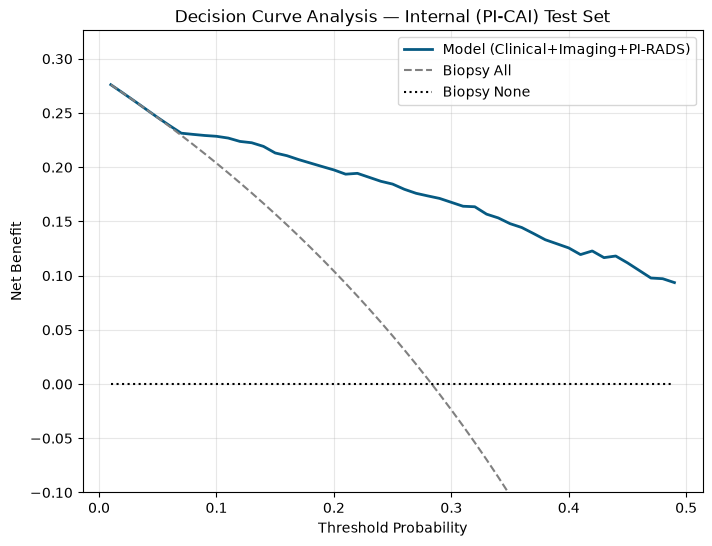

In [33]:
import matplotlib.pyplot as plt

def calculate_net_benefit(y_true, y_prob, threshold):
    preds = (y_prob >= threshold).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    n = len(y_true)
    return (tp/n) - (fp/n) * (threshold/(1-threshold))

thresholds = np.arange(0.01, 0.5, 0.01)

# Net benefit of your model
nb_model_internal = [calculate_net_benefit(y_internal, probs_internal, t) for t in thresholds]

# Reference strategies
nb_treat_all = [(y_internal.mean()) - (1 - y_internal.mean()) * (t/(1-t)) for t in thresholds]
nb_treat_none = [0 for t in thresholds]

plt.figure(figsize=(8, 6))
plt.plot(thresholds, nb_model_internal, label='Model (Clinical+Imaging+PI-RADS)', linewidth=2, color='#065A82')
plt.plot(thresholds, nb_treat_all, label='Biopsy All', linestyle='--', color='gray')
plt.plot(thresholds, nb_treat_none, label='Biopsy None', linestyle=':', color='black')
plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.title('Decision Curve Analysis — Internal (PI-CAI) Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(-0.1, max(nb_model_internal) + 0.05)
plt.savefig('dca_internal.png', dpi=300, bbox_inches='tight')
plt.show()

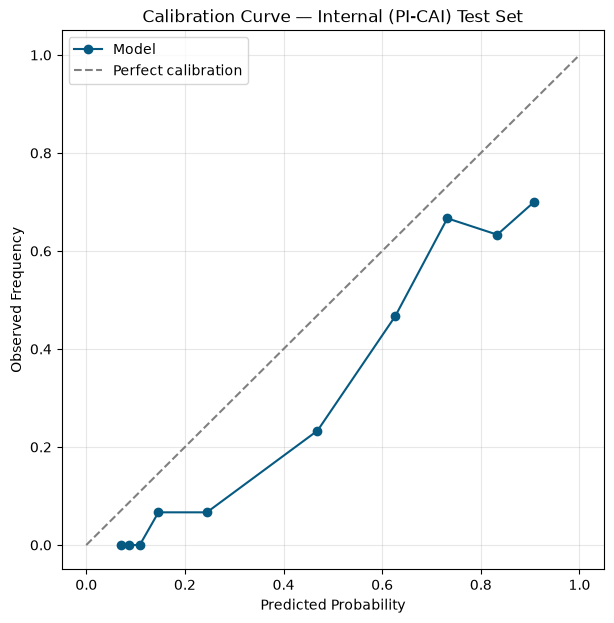

In [34]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_internal, probs_internal, n_bins=10, strategy='quantile')

plt.figure(figsize=(7, 7))
plt.plot(prob_pred, prob_true, marker='o', label='Model', color='#065A82')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
plt.xlabel('Predicted Probability')
plt.ylabel('Observed Frequency')
plt.title('Calibration Curve — Internal (PI-CAI) Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('calibration_internal.png', dpi=300, bbox_inches='tight')
plt.show()

In [36]:
# Rebuild your other locked models (already trained on PI-CAI, no changes)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf_locked = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_locked.fit(Xp_train_scaled, yp_train)

lr_locked = LogisticRegression(C=0.01, max_iter=1000, class_weight='balanced')
lr_locked.fit(Xp_train_scaled, yp_train)

xgb_locked = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.01, subsample=0.8, scale_pos_weight=2.5, random_state=42, eval_metric='logloss')
xgb_locked.fit(Xp_train_scaled, yp_train)

locked_models_all = {
    'Stacking': locked_model,  # already trained
    'RandomForest': rf_locked,
    'LogisticRegression': lr_locked,
    'XGBoost': xgb_locked
}

# Apply the SAME locked scaler, test on the SAME external cohort, for every model
X_external_scaled = scaler_locked.transform(X_external_final)

external_results = []
for name, model in locked_models_all.items():
    preds = model.predict(X_external_scaled)
    probs = model.predict_proba(X_external_scaled)[:, 1]
    external_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_external_final, preds),
        'Precision': precision_score(y_external_final, preds),
        'Recall': recall_score(y_external_final, preds),
        'F1': f1_score(y_external_final, preds),
        'ROC-AUC': roc_auc_score(y_external_final, probs)
    })

external_results_df = pd.DataFrame(external_results).sort_values('ROC-AUC', ascending=False)
print(external_results_df)

                Model  Accuracy  Precision    Recall        F1   ROC-AUC
0            Stacking  0.668798   0.719540  0.695556  0.707345  0.745408
1        RandomForest  0.657289   0.774096  0.571111  0.657289  0.738059
2  LogisticRegression  0.662404   0.668478  0.820000  0.736527  0.731124
3             XGBoost  0.648338   0.774295  0.548889  0.642393  0.724264


In [1]:
import pandas as pd

pd_clinical = pd.read_excel('external_validation_2/prostate_diagnosis_clinical.xlsx')
print(pd_clinical.shape)
print(pd_clinical.columns.tolist())
print(pd_clinical.head())

(4, 55)
['TCIA ID', 'ProstateDx-01-0001', 'ProstateDx-01-0002', 'ProstateDx-01-0003', 'ProstateDx-01-0004', 'ProstateDx-01-0005', 'ProstateDx-01-0006', 'ProstateDx-01-0007', 'ProstateDx-01-0008', 'ProstateDx-01-0009', 'ProstateDx-01-0010', 'ProstateDx-01-0011', 'ProstateDx-01-0012', 'ProstateDx-01-0013', 'ProstateDx-01-0014', 'ProstateDx-01-0015', 'ProstateDx-01-0016', 'ProstateDx-01-0017', 'ProstateDx-01-0018', 'ProstateDx-01-0019', 'ProstateDx-01-0020', 'ProstateDx-01-0021', 'ProstateDx-01-0022', 'ProstateDx-01-0023', 'ProstateDx-01-0024', 'ProstateDx-01-0025', 'ProstateDx-01-0026', 'ProstateDx-01-0027', 'ProstateDx-01-0028', 'ProstateDx-01-0029', 'ProstateDx-01-0030', 'ProstateDx-01-0031', 'ProstateDx-01-0032', 'ProstateDx-01-0033', 'ProstateDx-01-0034', 'ProstateDx-01-0035', 'ProstateDx-01-0036', 'ProstateDx-01-0037', 'ProstateDx-01-0038', 'ProstateDx-01-0039', 'ProstateDx-01-0040', 'ProstateDx-01-0041', 'ProstateDx-01-0042', 'ProstateDx-01-0043', 'ProstateDx-01-0044', 'ProstateDx-

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/openpyxl/reader/workbook.py:118: UserWarning: Print area cannot be set to Defined name: Sheet1!$A:$BC.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [2]:
age_cols = [c for c in pd_clinical.columns if 'age' in str(c).lower()]
psa_cols = [c for c in pd_clinical.columns if 'psa' in str(c).lower()]
pirads_cols = [c for c in pd_clinical.columns if 'pirads' in str(c).lower() or 'suspicion' in str(c).lower() or 'radiology' in str(c).lower()]
gleason_cols = [c for c in pd_clinical.columns if 'gleason' in str(c).lower()]

print("Age columns:", age_cols)
print("PSA columns:", psa_cols)
print("PI-RADS/radiology columns:", pirads_cols)
print("Gleason columns:", gleason_cols)

Age columns: []
PSA columns: []
PI-RADS/radiology columns: []
Gleason columns: []


In [1]:
import pandas as pd

turkey_df = pd.read_csv('external_validation_3/turkey_clinical.csv')
print(turkey_df.shape)
print(turkey_df.columns.tolist())
print(turkey_df.head())

(600, 31)
['Hasta_ID', 'Yas', 'Tani_Tarihi', 'PSA_Tani', 'Klinik_Evre', 'Biyopsi_Gleason', 'Risk_Grubu', 'Albumin', 'Lenfosit', 'CRP', 'NLR', 'CALLY_Index', 'Komorbidite_Skor', 'Tedavi_Tipi', 'Tedavi_Tarihi', 'RT_Dozu', 'ADT_Tipi', 'ADT_Suresi', 'Patolojik_Evre', 'Cerrahi_Sinir', 'Final_Gleason', 'PSA_Nadir', 'PSA_Takip_3ay', 'PSA_Takip_6ay', 'PSA_Takip_12ay', 'BCR_Durum', 'BCR_Tarihi', 'Metastaz_Durum', 'Metastaz_Tarihi', 'Son_Durum', 'Son_Takip_Tarihi']
[patient-level preview removed for the public deposit]


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

picai_clinical_clean = pd.read_csv('picai_clinical_clean.csv')

X_reduced = picai_clinical_clean[['patient_age', 'psa']]
y_reduced = picai_clinical_clean['csPCa_label']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reduced, y_reduced, test_size=0.2, stratify=y_reduced, random_state=42)
scaler_reduced = StandardScaler()
Xr_train_scaled = scaler_reduced.fit_transform(Xr_train)
Xr_test_scaled = scaler_reduced.transform(Xr_test)

rf_reduced = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
rf_reduced.fit(Xr_train_scaled, yr_train)

preds_internal = rf_reduced.predict(Xr_test_scaled)
probs_internal = rf_reduced.predict_proba(Xr_test_scaled)[:, 1]

print("=== PI-CAI Internal (age+PSA only) ===")
print("Accuracy:", accuracy_score(yr_test, preds_internal))
print("Recall:", recall_score(yr_test, preds_internal))
print("ROC-AUC:", roc_auc_score(yr_test, probs_internal))

=== PI-CAI Internal (age+PSA only) ===
Accuracy: 0.5666666666666667
Recall: 0.4588235294117647
ROC-AUC: 0.5856634746922025


In [3]:
tcga_clinical = pd.read_csv('clinical_features_selected.csv')
print(tcga_clinical.columns.tolist())
print(tcga_clinical.shape)
print(tcga_clinical.head())

FileNotFoundError: [Errno 2] No such file or directory: 'clinical_features_selected.csv'

In [4]:
import os
for root, dirs, files in os.walk(os.path.expanduser('~/prostate-cancer-research')):
    for f in files:
        if 'clinical' in f.lower() and f.endswith('.csv'):
            print(os.path.join(root, f))

~/prostate-cancer-research/picai_clinical_clean.csv
~/prostate-cancer-research/.ipynb_checkpoints/picai_clinical_clean-checkpoint.csv
~/prostate-cancer-research/external_validation_3/turkey_clinical.csv
~/prostate-cancer-research/external_validation/external_clinical_clean.csv


In [5]:
import glob
tsv_files = glob.glob(os.path.expanduser('~/prostate-cancer-research/**/*.tsv'), recursive=True)
print(tsv_files)

[]


In [6]:
clinical = pd.read_csv('clinical.tsv', sep='\t', low_memory=False)  # adjust path if found elsewhere
clinical_clean = clinical.replace("'--", pd.NA)

clinical_features = clinical_clean[[
    'cases.case_id', 'demographic.age_at_index', 'diagnoses.gleason_score'
]].copy()
clinical_features['demographic.age_at_index'] = pd.to_numeric(clinical_features['demographic.age_at_index'], errors='coerce')

def combine_group(g):
    return g.ffill().bfill().iloc[0]
clinical_features = clinical_features.groupby('cases.case_id', as_index=False).apply(combine_group)

# Rebuild PSA from follow_up.tsv
followup = pd.read_csv('follow_up.tsv', sep='\t', low_memory=False)
psa_rows = followup[followup['molecular_tests.antigen'] == 'Prostate-Specific Antigen (PSA)']
psa_df = psa_rows[['cases.case_id', 'molecular_tests.test_value']].rename(columns={'molecular_tests.test_value': 'psa_level'})
psa_df['psa_level'] = pd.to_numeric(psa_df['psa_level'], errors='coerce')

clinical_final = clinical_features.merge(psa_df, on='cases.case_id', how='left')
clinical_final['psa_level'] = clinical_final['psa_level'].fillna(clinical_final['psa_level'].median())

# Build label and drop Gleason (avoid leakage, matching your original approach)
clinical_final['csPCa_label'] = (pd.to_numeric(clinical_final['diagnoses.gleason_score'], errors='coerce') >= 7).astype(int)
clinical_final = clinical_final.drop(columns=['diagnoses.gleason_score'])

print(clinical_final.shape)
clinical_final.to_csv('clinical_features_selected.csv', index=False)
print("Saved successfully")

FileNotFoundError: [Errno 2] No such file or directory: 'clinical.tsv'

In [7]:
import glob, os
tsv_files = glob.glob(os.path.expanduser('~/prostate-cancer-research/**/*.tsv'), recursive=True)
print(tsv_files)

[]


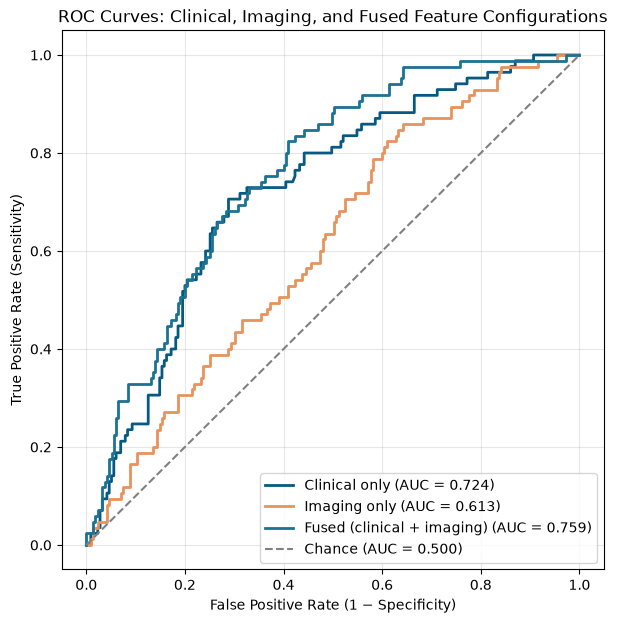

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Rebuild the three configurations (adjust paths if needed)
fused_df = pd.read_csv('fused_final_dataset.csv')

clinical_cols = ['patient_age', 'psa', 'psad', 'prostate_volume']
imaging_cols = [c for c in fused_df.columns if c.startswith('cnn_pca_')]

X_all = fused_df.drop(columns=['patient_id', 'csPCa_label'])
y_all = fused_df['csPCa_label']

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)

configs = {
    'Clinical only': clinical_cols,
    'Imaging only': imaging_cols,
    'Fused (clinical + imaging)': clinical_cols + imaging_cols,
}

plt.figure(figsize=(7, 7))
colors = {'Clinical only': '#065A82', 'Imaging only': '#E8935D', 'Fused (clinical + imaging)': '#1C7293'}

for name, cols in configs.items():
    X_train = X_train_full[cols]
    X_test = X_test_full[cols]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
    model.fit(X_train_scaled, y_train)

    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', color=colors[name], linewidth=2)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves: Clinical, Imaging, and Fused Feature Configurations')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('roc_clinical_imaging_fused.png', dpi=300, bbox_inches='tight')
plt.show()

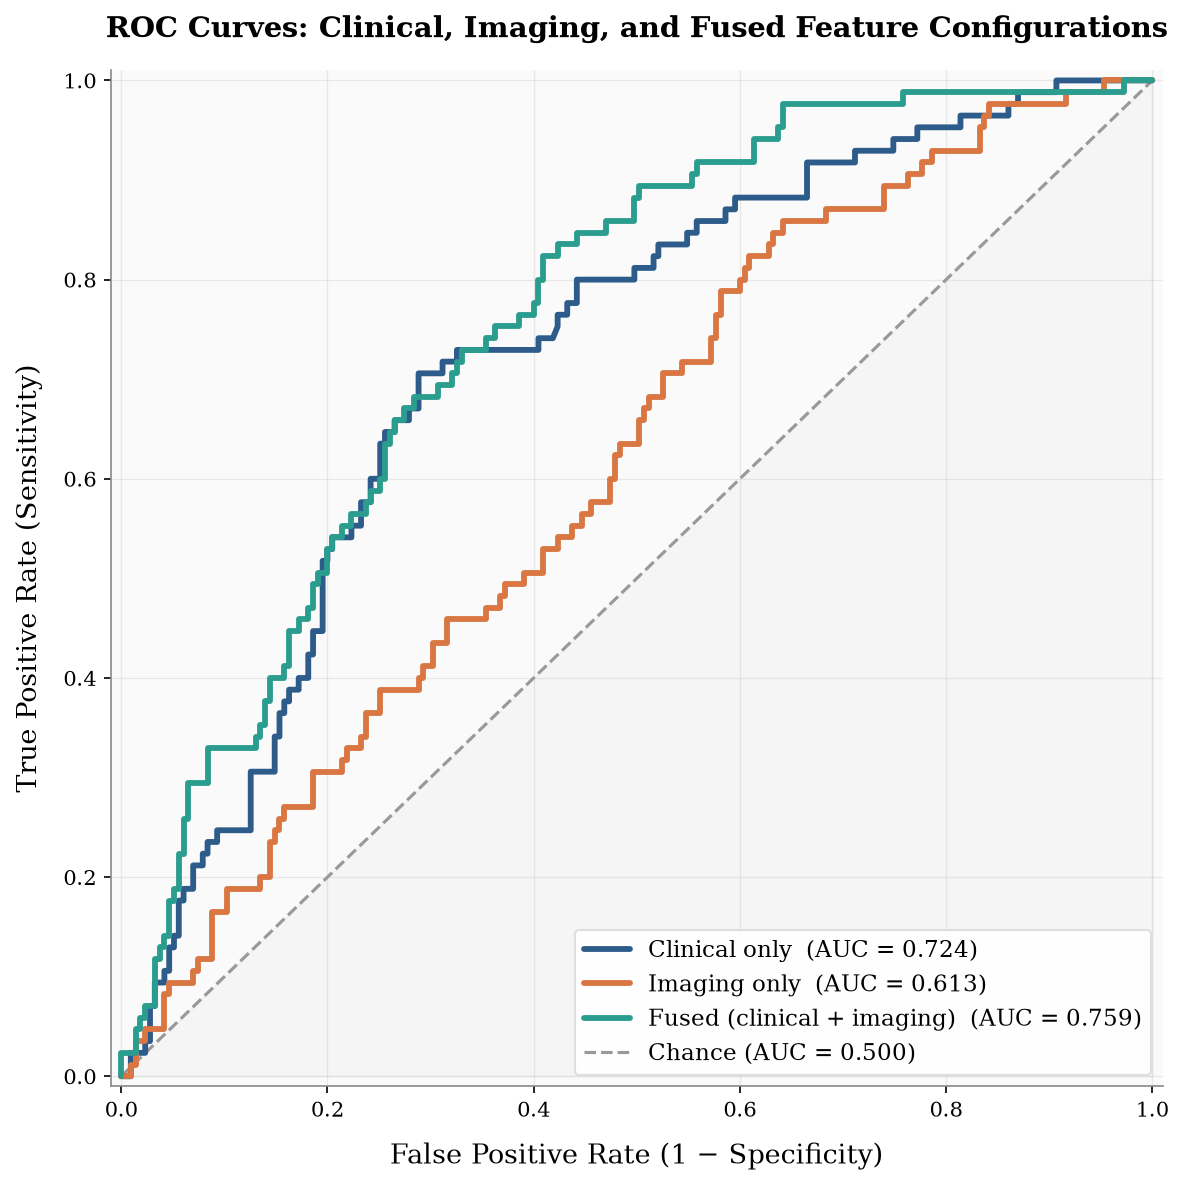

In [9]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Rebuild the three configurations
fused_df = pd.read_csv('fused_final_dataset.csv')

clinical_cols = ['patient_age', 'psa', 'psad', 'prostate_volume']
imaging_cols = [c for c in fused_df.columns if c.startswith('cnn_pca_')]

X_all = fused_df.drop(columns=['patient_id', 'csPCa_label'])
y_all = fused_df['csPCa_label']

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)

configs = {
    'Clinical only': clinical_cols,
    'Imaging only': imaging_cols,
    'Fused (clinical + imaging)': clinical_cols + imaging_cols,
}

# Refined, colourblind-friendly palette
colors = {
    'Clinical only': '#2E5C8A',            # deep blue
    'Imaging only': '#D97642',             # warm terracotta
    'Fused (clinical + imaging)': '#2A9D8F',  # teal
}
linestyles = {'Clinical only': '-', 'Imaging only': '-', 'Fused (clinical + imaging)': '-'}

plt.rcParams['font.family'] = 'DejaVu Serif'
fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

for name, cols in configs.items():
    X_train = X_train_full[cols]
    X_test = X_test_full[cols]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
    model.fit(X_train_scaled, y_train)

    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    ax.plot(fpr, tpr, label=f'{name}  (AUC = {auc:.3f})',
            color=colors[name], linewidth=2.8, linestyle=linestyles[name],
            solid_capstyle='round', zorder=3)

# Chance line
ax.plot([0, 1], [0, 1], linestyle='--', color='#999999', linewidth=1.5,
        label='Chance (AUC = 0.500)', zorder=2)
ax.fill_between([0, 1], [0, 1], color='#999999', alpha=0.05, zorder=1)

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.set_xlabel('False Positive Rate (1 − Specificity)', fontsize=13, labelpad=10)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=13, labelpad=10)
ax.set_title('ROC Curves: Clinical, Imaging, and Fused Feature Configurations',
             fontsize=14, fontweight='bold', pad=16)

ax.legend(loc='lower right', fontsize=11, frameon=True, framealpha=0.95,
          edgecolor='#DDDDDD', fancybox=True)

ax.grid(alpha=0.25, linestyle='-', linewidth=0.6)
ax.set_facecolor('#FAFAFA')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#888888')

plt.tight_layout()
plt.savefig('roc_clinical_imaging_fused.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

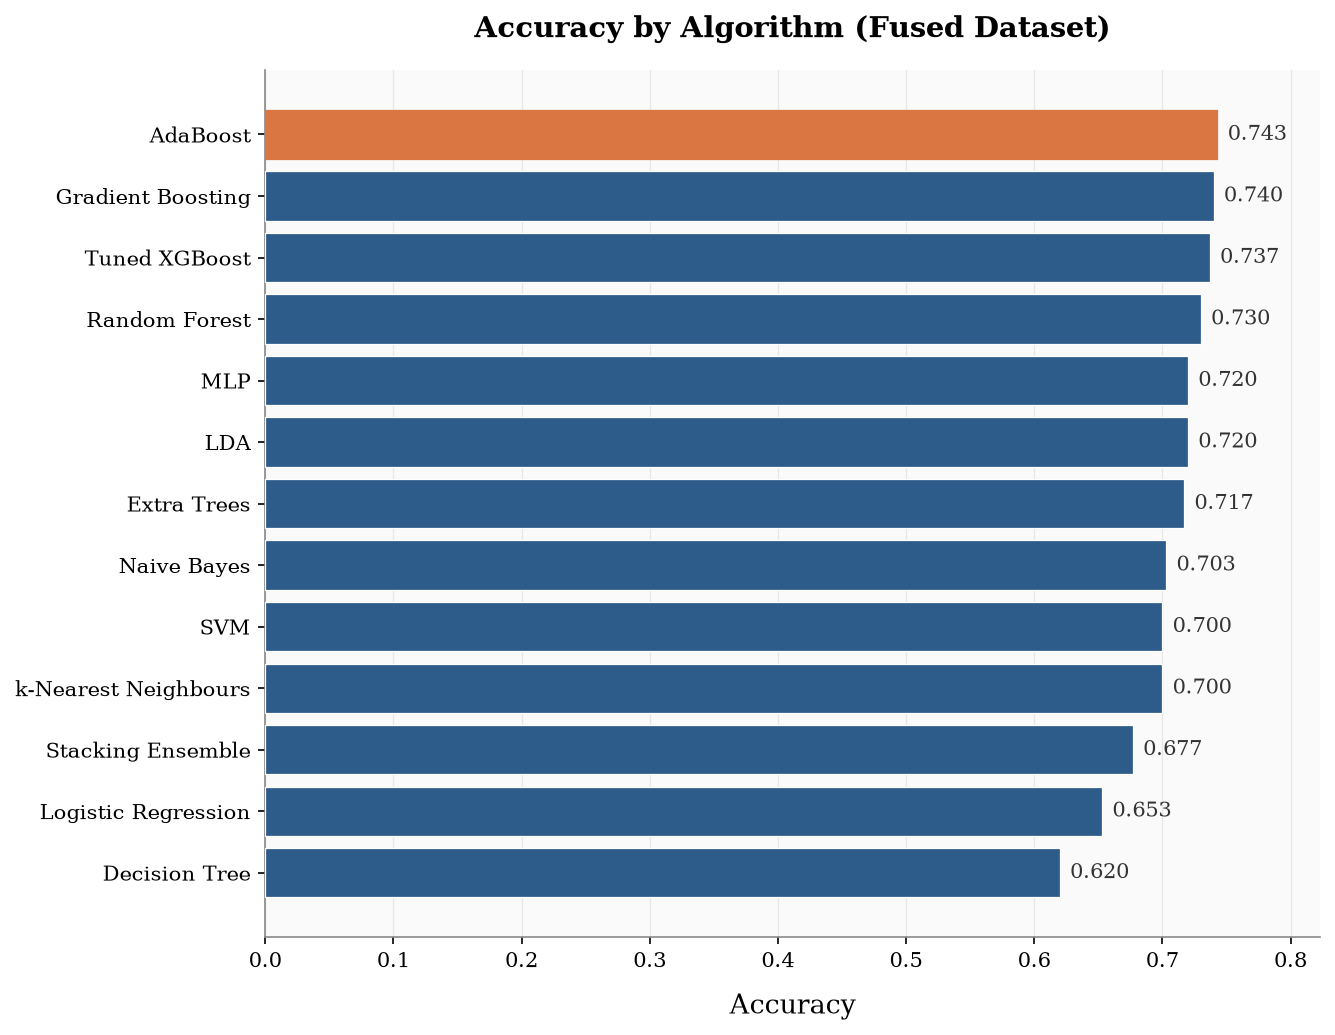

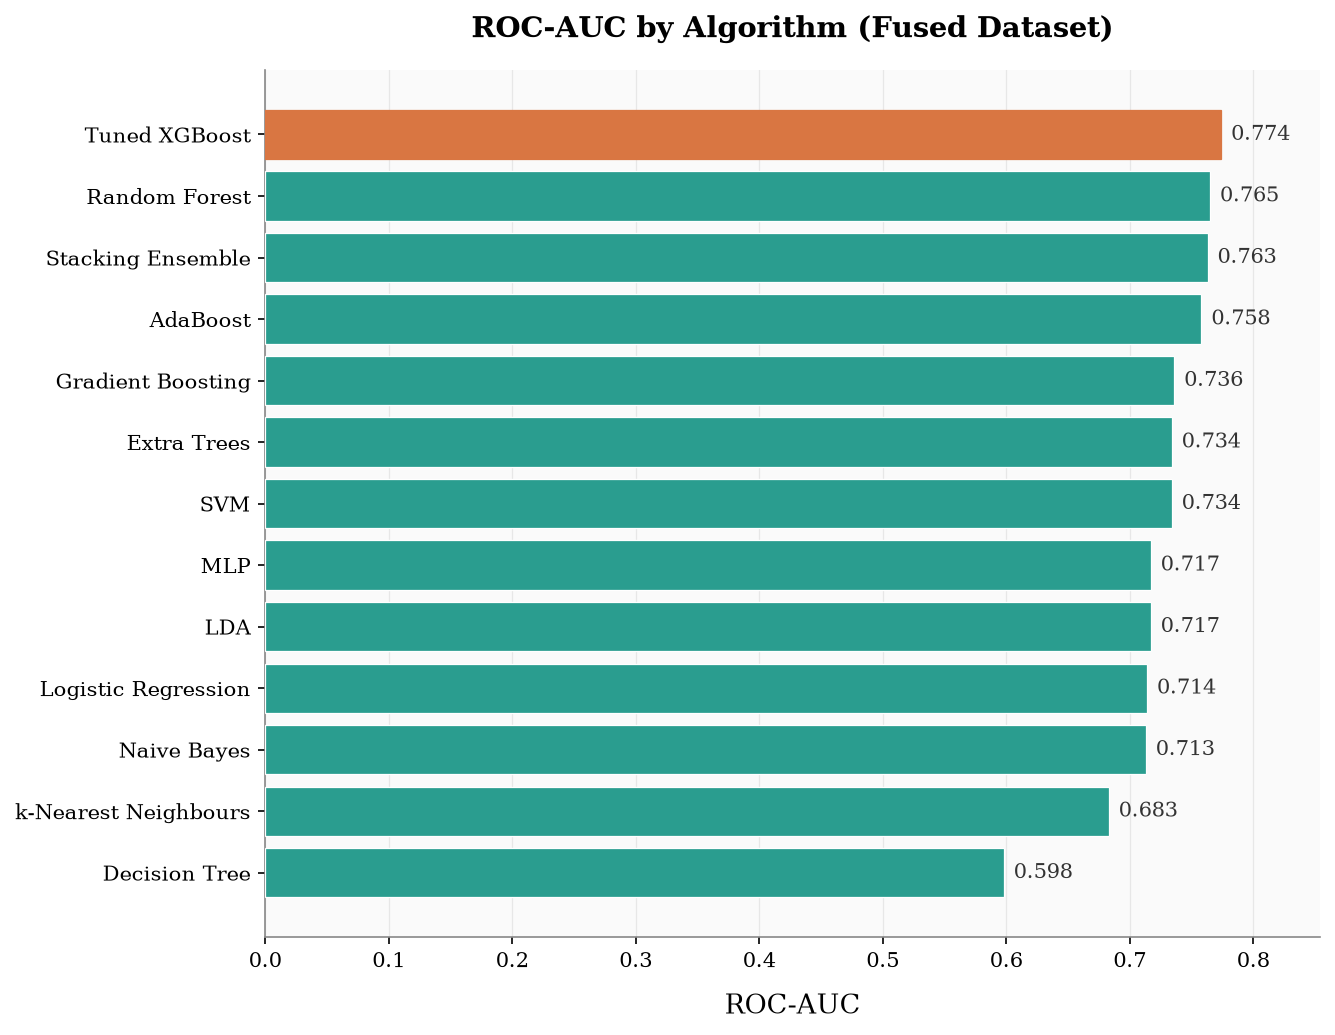

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Data exactly as reported in Table 4.2
results = {
    'Random Forest':        {'Accuracy': 0.730, 'ROC-AUC': 0.765},
    'AdaBoost':              {'Accuracy': 0.743, 'ROC-AUC': 0.758},
    'Tuned XGBoost':         {'Accuracy': 0.737, 'ROC-AUC': 0.774},
    'Gradient Boosting':     {'Accuracy': 0.740, 'ROC-AUC': 0.736},
    'Extra Trees':           {'Accuracy': 0.717, 'ROC-AUC': 0.734},
    'SVM':                   {'Accuracy': 0.700, 'ROC-AUC': 0.734},
    'MLP':                   {'Accuracy': 0.720, 'ROC-AUC': 0.717},
    'LDA':                   {'Accuracy': 0.720, 'ROC-AUC': 0.717},
    'Logistic Regression':   {'Accuracy': 0.653, 'ROC-AUC': 0.714},
    'Naive Bayes':           {'Accuracy': 0.703, 'ROC-AUC': 0.713},
    'Stacking Ensemble':     {'Accuracy': 0.677, 'ROC-AUC': 0.763},
    'k-Nearest Neighbours':  {'Accuracy': 0.700, 'ROC-AUC': 0.683},
    'Decision Tree':         {'Accuracy': 0.620, 'ROC-AUC': 0.598},
}

plt.rcParams['font.family'] = 'DejaVu Serif'

def make_bar_chart(metric, color, filename, title):
    sorted_items = sorted(results.items(), key=lambda x: x[1][metric], reverse=True)
    names = [item[0] for item in sorted_items]
    values = [item[1][metric] for item in sorted_items]

    fig, ax = plt.subplots(figsize=(9, 7), dpi=150)
    bars = ax.barh(names, values, color=color, edgecolor='white', linewidth=0.6, zorder=3)

    # Highlight the top performer
    bars[0].set_color('#D97642')

    for bar, val in zip(bars, values):
        ax.text(val + 0.008, bar.get_y() + bar.get_height() / 2, f'{val:.3f}',
                va='center', fontsize=10, color='#333333')

    ax.set_xlim(0, max(values) + 0.08)
    ax.set_xlabel(metric, fontsize=13, labelpad=10)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=16)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.25, linestyle='-', linewidth=0.6, zorder=0)
    ax.set_facecolor('#FAFAFA')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#888888')

    plt.tight_layout()
    plt.savefig(filename, dpi=400, bbox_inches='tight', facecolor='white')
    plt.show()

make_bar_chart('Accuracy', '#2E5C8A', 'algo_comparison_accuracy.png',
                'Accuracy by Algorithm (Fused Dataset)')

make_bar_chart('ROC-AUC', '#2A9D8F', 'algo_comparison_rocauc.png',
                'ROC-AUC by Algorithm (Fused Dataset)')

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


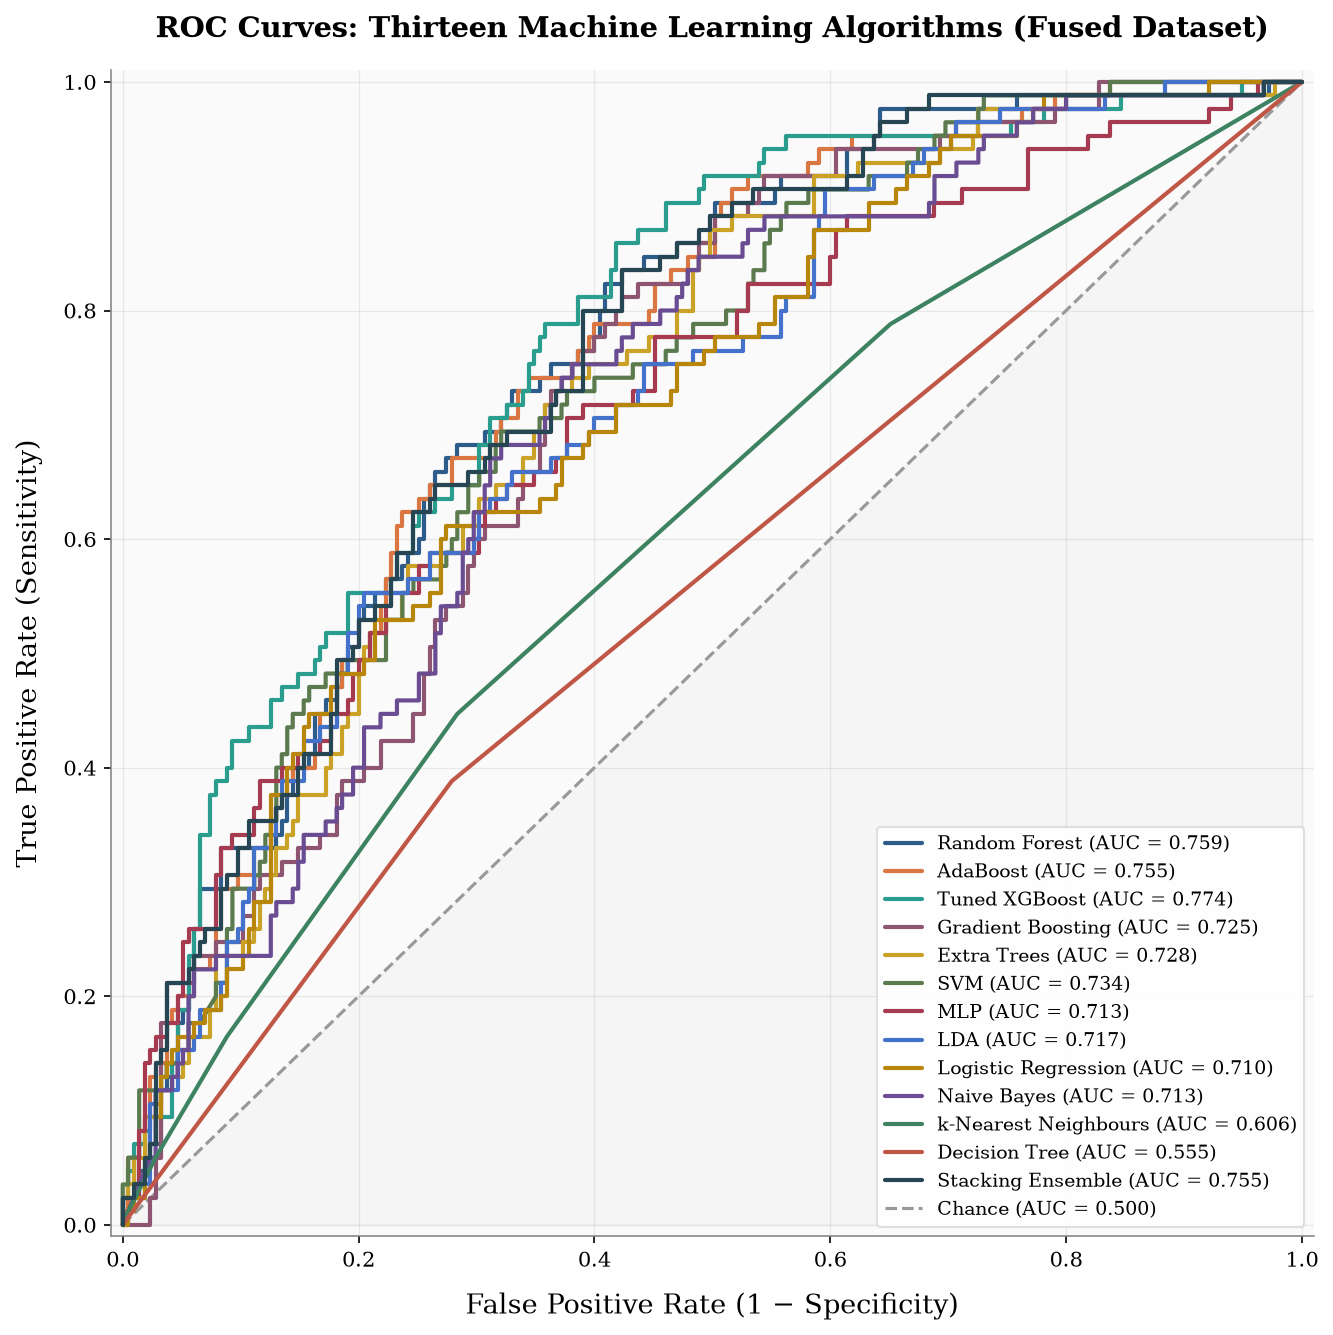

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import pandas as pd

fused_df = pd.read_csv('fused_final_dataset.csv')
X_all = fused_df.drop(columns=['patient_id', 'csPCa_label'])
y_all = fused_df['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced'),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    'Tuned XGBoost': XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.01, subsample=0.8, scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced'),
    'SVM': SVC(probability=True, class_weight='balanced', random_state=42),
    'MLP': MLPClassifier(max_iter=1000, random_state=42),
    'LDA': LinearDiscriminantAnalysis(),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Naive Bayes': GaussianNB(),
    'k-Nearest Neighbours': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
}
models['Stacking Ensemble'] = StackingClassifier(
    estimators=[('rf', models['Random Forest']), ('ada', models['AdaBoost']), ('gb', models['Gradient Boosting'])],
    final_estimator=LogisticRegression(class_weight='balanced'), cv=5
)

# A distinct 13-colour qualitative palette (colourblind-conscious, avoids repeats)
palette = [
    '#2E5C8A', '#D97642', '#2A9D8F', '#8E5572', '#C9A227', '#5B7B4F',
    '#A63A50', '#4472CA', '#B8860B', '#6A4C93', '#3D8361', '#C05746', '#264653'
]

plt.rcParams['font.family'] = 'DejaVu Serif'
fig, ax = plt.subplots(figsize=(9, 9), dpi=150)

for (name, model), color in zip(models.items(), palette):
    model.fit(X_train_scaled, y_train)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', color=color, linewidth=2, solid_capstyle='round', zorder=3)

ax.plot([0, 1], [0, 1], linestyle='--', color='#999999', linewidth=1.5, label='Chance (AUC = 0.500)', zorder=2)
ax.fill_between([0, 1], [0, 1], color='#999999', alpha=0.05, zorder=1)

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.set_xlabel('False Positive Rate (1 − Specificity)', fontsize=13, labelpad=10)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=13, labelpad=10)
ax.set_title('ROC Curves: Thirteen Machine Learning Algorithms (Fused Dataset)', fontsize=14, fontweight='bold', pad=16)

ax.legend(loc='lower right', fontsize=9, frameon=True, framealpha=0.95, edgecolor='#DDDDDD', fancybox=True, ncol=1)
ax.grid(alpha=0.25, linestyle='-', linewidth=0.6)
ax.set_facecolor('#FAFAFA')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#888888')

plt.tight_layout()
plt.savefig('roc_thirteen_algorithms.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

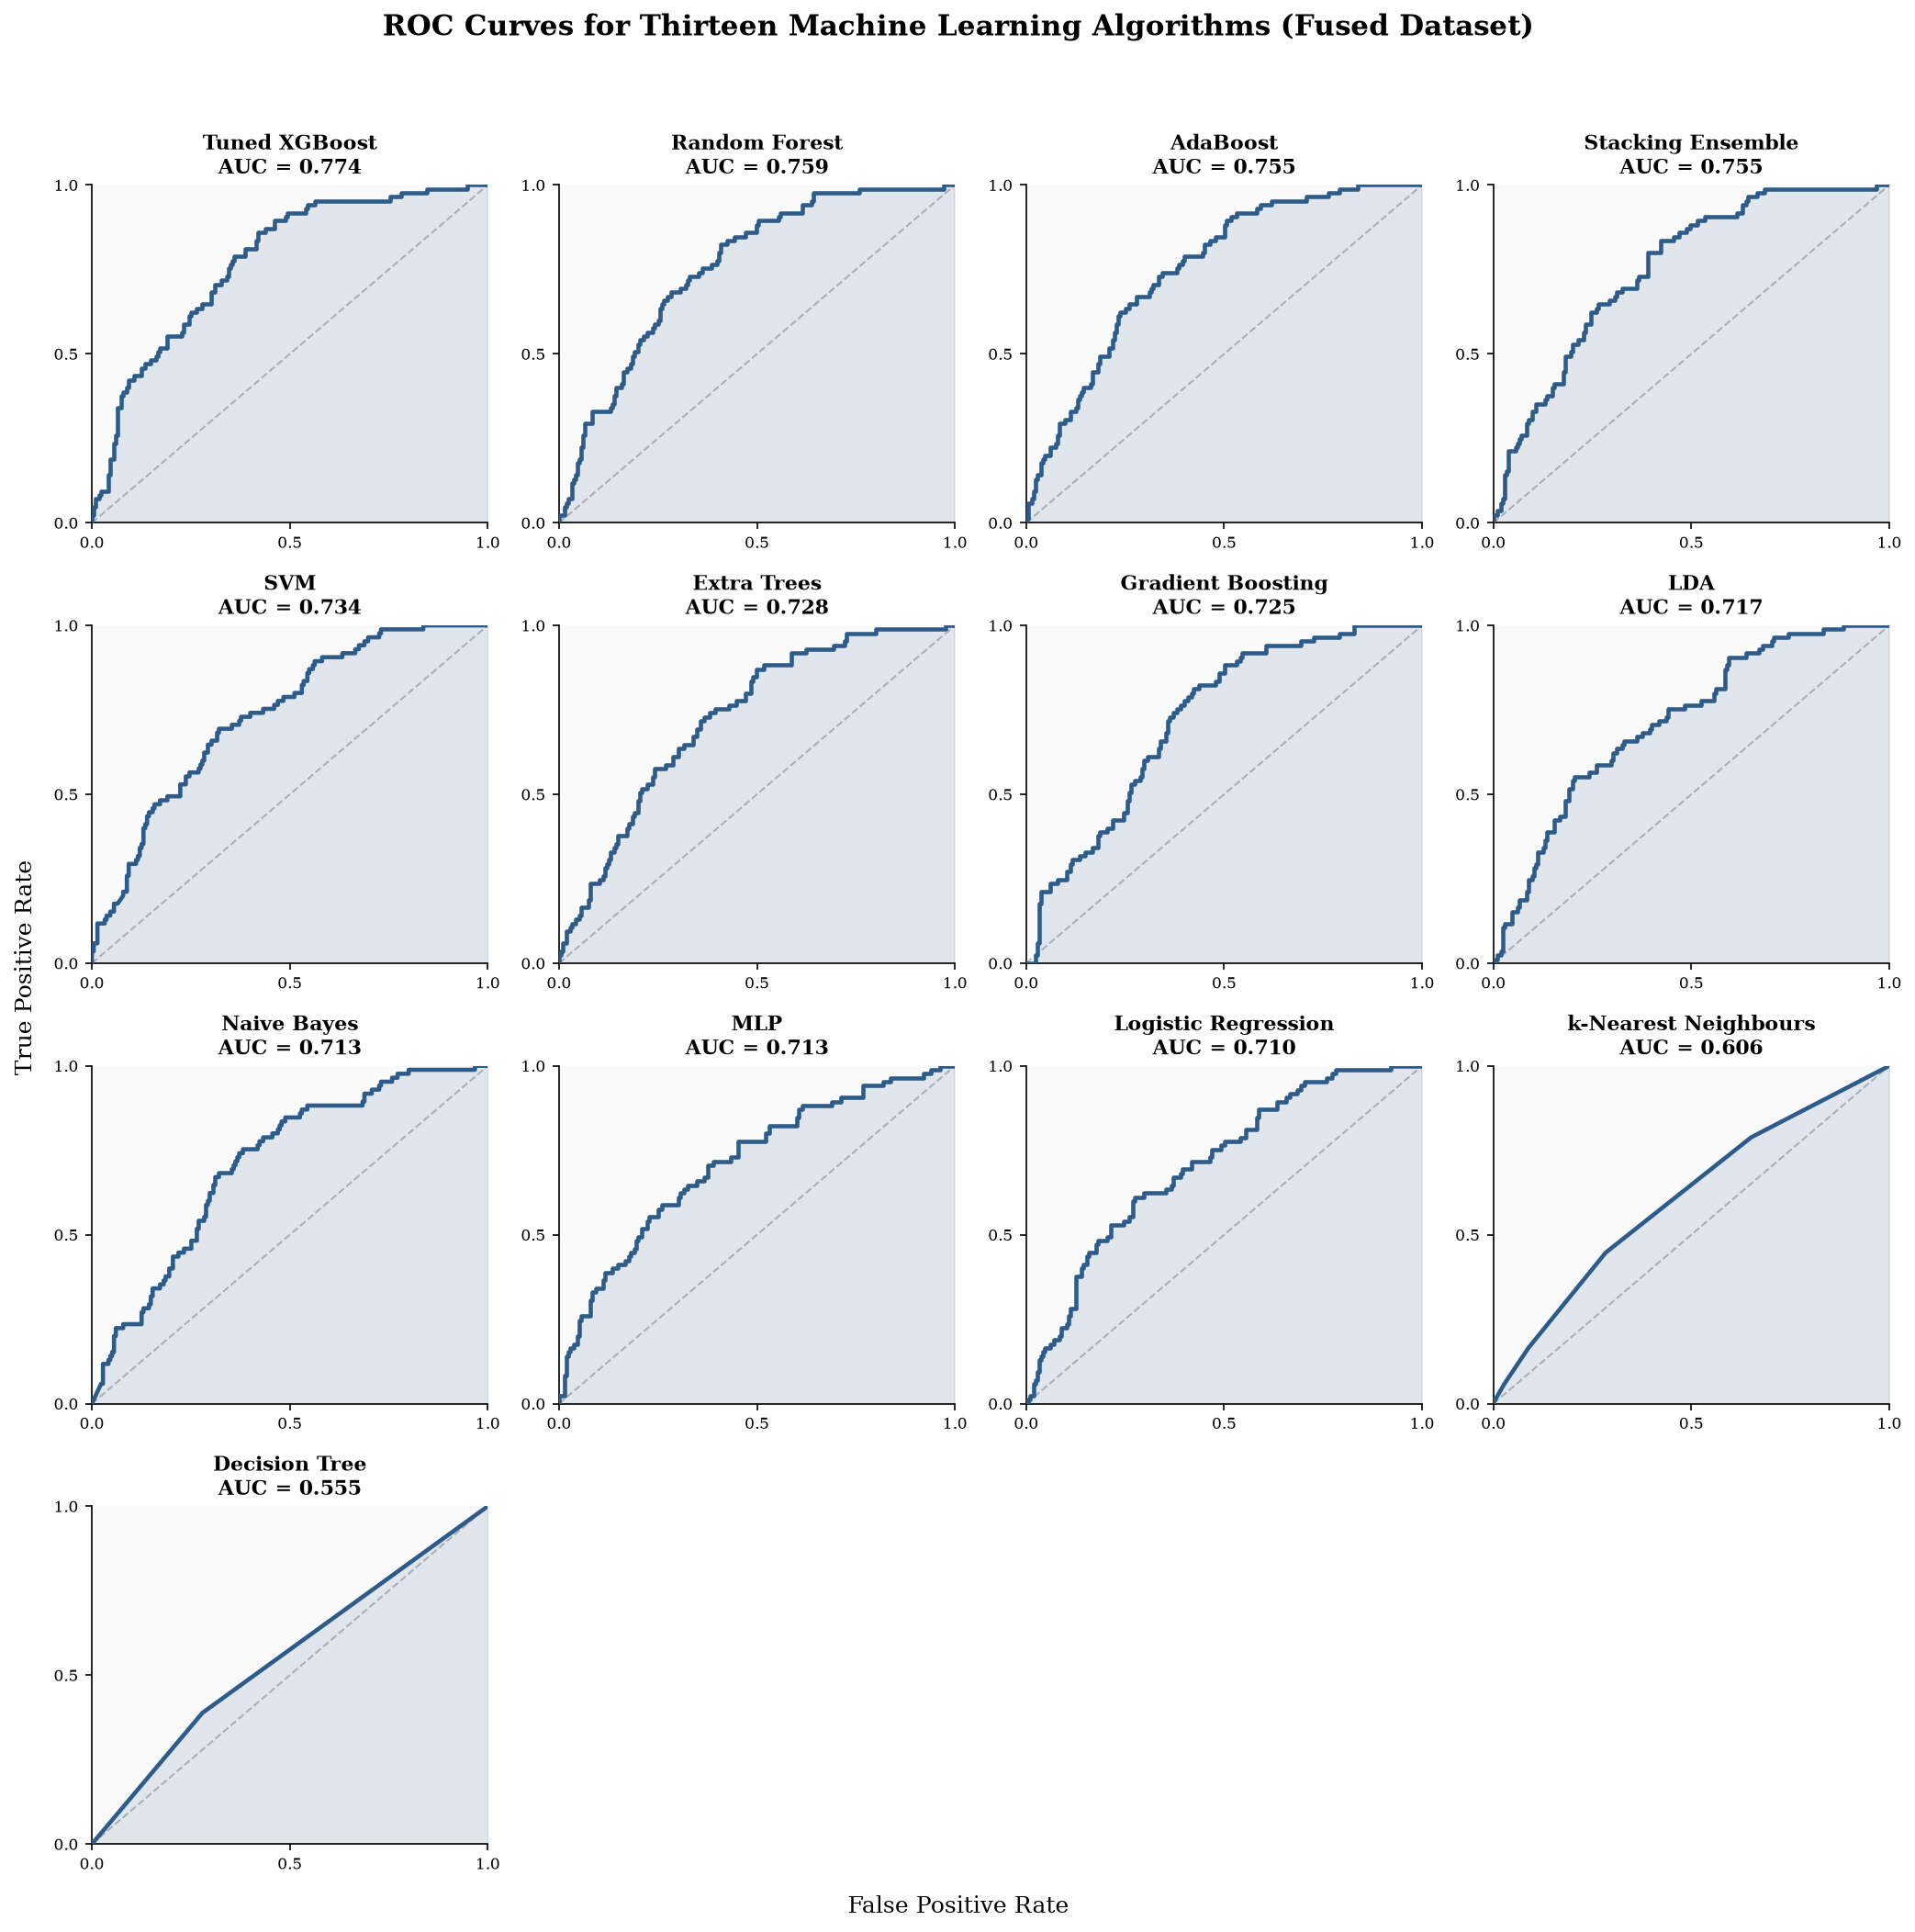

In [12]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Serif'

# Reuse your already-trained models and test data from the previous script
model_order = sorted(models.keys(), key=lambda name: roc_auc_score(
    y_test, models[name].predict_proba(X_test_scaled)[:, 1]
), reverse=True)

fig, axes = plt.subplots(4, 4, figsize=(14, 14), dpi=150)
axes_flat = axes.flatten()

for i, name in enumerate(model_order):
    ax = axes_flat[i]
    probs = models[name].predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    ax.plot(fpr, tpr, color='#2E5C8A', linewidth=2.2, zorder=3)
    ax.fill_between(fpr, tpr, alpha=0.12, color='#2E5C8A', zorder=2)
    ax.plot([0, 1], [0, 1], linestyle='--', color='#BBBBBB', linewidth=1, zorder=1)

    ax.set_title(f'{name}\nAUC = {auc:.3f}', fontsize=10.5, fontweight='bold', pad=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(labelsize=8)
    ax.set_facecolor('#FAFAFA')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Hide the 3 unused panels (13 models in a 4x4 grid)
for j in range(len(model_order), 16):
    axes_flat[j].axis('off')

fig.suptitle('ROC Curves for Thirteen Machine Learning Algorithms (Fused Dataset)',
             fontsize=15, fontweight='bold', y=0.995)
fig.text(0.5, 0.01, 'False Positive Rate', ha='center', fontsize=12)
fig.text(0.01, 0.5, 'True Positive Rate', va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.02, 0.02, 1, 0.97])
plt.savefig('roc_thirteen_algorithms_grid.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

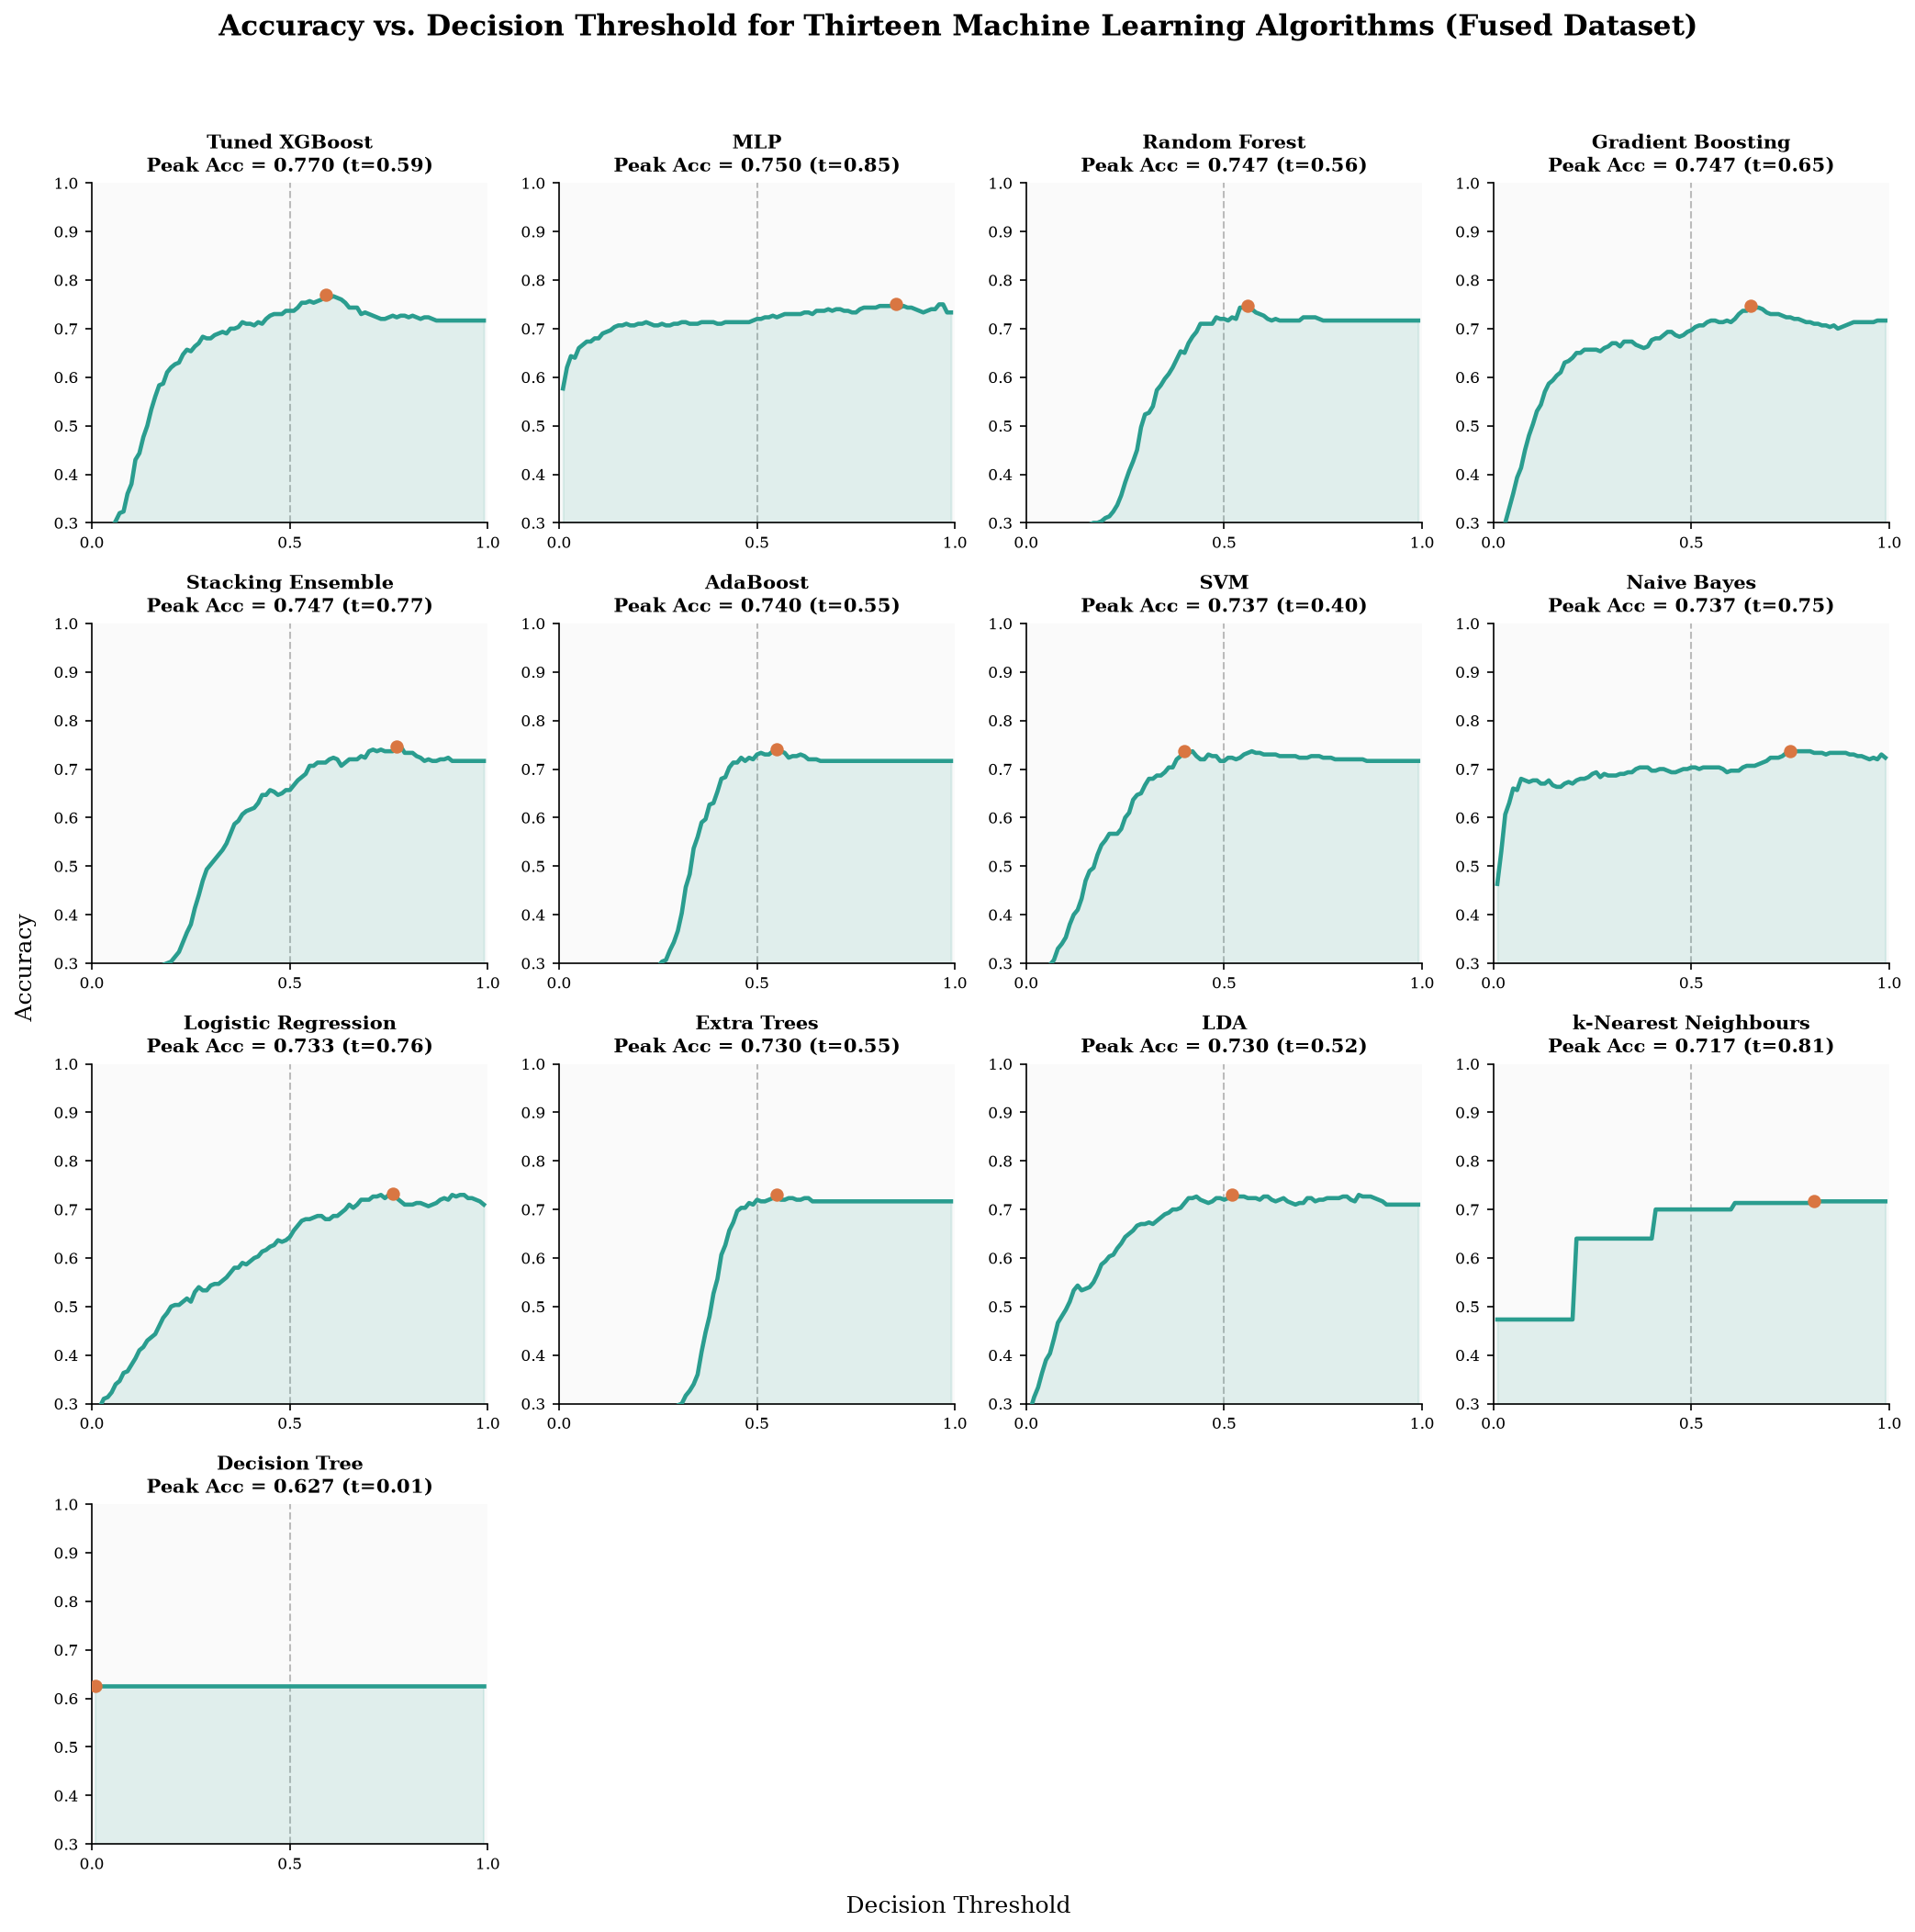

In [13]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

plt.rcParams['font.family'] = 'DejaVu Serif'

thresholds = np.linspace(0.01, 0.99, 99)

fig, axes = plt.subplots(4, 4, figsize=(14, 14), dpi=150)
axes_flat = axes.flatten()

# Sort by peak accuracy achieved across all thresholds, best to worst
def peak_accuracy(name):
    probs = models[name].predict_proba(X_test_scaled)[:, 1]
    accs = [accuracy_score(y_test, (probs >= t).astype(int)) for t in thresholds]
    return max(accs)

model_order_acc = sorted(models.keys(), key=peak_accuracy, reverse=True)

for i, name in enumerate(model_order_acc):
    ax = axes_flat[i]
    probs = models[name].predict_proba(X_test_scaled)[:, 1]
    accs = [accuracy_score(y_test, (probs >= t).astype(int)) for t in thresholds]

    best_idx = np.argmax(accs)
    best_thresh = thresholds[best_idx]
    best_acc = accs[best_idx]

    ax.plot(thresholds, accs, color='#2A9D8F', linewidth=2.2, zorder=3)
    ax.fill_between(thresholds, accs, alpha=0.12, color='#2A9D8F', zorder=2)
    ax.axvline(0.5, linestyle='--', color='#BBBBBB', linewidth=1, zorder=1)
    ax.scatter([best_thresh], [best_acc], color='#D97642', s=35, zorder=4)

    ax.set_title(f'{name}\nPeak Acc = {best_acc:.3f} (t={best_thresh:.2f})', fontsize=10, fontweight='bold', pad=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0.3, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.tick_params(labelsize=8)
    ax.set_facecolor('#FAFAFA')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

for j in range(len(model_order_acc), 16):
    axes_flat[j].axis('off')

fig.suptitle('Accuracy vs. Decision Threshold for Thirteen Machine Learning Algorithms (Fused Dataset)',
             fontsize=15, fontweight='bold', y=0.995)
fig.text(0.5, 0.01, 'Decision Threshold', ha='center', fontsize=12)
fig.text(0.01, 0.5, 'Accuracy', va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.02, 0.02, 1, 0.97])
plt.savefig('accuracy_thirteen_algorithms_grid.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

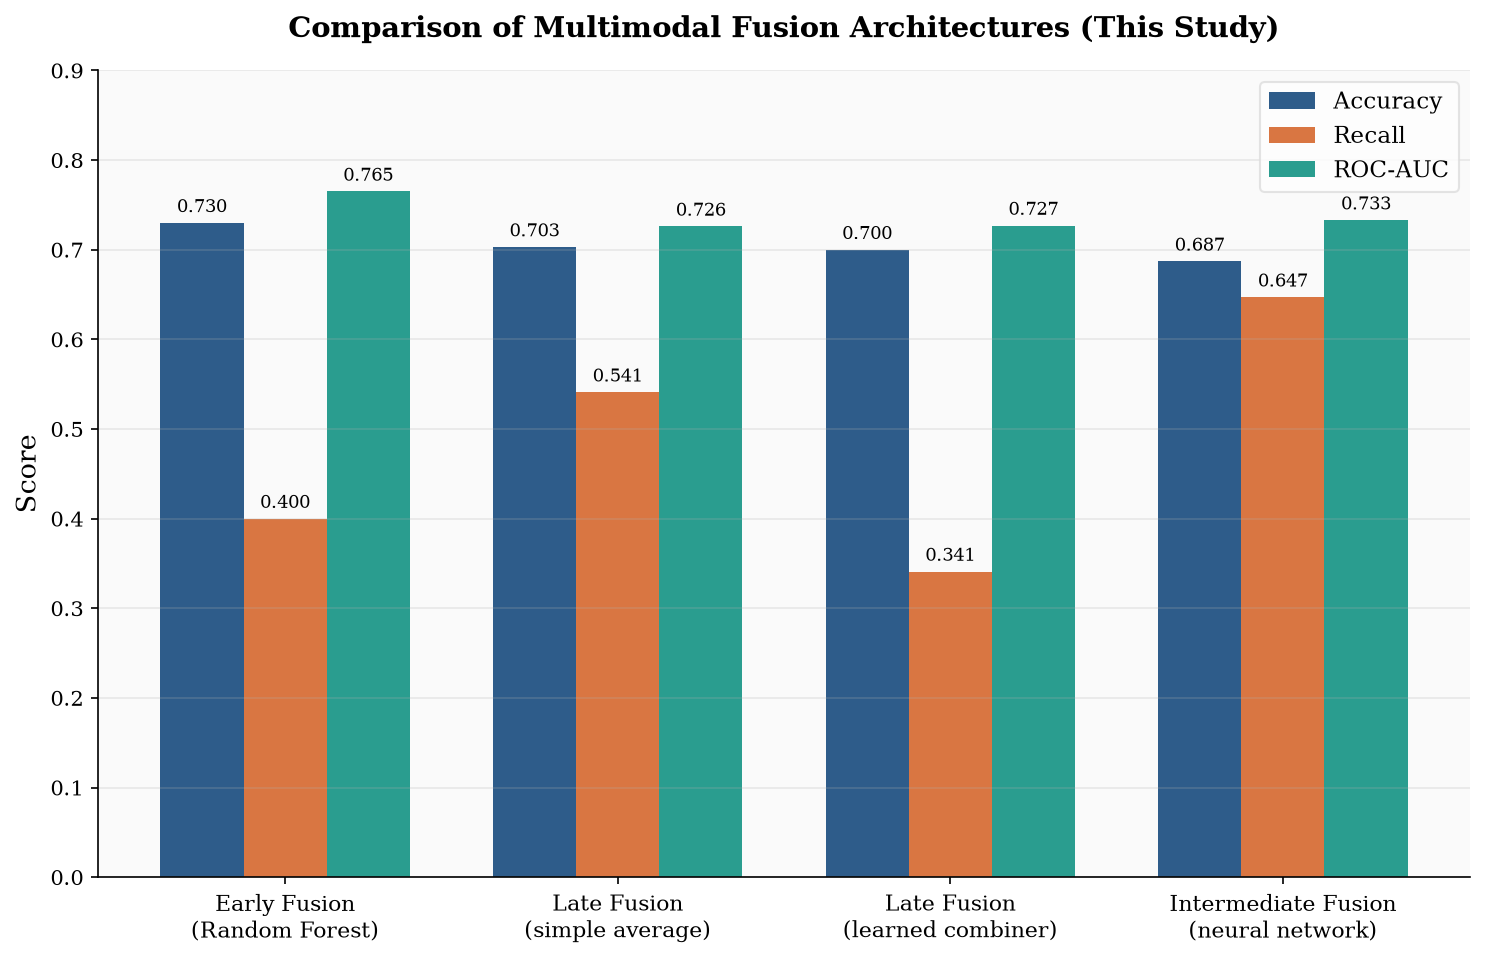

In [14]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Serif'

configs = ['Early Fusion\n(Random Forest)', 'Late Fusion\n(simple average)', 'Late Fusion\n(learned combiner)', 'Intermediate Fusion\n(neural network)']
accuracy = [0.730, 0.703, 0.700, 0.687]
recall = [0.400, 0.541, 0.341, 0.647]
roc_auc = [0.765, 0.726, 0.727, 0.733]

x = np.arange(len(configs))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)
bars1 = ax.bar(x - width, accuracy, width, label='Accuracy', color='#2E5C8A')
bars2 = ax.bar(x, recall, width, label='Recall', color='#D97642')
bars3 = ax.bar(x + width, roc_auc, width, label='ROC-AUC', color='#2A9D8F')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f'{h:.3f}', ha='center', fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10.5)
ax.set_ylabel('Score', fontsize=13)
ax.set_ylim(0, 0.9)
ax.set_title('Comparison of Multimodal Fusion Architectures (This Study)', fontsize=14, fontweight='bold', pad=16)
ax.legend(loc='upper right', fontsize=11, frameon=True, edgecolor='#DDDDDD')
ax.grid(axis='y', alpha=0.25)
ax.set_facecolor('#FAFAFA')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('fusion_architecture_comparison.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

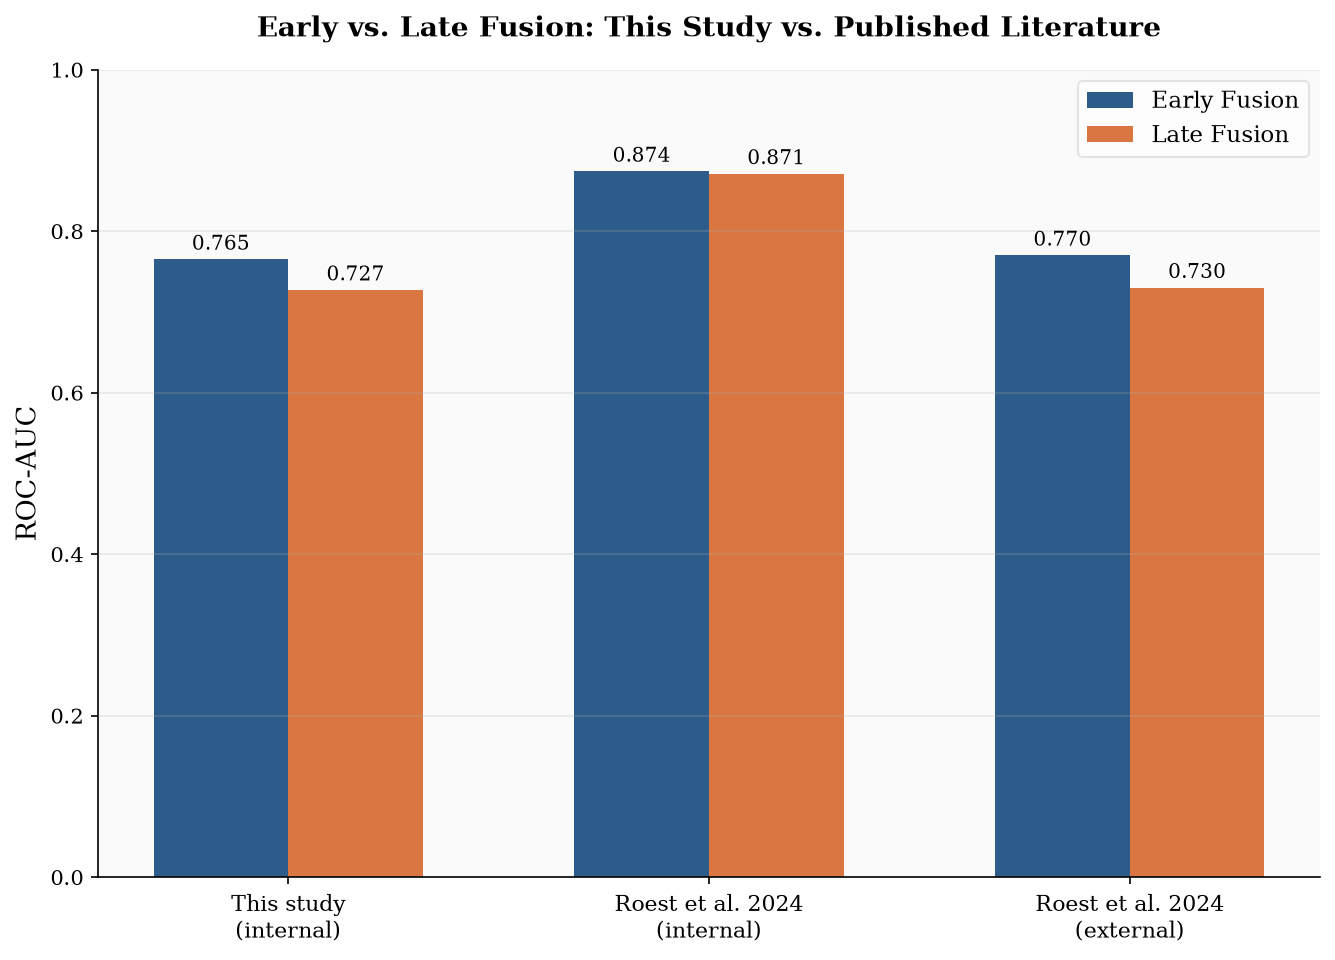

In [15]:
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=150)

studies = ['This study\n(internal)', 'Roest et al. 2024\n(internal)', 'Roest et al. 2024\n(external)']
early_vals = [0.765, 0.874, 0.770]
late_vals = [0.727, 0.871, 0.730]

x = np.arange(len(studies))
width = 0.32

bars_e = ax.bar(x - width/2, early_vals, width, label='Early Fusion', color='#2E5C8A')
bars_l = ax.bar(x + width/2, late_vals, width, label='Late Fusion', color='#D97642')

for bars in [bars_e, bars_l]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f'{h:.3f}', ha='center', fontsize=9.5)

ax.set_xticks(x)
ax.set_xticklabels(studies, fontsize=10.5)
ax.set_ylabel('ROC-AUC', fontsize=13)
ax.set_ylim(0, 1.0)
ax.set_title('Early vs. Late Fusion: This Study vs. Published Literature', fontsize=13.5, fontweight='bold', pad=16)
ax.legend(loc='upper right', fontsize=11, frameon=True, edgecolor='#DDDDDD')
ax.grid(axis='y', alpha=0.25)
ax.set_facecolor('#FAFAFA')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('fusion_comparison_literature.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


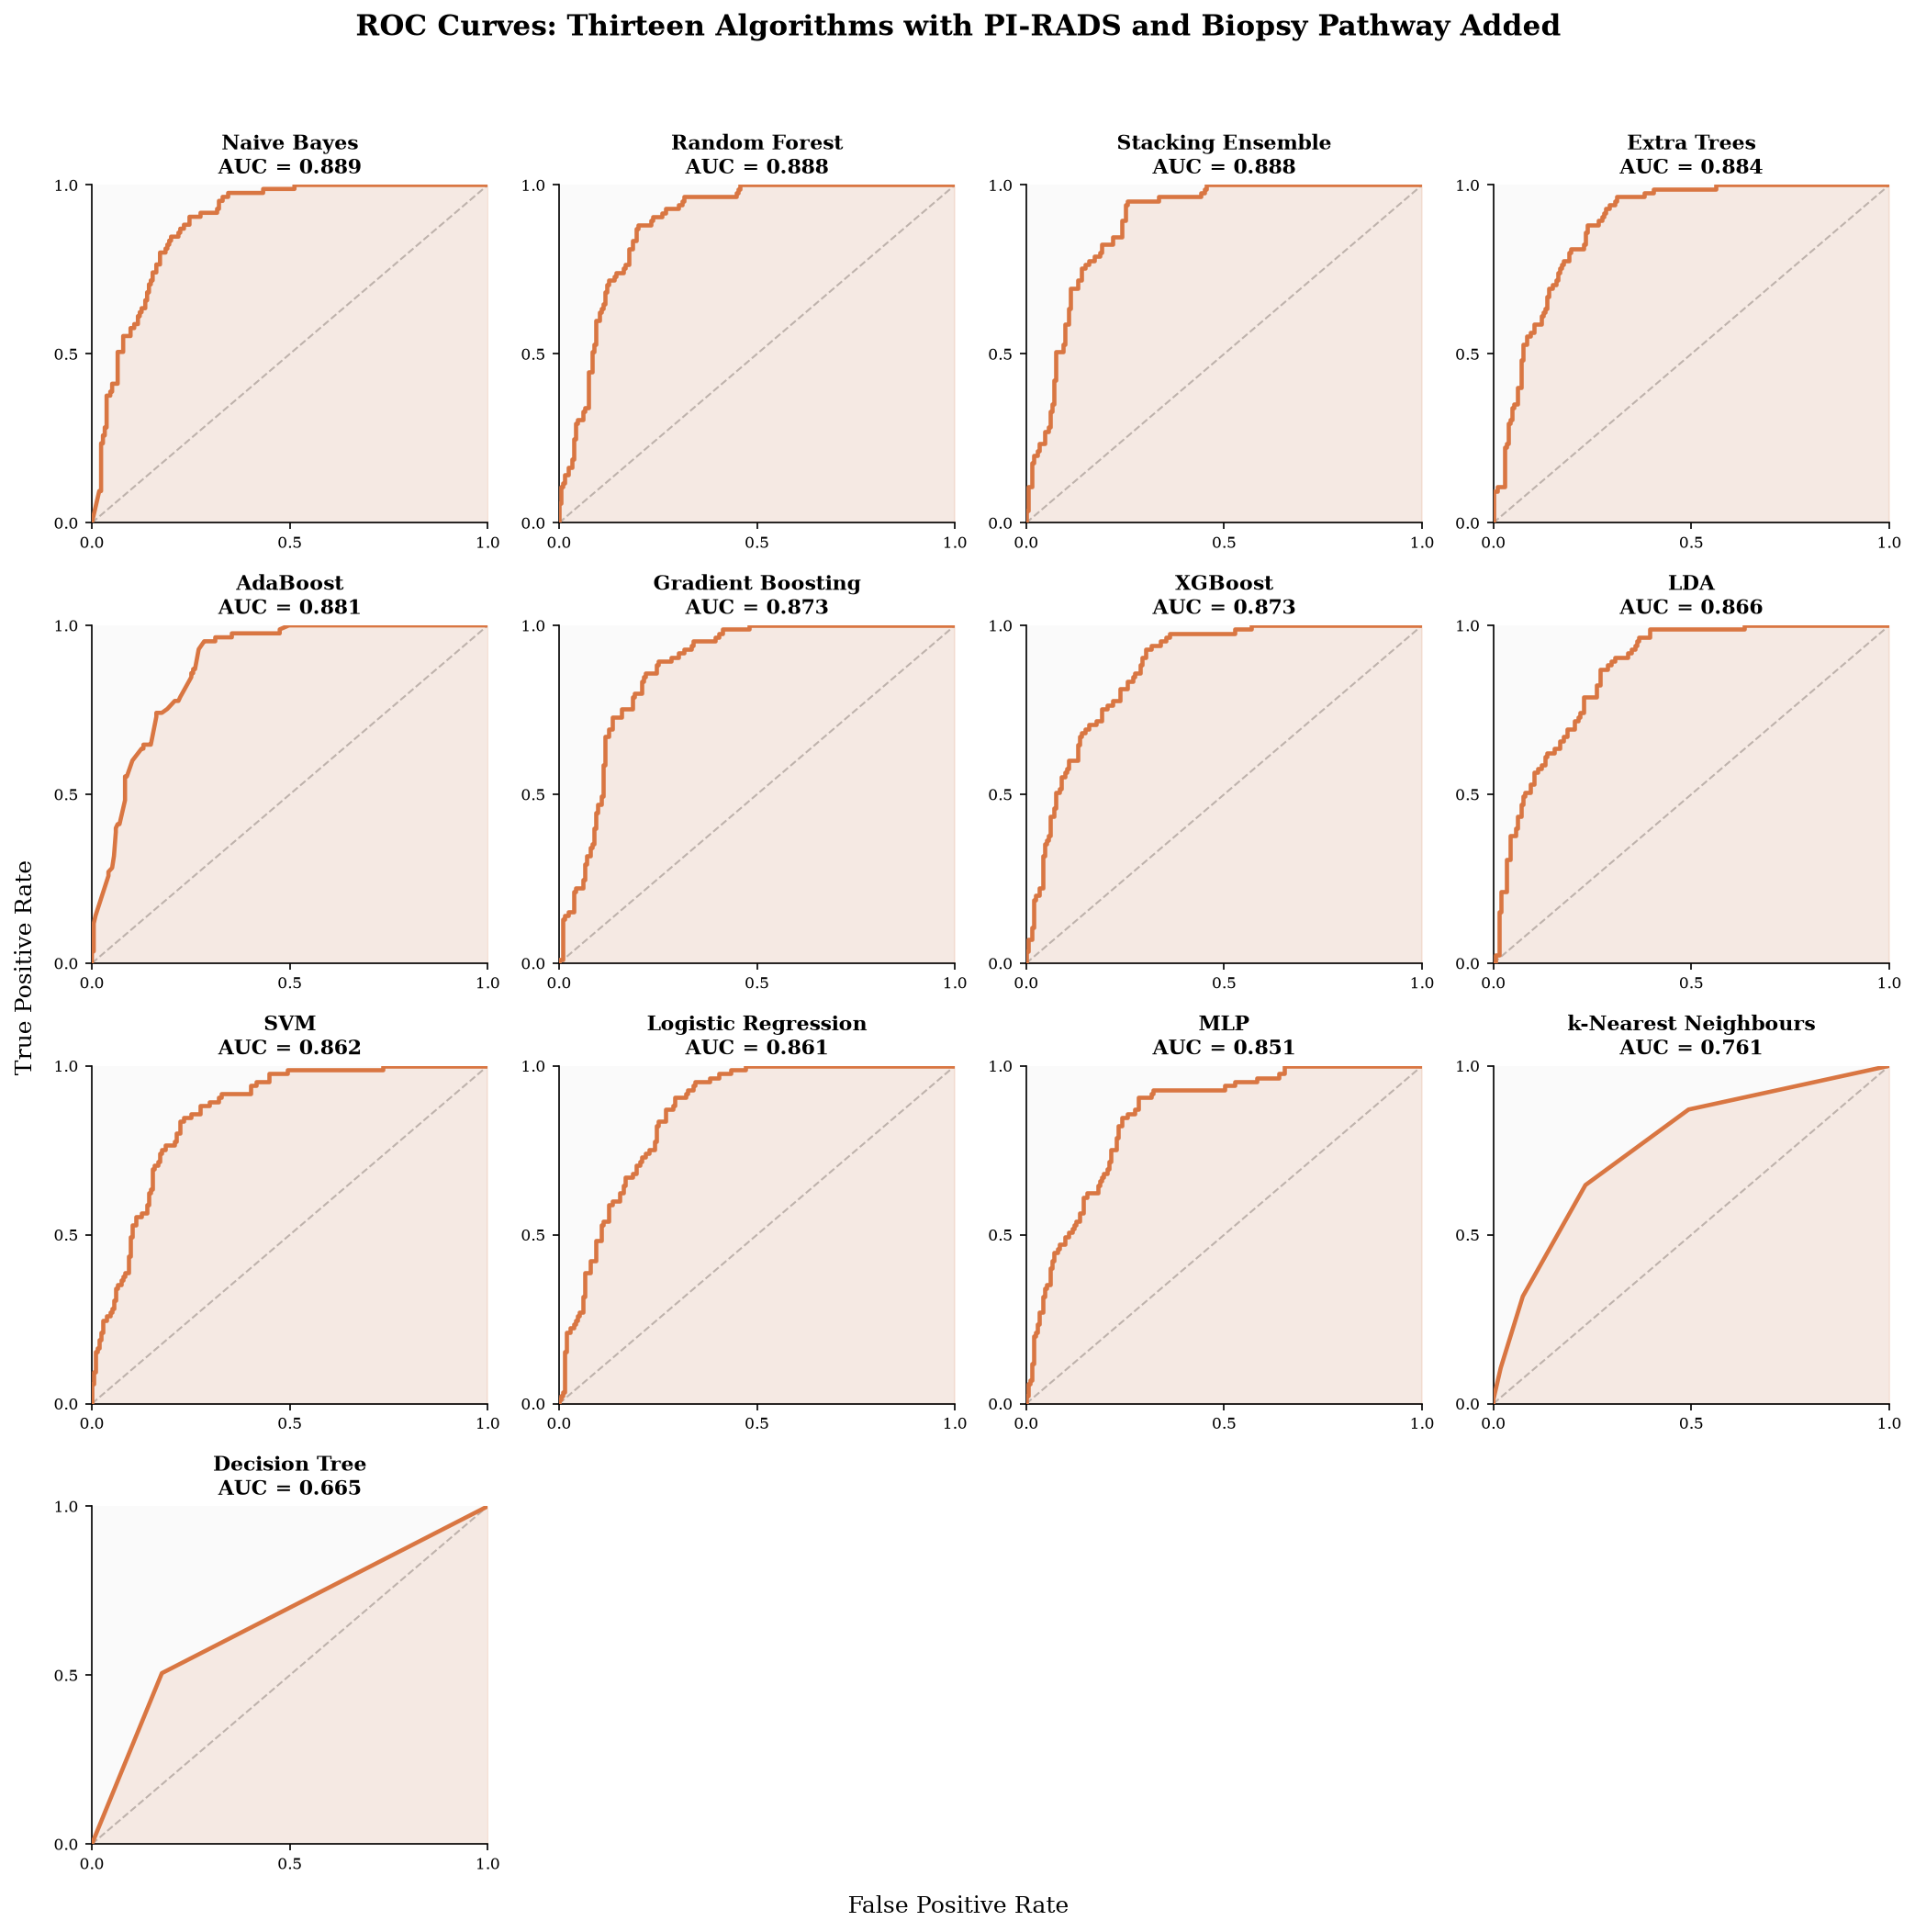

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, roc_auc_score

# --- Rebuild the PI-RADS + biopsy pathway dataset ---
fused_df_reload = pd.read_csv('fused_final_dataset.csv')
picai_raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')

def get_max_pirads(val):
    if pd.isna(val):
        return np.nan
    scores = str(val).split(',')
    return max([int(s.strip()) for s in scores if s.strip().isdigit()])

picai_raw['max_pirads'] = picai_raw['lesion_PIRADS'].apply(get_max_pirads)

fused_with_pirads = fused_df_reload.merge(
    picai_raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_pirads['max_pirads'] = fused_with_pirads['max_pirads'].fillna(fused_with_pirads['max_pirads'].median())

fused_with_histopath = fused_with_pirads.merge(
    picai_raw[['patient_id', 'histopath_type']].drop_duplicates('patient_id'),
    on='patient_id', how='left'
)
fused_with_histopath['histopath_type'] = fused_with_histopath['histopath_type'].fillna('No_Biopsy_Needed')
fused_with_histopath_encoded = pd.get_dummies(fused_with_histopath, columns=['histopath_type'], drop_first=True)

X_final = fused_with_histopath_encoded.drop(columns=['patient_id', 'csPCa_label'])
y_final = fused_with_histopath_encoded['csPCa_label']

X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.2, stratify=y_final, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Train all 13 models ---
models = {
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced'),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.01, subsample=0.8, scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced'),
    'SVM': SVC(probability=True, class_weight='balanced', random_state=42),
    'MLP': MLPClassifier(max_iter=1000, random_state=42),
    'LDA': LinearDiscriminantAnalysis(),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Naive Bayes': GaussianNB(),
    'k-Nearest Neighbours': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
}
models['Stacking Ensemble'] = StackingClassifier(
    estimators=[('rf', models['Random Forest']), ('ada', models['AdaBoost']), ('gb', models['Gradient Boosting'])],
    final_estimator=LogisticRegression(class_weight='balanced'), cv=5
)

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

# --- Small-multiples ROC grid, sorted best to worst ---
plt.rcParams['font.family'] = 'DejaVu Serif'
model_order = sorted(models.keys(), key=lambda name: roc_auc_score(
    y_test, models[name].predict_proba(X_test_scaled)[:, 1]
), reverse=True)

fig, axes = plt.subplots(4, 4, figsize=(14, 14), dpi=150)
axes_flat = axes.flatten()

for i, name in enumerate(model_order):
    ax = axes_flat[i]
    probs = models[name].predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    ax.plot(fpr, tpr, color='#D97642', linewidth=2.2, zorder=3)
    ax.fill_between(fpr, tpr, alpha=0.12, color='#D97642', zorder=2)
    ax.plot([0, 1], [0, 1], linestyle='--', color='#BBBBBB', linewidth=1, zorder=1)

    ax.set_title(f'{name}\nAUC = {auc:.3f}', fontsize=10.5, fontweight='bold', pad=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(labelsize=8)
    ax.set_facecolor('#FAFAFA')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

for j in range(len(model_order), 16):
    axes_flat[j].axis('off')

fig.suptitle('ROC Curves: Thirteen Algorithms with PI-RADS and Biopsy Pathway Added',
             fontsize=15, fontweight='bold', y=0.995)
fig.text(0.5, 0.01, 'False Positive Rate', ha='center', fontsize=12)
fig.text(0.01, 0.5, 'True Positive Rate', va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.02, 0.02, 1, 0.97])
plt.savefig('roc_pirads_biopsy_grid.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

In [1]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    matthews_corrcoef, confusion_matrix, brier_score_loss)

def full_report(model, X, y, name):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"Set": name, "n": len(y), "Prevalence": y.mean(),
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "Specificity": tn / (tn + fp),
            "F1": f1_score(y, pred), "Balanced acc.": balanced_accuracy_score(y, pred),
            "MCC": matthews_corrcoef(y, pred), "ROC-AUC": roc_auc_score(y, prob),
            "PR-AUC": average_precision_score(y, prob), "Brier": brier_score_loss(y, prob)}

rows = [full_report(locked_model, Xp_test_scaled, yp_test, "Internal (PI-CAI test)"),
        full_report(locked_model, X_external_scaled, y_external_final, "External (US cohort)")]
print(pd.DataFrame(rows).round(3).T)

NameError: name 'locked_model' is not defined

In [2]:
# same locked Stacking model and same feature set used for the external run
full_report(locked_stack, X_test_fused_picai, y_test)   # accuracy, precision, recall, AUC + counts

NameError: name 'locked_stack' is not defined

In [3]:
cols_no_path = [c for c in expert_cols if c not in ("biopsy_pathway",)]  # keep PI-RADS, drop pathway
Xtr, Xte = df_train[cols_no_path], df_test[cols_no_path]
results = {}
for name, model in models.items():            # your 13 algorithms, same settings as before
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xte)[:, 1]
    results[name] = dict(auc=roc_auc_score(y_test, p),
                         recall=recall_score(y_test, p >= 0.5),
                         spec=recall_score(1 - y_test, p < 0.5))
pd.DataFrame(results).T.sort_values("auc", ascending=False)

NameError: name 'expert_cols' is not defined

In [4]:
Xp_test_scaled = scaler_locked.transform(Xp_test)      # locked scaler, transform only

rows = [
    full_report(locked_model, Xp_test_scaled,  yp_test,           "Internal (PI-CAI test)"),
    full_report(locked_model, X_external_scaled, y_external_final, "External (US cohort)"),
]
print(pd.DataFrame(rows).round(3).T)

NameError: name 'scaler_locked' is not defined

In [5]:
Xp_test_scaled = scaler_locked.transform(Xp_test)

nopath = run_all_models(Xp_train_scaled, Xp_test_scaled, yp_train, yp_test,
                        'Fused + PI-RADS (no pathway)')

# add the locked Stacking model if it is not already one of the rows
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
pred = locked_model.predict(Xp_test_scaled)
prob = locked_model.predict_proba(Xp_test_scaled)[:, 1]
nopath = pd.concat([nopath, pd.DataFrame([{
    'Dataset': 'Fused + PI-RADS (no pathway)', 'Model': 'Stacking (locked)',
    'Accuracy': accuracy_score(yp_test, pred), 'Precision': precision_score(yp_test, pred),
    'Recall': recall_score(yp_test, pred), 'F1': f1_score(yp_test, pred),
    'ROC-AUC': roc_auc_score(yp_test, prob)}])], ignore_index=True)

print(nopath.sort_values('ROC-AUC', ascending=False).round(3))
nopath.to_csv('results_fused_pirads_no_pathway.csv', index=False)

NameError: name 'scaler_locked' is not defined

In [6]:
import os, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier,
                              ExtraTreesClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, balanced_accuracy_score)

needed = ['fused_final_dataset.csv', 'picai_clinical_clean.csv', 'picai_labels/clinical_information/marksheet.csv',
          'cnn_features_t2w.csv', 'external_validation/external_cnn_features_t2w.csv',
          'external_validation/final_external_cohort.csv']
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Missing (run from ~/prostate-cancer-research): {missing}"

def report(model, X, y, name):
    prob = model.predict_proba(X)[:, 1]; pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"Set": name, "n": len(y), "Prevalence": round(float(np.mean(y)), 3),
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "Specificity": tn / (tn + fp), "F1": f1_score(y, pred),
            "Balanced acc.": balanced_accuracy_score(y, pred), "ROC-AUC": roc_auc_score(y, prob),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}

# ---- 1. PI-CAI data: clinical + imaging + PI-RADS (NO biopsy pathway)
def get_max_pirads(val):
    if pd.isna(val): return np.nan
    s = [int(x.strip()) for x in str(val).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan

fused = pd.read_csv('fused_final_dataset.csv')
raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')
raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left')
fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
X_pirads = fp.drop(columns=['patient_id', 'csPCa_label']); y_pirads = fp['csPCa_label']
Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_pirads, y_pirads, test_size=0.2, stratify=y_pirads, random_state=42)
scaler_locked = StandardScaler(); Xp_train_scaled = scaler_locked.fit_transform(Xp_train)
Xp_test_scaled = scaler_locked.transform(Xp_test)
print("Shapes:", Xp_train_scaled.shape, Xp_test_scaled.shape, "| positives in test:", int(yp_test.sum()))

# ---- 2. Locked Stacking model (same settings as the external validation)
locked_model = StackingClassifier(
    estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
                ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
                ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))],
    final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
locked_model.fit(Xp_train_scaled, yp_train)

# ---- 3. External cohort through the LOCKED scaler + PCA (transform only)
t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
sc_cnn = StandardScaler().fit(t2w[fc]); pca = PCA(n_components=100, random_state=42).fit(sc_cnn.transform(t2w[fc]))
ext_cnn = pd.read_csv('external_validation/external_cnn_features_t2w.csv'); fe = [c for c in ext_cnn.columns if c.startswith('cnn_feat_')]
ext_pca = pd.DataFrame(pca.transform(sc_cnn.transform(ext_cnn[fe])), columns=[f'cnn_pca_{i}' for i in range(100)])
ext_pca['Patient Number'] = ext_cnn['Patient Number'].values
coh = pd.read_csv('external_validation/final_external_cohort.csv')
ext = coh[['Patient Number', 'psa', 'psad', 'prostate_volume', 'max_pirads', 'csPCa_label']].merge(ext_pca, on='Patient Number', how='inner')
ext['patient_age'] = pd.read_csv('picai_clinical_clean.csv')['patient_age'].median()
X_external_scaled = scaler_locked.transform(ext[X_pirads.columns.tolist()]); y_external_final = ext['csPCa_label']

# ---- PART A: locked Stacking, internal vs external, from the same model
A = pd.DataFrame([report(locked_model, Xp_test_scaled, yp_test, "Internal (PI-CAI test)"),
                  report(locked_model, X_external_scaled, y_external_final, "External (US cohort)")])
print(A.round(3).T); A.to_csv('locked_model_internal_vs_external.csv', index=False)
print("CHECK: external AUC should be about 0.745 and accuracy about 0.669")

# ---- PART B: all 13 algorithms, PI-RADS WITHOUT the biopsy pathway (takes several minutes)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mp = {
 'LogisticRegression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.01, 0.1, 1, 10]}),
 'DecisionTree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), {'max_depth': [5, 10, None]}),
 'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
 'ExtraTrees': (ExtraTreesClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
 'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
 'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
 'SVM': (SVC(probability=True, class_weight='balanced'), {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}),
 'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 10, 15]}),
 'NaiveBayes': (GaussianNB(), {}), 'LDA': (LinearDiscriminantAnalysis(), {}),
 'MLP': (MLPClassifier(max_iter=1000, random_state=42), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.001, 0.01]}),
 'XGBoost': (XGBClassifier(scale_pos_weight=2.5, random_state=42, eval_metric='logloss'),
             {'n_estimators': [200, 300], 'max_depth': [3, 5, 6], 'learning_rate': [0.01, 0.1]})}
best = {}
for name, (m, p) in mp.items():
    if p: g = GridSearchCV(m, p, cv=cv, scoring='roc_auc', n_jobs=-1).fit(Xp_train_scaled, yp_train); best[name] = g.best_estimator_
    else: best[name] = m.fit(Xp_train_scaled, yp_train)
    print(name, "done")
best['Stacking'] = StackingClassifier(estimators=[('rf', best['RandomForest']), ('ada', best['AdaBoost']), ('gb', best['GradientBoosting'])],
                                      final_estimator=LogisticRegression(class_weight='balanced'), cv=5).fit(Xp_train_scaled, yp_train)
B = pd.DataFrame([report(m, Xp_test_scaled, yp_test, n) for n, m in best.items()]).rename(columns={'Set': 'Model'})
B = B.sort_values('ROC-AUC', ascending=False)
print(B.drop(columns=['n', 'Prevalence']).round(3).to_string(index=False))
B.to_csv('results_fused_pirads_no_pathway.csv', index=False)

Shapes: (1200, 105) (300, 105) | positives in test: 85
                                    0                     1
Set            Internal (PI-CAI test)  External (US cohort)
n                                 300                   782
Prevalence                      0.283                 0.575
Accuracy                        0.807                 0.669
Precision                       0.603                  0.72
Recall                          0.929                 0.696
Specificity                     0.758                 0.633
F1                              0.731                 0.707
Balanced acc.                   0.844                 0.664
ROC-AUC                         0.884                 0.745
TP                                 79                   313
FN                                  6                   137
FP                                 52                   122
TN                                163                   210
CHECK: external AUC should be about 0.745 and

~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
~/prostate-cancer-research/pca_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `pr

SVM done
KNN done
NaiveBayes done
LDA done
MLP done
XGBoost done
             Model  Accuracy  Precision  Recall  Specificity    F1  Balanced acc.  ROC-AUC  TP  FN  FP  TN
          Stacking     0.797      0.591   0.918        0.749 0.719          0.833    0.887  78   7  54 161
      RandomForest     0.807      0.648   0.694        0.851 0.670          0.773    0.884  59  26  32 183
        ExtraTrees     0.813      0.649   0.741        0.842 0.692          0.792    0.879  63  22  34 181
  GradientBoosting     0.807      0.671   0.624        0.879 0.646          0.751    0.878  53  32  26 189
           XGBoost     0.780      0.569   0.918        0.726 0.703          0.822    0.873  78   7  59 156
          AdaBoost     0.803      0.644   0.682        0.851 0.663          0.767    0.873  58  27  32 183
               SVM     0.810      0.694   0.588        0.898 0.637          0.743    0.857  50  35  22 193
LogisticRegression     0.750      0.539   0.812        0.726 0.648          0.7

In [1]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, accuracy_score, precision_score

def make_locked():
    return StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
        ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))],
        final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
def metrics(m, X, y):
    p = m.predict_proba(X)[:, 1]; h = (p >= 0.5).astype(int)
    return dict(n=len(y), AUC=round(roc_auc_score(y, p), 3), Recall=round(recall_score(y, h), 3), Precision=round(precision_score(y, h), 3), Accuracy=round(accuracy_score(y, h), 3))
def get_max_pirads(v):
    if pd.isna(v): return np.nan
    s = [int(x.strip()) for x in str(v).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan

fused = pd.read_csv('fused_final_dataset.csv'); raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv'); cc = pd.read_csv('picai_clinical_clean.csv')
raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left')
fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
ids = fp['patient_id'].reset_index(drop=True); X = fp.drop(columns=['patient_id', 'csPCa_label']).reset_index(drop=True); y = fp['csPCa_label'].reset_index(drop=True)

print("== 1. IDENTIFIERS")
print("fused rows:", len(fused), "| unique patient_id:", fused['patient_id'].nunique(), "| patients with >1 study:", int(fused.duplicated('patient_id', keep=False).sum()))
print("marksheet rows:", len(raw), "| unique patient_id:", raw['patient_id'].nunique(), "| columns:", [c for c in raw.columns if 'id' in c.lower()])
print("rows in fused after PI-RADS merge:", len(fp), "(should equal", len(fused), ")")
cc2 = cc[['patient_id', 'center']].drop_duplicates(); print("patients appearing in >1 centre:", int((cc2.groupby('patient_id')['center'].nunique() > 1).sum()))
print("\n== 2. IMPUTATION (full-data median vs value found in cleaned table)")
for col in ['patient_age', 'psa', 'psad', 'prostate_volume']:
    if col in raw.columns and col in cc.columns:
        miss = raw.loc[raw[col].isna(), 'patient_id']; sub = cc[cc['patient_id'].isin(miss)][col]
        print(f"{col}: raw missing {int(raw[col].isna().sum())} | cleaned values at those rows (unique): {sub.round(3).unique()[:4]} | full-data median {raw[col].median():.3f}")
print("missing values left in fused table:", int(fused.isna().sum().sum()))

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
tr_ids, te_ids = set(ids.loc[Xtr.index]), ids.loc[Xte.index]
overlap = tr_ids & set(te_ids)
print("\n== 3. PATIENT OVERLAP IN THE 80/20 SPLIT")
print("patients in BOTH train and test:", len(overlap), "| test studies affected:", int(te_ids.isin(overlap).sum()))
sc = StandardScaler().fit(Xtr); m0 = make_locked().fit(sc.transform(Xtr), ytr)
print("original test set:", metrics(m0, sc.transform(Xte), yte))
keep = ~te_ids.isin(tr_ids).values
print("test set without patients seen in training:", metrics(m0, sc.transform(Xte[keep]), yte[keep]))

print("\n== 4. PREPROCESSING AND PATIENT-LEVEL SPLIT SENSITIVITY")
t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
if 'patient_id' in t2w.columns and t2w['patient_id'].is_unique and set(fp['patient_id']) <= set(t2w['patient_id']): F = t2w.set_index('patient_id').loc[fp['patient_id'], fc].to_numpy()
elif len(t2w) == len(fp): F = t2w[fc].to_numpy(); print("WARNING: imaging features aligned by row order, not by ID")
else: raise SystemExit("cannot align imaging features")
clin = [c for c in X.columns if not c.startswith('cnn_pca_')]
def fit_eval(tr_i, te_i, refit_pca, label):
    if refit_pca:
        s = StandardScaler().fit(F[tr_i]); p = PCA(n_components=100, random_state=42).fit(s.transform(F[tr_i]))
        Atr = np.hstack([X.iloc[tr_i][clin].to_numpy(), p.transform(s.transform(F[tr_i]))]); Ate = np.hstack([X.iloc[te_i][clin].to_numpy(), p.transform(s.transform(F[te_i]))])
    else: Atr, Ate = X.iloc[tr_i].to_numpy(), X.iloc[te_i].to_numpy()
    s2 = StandardScaler().fit(Atr); m = make_locked().fit(s2.transform(Atr), y.iloc[tr_i]); print(label, metrics(m, s2.transform(Ate), y.iloc[te_i]))
tr_i, te_i = Xtr.index.to_numpy(), Xte.index.to_numpy()
fit_eval(tr_i, te_i, True, "same split, PCA/scaler refitted on training studies only:")
g_tr, g_te = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups=ids))
print("grouped split: patients in both sets =", len(set(ids.iloc[g_tr]) & set(ids.iloc[g_te])))
fit_eval(g_tr, g_te, False, "patient-grouped split, original PCA features:")
fit_eval(g_tr, g_te, True, "patient-grouped split, PCA refitted on training only:")

== 1. IDENTIFIERS
fused rows: 1500 | unique patient_id: 1476 | patients with >1 study: 47
marksheet rows: 1500 | unique patient_id: 1476 | columns: ['patient_id', 'study_id']
rows in fused after PI-RADS merge: 1500 (should equal 1500 )
patients appearing in >1 centre: 0

== 2. IMPUTATION (full-data median vs value found in cleaned table)
patient_age: raw missing 0 | cleaned values at those rows (unique): [] | full-data median 66.000
psa: raw missing 40 | cleaned values at those rows (unique): [ 8.5  8.7 11. ] | full-data median 8.500
psad: raw missing 451 | cleaned values at those rows (unique): [0.14  0.182 0.2   0.209] | full-data median 0.140
prostate_volume: raw missing 27 | cleaned values at those rows (unique): [57. 50.] | full-data median 57.000
missing values left in fused table: 0

== 3. PATIENT OVERLAP IN THE 80/20 SPLIT
patients in BOTH train and test: 8 | test studies affected: 8
original test set: {'n': 300, 'AUC': 0.884, 'Recall': 0.929, 'Precision': 0.603, 'Accuracy': 0.

In [2]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score
fused = pd.read_csv('fused_final_dataset.csv'); cc = pd.read_csv('picai_clinical_clean.csv')[['patient_id', 'center']].drop_duplicates('patient_id')
t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
if 'patient_id' in t2w.columns and t2w['patient_id'].is_unique: F = t2w.set_index('patient_id').loc[fused['patient_id'], fc].to_numpy()
else: F = t2w[fc].to_numpy(); print("WARNING: aligned by row order")
df = fused.merge(cc, on='patient_id', how='left'); assert len(df) == len(fused)
clin = ['patient_age', 'psa', 'psad', 'prostate_volume']; pcs = [c for c in fused.columns if c.startswith('cnn_pca_')]
for held in ['RUMC', 'PCNN', 'ZGT']:
    tr = (df['center'] != held).to_numpy(); te = ~tr; y = df['csPCa_label'].to_numpy()
    for mode in ('original PCA (all centres)', 'PCA refitted on training centres'):
        if mode.startswith('original'): A = df[clin + pcs].to_numpy()
        else:
            s = StandardScaler().fit(F[tr]); p = PCA(n_components=len(pcs), random_state=42).fit(s.transform(F[tr]))
            A = np.hstack([df[clin].to_numpy(), p.transform(s.transform(F))])
        sc = StandardScaler().fit(A[tr]); m = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced').fit(sc.transform(A[tr]), y[tr])
        pr = m.predict_proba(sc.transform(A[te]))[:, 1]; print(held, '|', mode, '| AUC', round(roc_auc_score(y[te], pr), 3), '| recall', round(recall_score(y[te], pr >= 0.5), 3))

RUMC | original PCA (all centres) | AUC 0.732 | recall 0.242
RUMC | PCA refitted on training centres | AUC 0.727 | recall 0.284
PCNN | original PCA (all centres) | AUC 0.585 | recall 0.44
PCNN | PCA refitted on training centres | AUC 0.592 | recall 0.358
ZGT | original PCA (all centres) | AUC 0.779 | recall 0.6
ZGT | PCA refitted on training centres | AUC 0.778 | recall 0.688


In [3]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
fused = pd.read_csv('fused_final_dataset.csv'); cc = pd.read_csv('picai_clinical_clean.csv')
naive = fused.merge(cc[['patient_id', 'center']], on='patient_id', how='left')
print("rows after the ORIGINAL merge:", len(naive), "| rows in fused:", len(fused), "| rows in clinical_clean:", len(cc))
df = fused.merge(cc[['patient_id', 'center']].drop_duplicates('patient_id'), on='patient_id', how='left'); assert len(df) == len(fused)
print("studies per centre:", df['center'].value_counts().to_dict())
clin = ['patient_age', 'psa', 'psad', 'prostate_volume']; pcs = [c for c in df.columns if c.startswith('cnn_pca_')]
print("PCA components in file:", len(pcs))
sets = {'Clinical only': clin, 'Imaging only': pcs, 'Fused': clin + pcs}; rows = []
for held in ['RUMC', 'PCNN', 'ZGT']:
    tr = (df['center'] != held).to_numpy(); te = ~tr; y = df['csPCa_label'].to_numpy()
    for name, cols in sets.items():
        A = df[cols].to_numpy(); sc = StandardScaler().fit(A[tr])
        m = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced').fit(sc.transform(A[tr]), y[tr])
        p = m.predict_proba(sc.transform(A[te]))[:, 1]; h = (p >= 0.5).astype(int)
        rows.append(dict(Held_out=held, Features=name, Train=int(tr.sum()), Test=int(te.sum()), Test_pos=int(y[te].sum()),
                         Accuracy=round(accuracy_score(y[te], h), 3), Precision=round(precision_score(y[te], h, zero_division=0), 3),
                         Recall=round(recall_score(y[te], h), 3), F1=round(f1_score(y[te], h), 3), ROC_AUC=round(roc_auc_score(y[te], p), 3)))
print(pd.DataFrame(rows).to_string(index=False))

rows after the ORIGINAL merge: 1550 | rows in fused: 1500 | rows in clinical_clean: 1500
studies per centre: {'RUMC': 800, 'PCNN': 350, 'ZGT': 350}
PCA components in file: 100
Held_out      Features  Train  Test  Test_pos  Accuracy  Precision  Recall    F1  ROC_AUC
    RUMC Clinical only    700   800       236     0.735      0.561   0.470 0.512    0.685
    RUMC  Imaging only    700   800       236     0.705      0.500   0.034 0.063    0.578
    RUMC         Fused    700   800       236     0.746      0.704   0.242 0.360    0.732
    PCNN Clinical only   1150   350       109     0.586      0.401   0.670 0.502    0.623
    PCNN  Imaging only   1150   350       109     0.666      0.214   0.028 0.049    0.516
    PCNN         Fused   1150   350       109     0.620      0.400   0.440 0.419    0.585
     ZGT Clinical only   1150   350        80     0.649      0.359   0.688 0.472    0.707
     ZGT  Imaging only   1150   350        80     0.726      0.346   0.225 0.273    0.629
     ZGT      

In [4]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score
fused = pd.read_csv('fused_final_dataset.csv'); t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
if 'patient_id' in t2w.columns and t2w['patient_id'].is_unique: F = t2w.set_index('patient_id').loc[fused['patient_id'], fc].to_numpy()
else: F = t2w[fc].to_numpy(); print("WARNING: aligned by row order")
clin = fused[['patient_age', 'psa', 'psad', 'prostate_volume']].to_numpy(); y = fused['csPCa_label'].to_numpy()
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
s = StandardScaler().fit(F[tr]); Ztr_all = s.transform(F[tr]); Zte_all = s.transform(F[te])
for k in (10, 25, 50, 100, 200, 387):
    p = PCA(n_components=k, random_state=42).fit(Ztr_all)
    for name, A_tr, A_te in (('imaging only', p.transform(Ztr_all), p.transform(Zte_all)), ('fused', np.hstack([clin[tr], p.transform(Ztr_all)]), np.hstack([clin[te], p.transform(Zte_all)]))):
        sc = StandardScaler().fit(A_tr); m = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced').fit(sc.transform(A_tr), y[tr])
        pr = m.predict_proba(sc.transform(A_te))[:, 1]; print(k, name, 'AUC', round(roc_auc_score(y[te], pr), 3), 'recall', round(recall_score(y[te], pr >= 0.5), 3), '| variance kept', round(p.explained_variance_ratio_.sum(), 2))

10 imaging only AUC 0.595 recall 0.376 | variance kept 0.36
10 fused AUC 0.789 recall 0.671 | variance kept 0.36
25 imaging only AUC 0.59 recall 0.306 | variance kept 0.49
25 fused AUC 0.784 recall 0.6 | variance kept 0.49
50 imaging only AUC 0.631 recall 0.235 | variance kept 0.6
50 fused AUC 0.79 recall 0.541 | variance kept 0.6
100 imaging only AUC 0.652 recall 0.212 | variance kept 0.71
100 fused AUC 0.79 recall 0.529 | variance kept 0.71
200 imaging only AUC 0.639 recall 0.106 | variance kept 0.82
200 fused AUC 0.775 recall 0.482 | variance kept 0.82
387 imaging only AUC 0.594 recall 0.012 | variance kept 0.91
387 fused AUC 0.759 recall 0.271 | variance kept 0.91


In [5]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, precision_score

def get_max_pirads(v):
    if pd.isna(v): return np.nan
    s = [int(x.strip()) for x in str(v).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan
def make_locked():
    return StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
        ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)), ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))],
        final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
rf = lambda: RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')

# ---- rebuild internal and external data exactly as for the locked model
fused = pd.read_csv('fused_final_dataset.csv'); raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv'); cc = pd.read_csv('picai_clinical_clean.csv')
raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left'); fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
X = fp.drop(columns=['patient_id', 'csPCa_label']).reset_index(drop=True); y = fp['csPCa_label'].reset_index(drop=True)
cols = X.columns.tolist(); pcs = [c for c in cols if c.startswith('cnn_pca_')]; clin3 = ['psa', 'psad', 'prostate_volume']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
sc_cnn = StandardScaler().fit(t2w[fc]); pca = PCA(n_components=100, random_state=42).fit(sc_cnn.transform(t2w[fc]))
ecnn = pd.read_csv('external_validation/external_cnn_features_t2w.csv'); fe = [c for c in ecnn.columns if c.startswith('cnn_feat_')]
epca = pd.DataFrame(pca.transform(sc_cnn.transform(ecnn[fe])), columns=[f'cnn_pca_{i}' for i in range(100)]); epca['Patient Number'] = ecnn['Patient Number'].values
coh = pd.read_csv('external_validation/final_external_cohort.csv')
ext = coh[['Patient Number', 'psa', 'psad', 'prostate_volume', 'max_pirads', 'csPCa_label']].merge(epca, on='Patient Number', how='inner'); ext['patient_age'] = cc['patient_age'].median()
Xex = ext[cols].reset_index(drop=True); yex = ext['csPCa_label'].reset_index(drop=True)
print("internal test:", len(yte), "| external:", len(yex), "| prevalence internal/external:", round(y.mean(), 3), round(yex.mean(), 3))

# ---- A. locked model, uncertainty, calibration, prevalence
sc = StandardScaler().fit(Xtr); locked = make_locked().fit(sc.transform(Xtr), ytr)
pin = locked.predict_proba(sc.transform(Xte))[:, 1]; pex = locked.predict_proba(sc.transform(Xex))[:, 1]
def boot_diff(B=1000):
    r = np.random.default_rng(0); yi, yx = np.asarray(yte), np.asarray(yex); out, ai, ae = [], [], []
    for _ in range(B):
        i = r.integers(0, len(yi), len(yi)); j = r.integers(0, len(yx), len(yx))
        if yi[i].min() == yi[i].max() or yx[j].min() == yx[j].max(): continue
        a, b = roc_auc_score(yi[i], pin[i]), roc_auc_score(yx[j], pex[j]); ai.append(a); ae.append(b); out.append(a - b)
    return np.percentile(ai, [2.5, 97.5]), np.percentile(ae, [2.5, 97.5]), np.percentile(out, [2.5, 97.5])
ci_i, ci_e, ci_d = boot_diff()
print("\n== A. UNCERTAINTY")
print("internal AUC %.3f (95%% CI %.3f-%.3f) | external AUC %.3f (%.3f-%.3f) | drop %.3f (95%% CI %.3f-%.3f)" % (roc_auc_score(yte, pin), *ci_i, roc_auc_score(yex, pex), *ci_e, roc_auc_score(yte, pin) - roc_auc_score(yex, pex), *ci_d))
for nm, yy, pp in (('internal', yte, pin), ('external', yex, pex)):
    z = np.log(np.clip(pp, 1e-6, 1 - 1e-6) / (1 - np.clip(pp, 1e-6, 1 - 1e-6))); lr = LogisticRegression(C=1e6).fit(z.reshape(-1, 1), yy)
    print(f"{nm}: mean predicted risk {pp.mean():.3f} vs observed {np.mean(yy):.3f} | calibration slope {lr.coef_[0][0]:.2f}, intercept {lr.intercept_[0]:.2f}")
sens_i = recall_score(yte, pin >= .5); spec_i = recall_score(1 - np.asarray(yte), pin < .5); prev_e = yex.mean()
ppv_expected = sens_i * prev_e / (sens_i * prev_e + (1 - spec_i) * (1 - prev_e))
print("precision expected at external prevalence if internal sensitivity/specificity held: %.3f | observed external precision: %.3f" % (ppv_expected, precision_score(yex, pex >= .5)))
thr = np.quantile(pex[np.asarray(yex) == 0], spec_i); print("external recall at the internal specificity (%.3f): %.3f (at 0.5: %.3f)" % (spec_i, np.mean(pex[np.asarray(yex) == 1] > thr), recall_score(yex, pex >= .5)))

# ---- B. which inputs transfer (Random Forest ablations; AUC internal vs external)
print("\n== B. INPUT ABLATIONS (Random Forest)")
sets = {'all inputs (as locked)': cols, 'without age': [c for c in cols if c != 'patient_age'], 'without imaging': [c for c in cols if c not in pcs], 'without PI-RADS/UCLA score': [c for c in cols if c != 'max_pirads'],
        'clinical only (PSA, PSAD, volume)': clin3, 'score only': ['max_pirads'], 'imaging only': pcs}
for nm, cl in sets.items():
    s = StandardScaler().fit(Xtr[cl]); m = rf().fit(s.transform(Xtr[cl]), ytr)
    ai = roc_auc_score(yte, m.predict_proba(s.transform(Xte[cl]))[:, 1]); ae = roc_auc_score(yex, m.predict_proba(s.transform(Xex[cl]))[:, 1]); print(f"{nm:38s} internal {ai:.3f} | external {ae:.3f} | drop {ai - ae:+.3f}")
print("raw score alone, AUC: internal %.3f | external %.3f" % (roc_auc_score(y, X['max_pirads']), roc_auc_score(yex, Xex['max_pirads'])))

# ---- C. cohort shift
print("\n== C. COHORT SHIFT")
for c in clin3 + ['max_pirads']:
    a, b = X[c].to_numpy(), Xex[c].to_numpy(); sd = np.sqrt((a.var() + b.var()) / 2)
    print(f"{c:16s} internal mean {a.mean():7.2f} | external mean {b.mean():7.2f} | standardised difference {(b.mean() - a.mean()) / sd:+.2f} | KS {ks_2samp(a, b).statistic:.2f}")
tab = pd.DataFrame({'internal n': X['max_pirads'].round().value_counts(), 'external n': Xex['max_pirads'].round().value_counts()}).fillna(0).astype(int).sort_index()
tab['internal csPCa rate'] = [round(y[X['max_pirads'].round() == k].mean(), 3) if (X['max_pirads'].round() == k).any() else np.nan for k in tab.index]
tab['external csPCa rate'] = [round(yex[Xex['max_pirads'].round() == k].mean(), 3) if (Xex['max_pirads'].round() == k).any() else np.nan for k in tab.index]
print(tab.to_string())
D = pd.concat([X.assign(dom=0), Xex.assign(dom=1)], ignore_index=True)
print("domain classifier AUC (0.5 = cohorts indistinguishable):")
for nm, cl in {'clinical (PSA, PSAD, volume)': clin3, 'score only': ['max_pirads'], 'imaging PCA components': pcs, 'all inputs except age': [c for c in cols if c != 'patient_age']}.items():
    A = StandardScaler().fit_transform(D[cl]); pr = cross_val_predict(LogisticRegression(max_iter=3000), A, D['dom'], cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
    print(f"  {nm:32s} {roc_auc_score(D['dom'], pr):.3f}")

# ---- D. is the internal figure optimistic?
print("\n== D. OPTIMISM CHECK (Random Forest, all inputs)")
cvp = cross_val_predict(rf(), sc.transform(Xtr), ytr, cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
m = rf().fit(sc.transform(Xtr), ytr); print("5-fold CV AUC on training data %.3f | test-partition AUC %.3f" % (roc_auc_score(ytr, cvp), roc_auc_score(yte, m.predict_proba(sc.transform(Xte))[:, 1])))

internal test: 300 | external: 782 | prevalence internal/external: 0.283 0.575

== A. UNCERTAINTY
internal AUC 0.884 (95% CI 0.845-0.920) | external AUC 0.745 (0.709-0.778) | drop 0.138 (95% CI 0.090-0.187)
internal: mean predicted risk 0.423 vs observed 0.283 | calibration slope 1.14, intercept -1.08
external: mean predicted risk 0.530 vs observed 0.575 | calibration slope 0.75, intercept 0.24
precision expected at external prevalence if internal sensitivity/specificity held: 0.839 | observed external precision: 0.720
external recall at the internal specificity (0.758): 0.604 (at 0.5: 0.696)

== B. INPUT ABLATIONS (Random Forest)
all inputs (as locked)                 internal 0.889 | external 0.738 | drop +0.151
without age                            internal 0.885 | external 0.729 | drop +0.156
without imaging                        internal 0.882 | external 0.748 | drop +0.133
without PI-RADS/UCLA score             internal 0.759 | external 0.694 | drop +0.064
clinical only (PSA, P

In [6]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from scipy.stats import t as tdist, binomtest
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

def get_max_pirads(v):
    if pd.isna(v): return np.nan
    s = [int(x.strip()) for x in str(v).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan
def make_locked():
    return StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')),
        ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)), ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))],
        final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
if 'Xex' not in globals():
    fused = pd.read_csv('fused_final_dataset.csv'); raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv'); cc = pd.read_csv('picai_clinical_clean.csv')
    raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
    fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left'); fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
    X = fp.drop(columns=['patient_id', 'csPCa_label']).reset_index(drop=True); y = fp['csPCa_label'].reset_index(drop=True); cols = X.columns.tolist()
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
    sc_cnn = StandardScaler().fit(t2w[fc]); pca = PCA(n_components=100, random_state=42).fit(sc_cnn.transform(t2w[fc]))
    ecnn = pd.read_csv('external_validation/external_cnn_features_t2w.csv'); fe = [c for c in ecnn.columns if c.startswith('cnn_feat_')]
    epca = pd.DataFrame(pca.transform(sc_cnn.transform(ecnn[fe])), columns=[f'cnn_pca_{i}' for i in range(100)]); epca['Patient Number'] = ecnn['Patient Number'].values
    coh = pd.read_csv('external_validation/final_external_cohort.csv')
    ext = coh[['Patient Number', 'psa', 'psad', 'prostate_volume', 'max_pirads', 'csPCa_label']].merge(epca, on='Patient Number', how='inner'); ext['patient_age'] = cc['patient_age'].median()
    Xex = ext[cols].reset_index(drop=True); yex = ext['csPCa_label'].reset_index(drop=True)

X2, Xex2 = X.assign(logpsa=np.log(X['psa'])), Xex.assign(logpsa=np.log(Xex['psa']))
Xtr2, Xte2 = X2.loc[Xtr.index], X2.loc[Xte.index]; ytr_, yte_, yex_ = np.asarray(ytr), np.asarray(yte), np.asarray(yex)
LRm = lambda: LogisticRegression(max_iter=2000, class_weight='balanced')
RFm = lambda: RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
fused_cols = [c for c in cols if c != 'max_pirads']; CL3 = ['patient_age', 'logpsa', 'prostate_volume']
def fit_pred(cl, kind):
    s = StandardScaler().fit(Xtr2[cl]); m = kind().fit(s.transform(Xtr2[cl]), ytr_)
    return m.predict_proba(s.transform(Xte2[cl]))[:, 1], m.predict_proba(s.transform(Xex2[cl]))[:, 1]
spec = {'LR: age, log PSA, volume': (CL3, LRm), 'LR: PSA density alone': (['psad'], LRm), 'RF: clinical (age, PSA, PSAD, volume)': (['patient_age', 'psa', 'psad', 'prostate_volume'], RFm),
        'LR: PI-RADS + PSA density': (['max_pirads', 'psad'], LRm), 'LR: age, log PSA, volume + PI-RADS': (CL3 + ['max_pirads'], LRm),
        'RF: fused (fully automated)': (fused_cols, RFm), 'Stacking: fused (fully automated)': (fused_cols, make_locked), 'Stacking: PI-RADS-informed (locked)': (cols, make_locked)}
P_te, P_ex = {}, {}
for nm, (cl, kind) in spec.items(): P_te[nm], P_ex[nm] = fit_pred(cl, kind); print("fitted:", nm)
def rules(D):
    return {'Rule: PSA density >= 0.15': (D['psad'] >= .15).astype(float).to_numpy(), 'Rule: PI-RADS >= 3': (D['max_pirads'] >= 3).astype(float).to_numpy(), 'Rule: PI-RADS >= 4': (D['max_pirads'] >= 4).astype(float).to_numpy(),
            'Rule: PI-RADS >= 4, or 3 with PSA density >= 0.15': ((D['max_pirads'] >= 4) | ((D['max_pirads'] >= 3) & (D['psad'] >= .15))).astype(float).to_numpy(), 'PI-RADS score alone (ROC-AUC only)': D['max_pirads'].to_numpy(dtype=float)}
P_te.update(rules(Xte2)); P_ex.update(rules(Xex2))

rng = np.random.default_rng(7); B = 2000
def strat_idx(v):
    pos, neg = np.where(v == 1)[0], np.where(v == 0)[0]
    return [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(B)]
IDX_te, IDX_ex = strat_idx(yte_), strat_idx(yex_)
def metr(v, s, thr=0.5):
    h = s >= thr; tp = (h & (v == 1)).sum(); fn = ((~h) & (v == 1)).sum(); fp = (h & (v == 0)).sum(); tn = ((~h) & (v == 0)).sum()
    return tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
def summarize(P, v, IDX, names):
    rows = []
    for nm in names:
        s = P[nm]; aucs = np.array([roc_auc_score(v[i], s[i]) for i in IDX]); row = [nm, f"{roc_auc_score(v, s):.3f} ({np.percentile(aucs, 2.5):.3f}-{np.percentile(aucs, 97.5):.3f})"]
        if 'score alone' in nm: row += ['-', '-', '-']
        else:
            ms = np.array([metr(v[i], s[i]) for i in IDX]); m0 = metr(v, s)
            row += [f"{m0[k]:.3f} ({np.percentile(ms[:, k], 2.5):.3f}-{np.percentile(ms[:, k], 97.5):.3f})" for k in range(3)]
        rows.append(row)
    return pd.DataFrame(rows, columns=['Model', 'ROC-AUC (95% CI)', 'Recall', 'Specificity', 'Precision'])
def paired(P, v, IDX, a, b):
    da = np.array([roc_auc_score(v[i], P[a][i]) - roc_auc_score(v[i], P[b][i]) for i in IDX]); d0 = roc_auc_score(v, P[a]) - roc_auc_score(v, P[b])
    return d0, np.percentile(da, 2.5), np.percentile(da, 97.5), min(1.0, 2 * max(min((da <= 0).mean(), (da >= 0).mean()), 1 / B))
def holm(ps):
    o = np.argsort(ps); adj = np.empty(len(ps)); run = 0
    for r, i in enumerate(o): run = max(run, (len(ps) - r) * ps[i]); adj[i] = min(1, run)
    return adj
LK, ST, RFF, RFC = 'Stacking: PI-RADS-informed (locked)', 'Stacking: fused (fully automated)', 'RF: fused (fully automated)', 'RF: clinical (age, PSA, PSAD, volume)'
planned = [('LR: age, log PSA, volume', RFF), ('LR: age, log PSA, volume', ST), (RFC, RFF), (ST, 'LR: age, log PSA, volume'), (LK, ST), (LK, 'PI-RADS score alone (ROC-AUC ONLY)'.replace('ONLY', 'only')), (LK, 'LR: PI-RADS + PSA density'), (LK, 'LR: age, log PSA, volume + PI-RADS')]
planned = [(a, b) for a, b in planned if a in P_te and b in P_te]
names_te = list(P_te)
print("\n=== 1. HOLD-OUT TEST PARTITION (n=300, 85 positive): 95% bootstrap intervals"); print(summarize(P_te, yte_, IDX_te, names_te).to_string(index=False))
res = [paired(P_te, yte_, IDX_te, a, b) for a, b in planned]; adj = holm([r[3] for r in res])
print("\n=== 2. PLANNED PAIRED COMPARISONS OF ROC-AUC (first minus second; paired bootstrap; Holm-adjusted p)")
for (a, b), r, q in zip(planned, res, adj): print(f"{a}  vs  {b}: diff {r[0]:+.3f} (95% CI {r[1]:+.3f} to {r[2]:+.3f}) | p {r[3]:.4f} | Holm p {q:.4f}")
def mcnemar(v, sa, sb):
    ha, hb = sa >= .5, sb >= .5; out = []
    for lab, mask, f in (('recall', v == 1, lambda h: h), ('specificity', v == 0, lambda h: ~h)):
        ca, cb = f(ha)[mask], f(hb)[mask]; b_, c_ = int((ca & ~cb).sum()), int((~ca & cb).sum()); out.append(f"{lab}: model-only-correct {b_}, rule-only-correct {c_}, exact McNemar p {binomtest(min(b_, c_), b_ + c_, .5).pvalue if b_ + c_ else 1.0:.4f}")
    return '; '.join(out)
print("\n=== 3. EXACT McNEMAR (default threshold): locked PI-RADS-informed model vs rules")
for r_ in ('Rule: PI-RADS >= 3', 'Rule: PI-RADS >= 4', 'Rule: PI-RADS >= 4, or 3 with PSA density >= 0.15'): print(r_, '->', mcnemar(yte_, P_te[LK], P_te[r_]))
print("\n=== 4. REPEATED 5-FOLD CV x3 on all 1,500 studies (corrected resampled t-test)")
rs = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42); yall = np.asarray(y)
cvm = {'LR: age, log PSA, volume': (CL3, LRm), 'LR: PI-RADS + PSA density': (['max_pirads', 'psad'], LRm), 'LR: age, log PSA, volume + PI-RADS': (CL3 + ['max_pirads'], LRm),
       'RF: clinical': (['patient_age', 'psa', 'psad', 'prostate_volume'], RFm), 'RF: fused (fully automated)': (fused_cols, RFm), 'RF: PI-RADS-informed': (cols, RFm)}
fa = {k: [] for k in cvm}
for tr, te in rs.split(X2, yall):
    for k, (cl, kind) in cvm.items():
        s = StandardScaler().fit(X2.iloc[tr][cl]); m = kind().fit(s.transform(X2.iloc[tr][cl]), yall[tr]); fa[k].append(roc_auc_score(yall[te], m.predict_proba(s.transform(X2.iloc[te][cl]))[:, 1]))
kf = 15; ratio = 300 / 1200; tc = tdist.ppf(.975, kf - 1)
for k, v_ in fa.items():
    v_ = np.array(v_); se = np.sqrt((1 / kf + ratio) * v_.var(ddof=1)); print(f"{k:38s} mean ROC-AUC {v_.mean():.3f} (95% CI {v_.mean() - tc * se:.3f}-{v_.mean() + tc * se:.3f})")
for a, b in (('RF: fused (fully automated)', 'LR: age, log PSA, volume'), ('RF: fused (fully automated)', 'RF: clinical'), ('RF: PI-RADS-informed', 'RF: fused (fully automated)'), ('RF: PI-RADS-informed', 'LR: PI-RADS + PSA density'), ('RF: PI-RADS-informed', 'LR: age, log PSA, volume + PI-RADS')):
    d_ = np.array(fa[a]) - np.array(fa[b]); se = np.sqrt((1 / kf + ratio) * d_.var(ddof=1)); p = 2 * tdist.sf(abs(d_.mean() / se), kf - 1)
    print(f"{a}  minus  {b}: {d_.mean():+.3f} (95% CI {d_.mean() - tc * se:+.3f} to {d_.mean() + tc * se:+.3f}) | corrected t-test p {p:.4f}")
print("\n=== 5. EXTERNAL COHORT (n=782): baselines fixed on the training partition")
names_ex = [LK, 'LR: age, log PSA, volume', 'LR: PSA density alone', 'LR: PI-RADS + PSA density', 'LR: age, log PSA, volume + PI-RADS', 'Rule: PSA density >= 0.15', 'Rule: PI-RADS >= 3', 'Rule: PI-RADS >= 4', 'Rule: PI-RADS >= 4, or 3 with PSA density >= 0.15', 'PI-RADS score alone (ROC-AUC only)']
print(summarize(P_ex, yex_, IDX_ex, names_ex).to_string(index=False))
for nm in names_ex[1:]:
    r = paired(P_ex, yex_, IDX_ex, LK, nm); print(f"locked model minus {nm}: {r[0]:+.3f} (95% CI {r[1]:+.3f} to {r[2]:+.3f}) | p {r[3]:.4f}")

fitted: LR: age, log PSA, volume
fitted: LR: PSA density alone
fitted: RF: clinical (age, PSA, PSAD, volume)
fitted: LR: PI-RADS + PSA density
fitted: LR: age, log PSA, volume + PI-RADS
fitted: RF: fused (fully automated)
fitted: Stacking: fused (fully automated)
fitted: Stacking: PI-RADS-informed (locked)

=== 1. HOLD-OUT TEST PARTITION (n=300, 85 positive): 95% bootstrap intervals
                                            Model    ROC-AUC (95% CI)              Recall         Specificity           Precision
                         LR: age, log PSA, volume 0.757 (0.699-0.816) 0.765 (0.671-0.847) 0.642 (0.577-0.707) 0.458 (0.407-0.515)
                            LR: PSA density alone 0.745 (0.684-0.805) 0.553 (0.447-0.659) 0.767 (0.712-0.823) 0.485 (0.412-0.563)
            RF: clinical (age, PSA, PSAD, volume) 0.724 (0.664-0.783) 0.694 (0.600-0.788) 0.712 (0.651-0.777) 0.488 (0.429-0.555)
                        LR: PI-RADS + PSA density 0.878 (0.837-0.915) 0.953 (0.906-0.988) 0.69

In [7]:
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

def get_max_pirads(v):
    if pd.isna(v): return np.nan
    s = [int(x.strip()) for x in str(v).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan
fused = pd.read_csv('fused_final_dataset.csv'); raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv'); cc = pd.read_csv('picai_clinical_clean.csv')
raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left'); fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
fph = fp.merge(raw[['patient_id', 'histopath_type']].drop_duplicates('patient_id'), on='patient_id', how='left'); fph['histopath_type'] = fph['histopath_type'].fillna('No_Biopsy_Needed')
fph = pd.get_dummies(fph, columns=['histopath_type'], drop_first=True)
y = fused['csPCa_label']
XA = fused.drop(columns=['patient_id', 'csPCa_label']); XB = fp.drop(columns=['patient_id', 'csPCa_label']); XC = fph.drop(columns=['patient_id', 'csPCa_label'])
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
ytr, yte = y.iloc[idx_tr].to_numpy(), y.iloc[idx_te].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
GRIDS = {'RandomForest': (RandomForestClassifier(random_state=42, class_weight='balanced'), {'n_estimators': [100, 300], 'max_depth': [10, 20]}),
         'AdaBoost': (AdaBoostClassifier(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}),
         'GradientBoosting': (GradientBoostingClassifier(random_state=42), {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1]}),
         'XGBoost': (XGBClassifier(scale_pos_weight=2.5, eval_metric='logloss', random_state=42), {'n_estimators': [200, 300], 'max_depth': [3, 5, 6], 'learning_rate': [0.01, 0.1]})}
RECON = {('A', 'Stacking'): (58, 27, 70, 145, .763), ('A', 'XGBoost'): (43, 42, None, None, .774), ('A', 'RandomForest'): (34, 51, None, None, .765),
         ('B', 'Stacking'): (78, 7, 54, 161, .887), ('B', 'RandomForest'): (59, 26, 32, 183, None), ('B', 'XGBoost'): (78, 7, 59, 156, .873), ('B', 'NaiveBayes'): (38, 47, 20, 195, None),
         ('C', 'Stacking'): (80, 5, 61, 154, .893), ('C', 'RandomForest'): (75, 10, 50, 165, .888), ('C', 'XGBoost'): (81, 4, 67, 148, .880), ('C', 'NaiveBayes'): (84, 1, 99, 116, None), ('C', 'GradientBoosting'): (56, 29, None, None, .888)}
rows = []; PRED = {}
for cfg, X in (('A', XA), ('B', XB), ('C', XC)):
    sc = StandardScaler().fit(X.iloc[idx_tr]); Xtr_, Xte_ = sc.transform(X.iloc[idx_tr]), sc.transform(X.iloc[idx_te]); best = {}
    for nm, (m, g) in GRIDS.items():
        gs = GridSearchCV(m, g, cv=cv, scoring='roc_auc', n_jobs=-1).fit(Xtr_, ytr); best[nm] = gs.best_estimator_
    best['NaiveBayes'] = GaussianNB().fit(Xtr_, ytr)
    best['Stacking'] = StackingClassifier(estimators=[('rf', best['RandomForest']), ('ada', best['AdaBoost']), ('gb', best['GradientBoosting'])], final_estimator=LogisticRegression(class_weight='balanced'), cv=5).fit(Xtr_, ytr)
    for nm, m in best.items():
        p = m.predict_proba(Xte_)[:, 1]; tn, fp_, fn, tp = confusion_matrix(yte, (p >= .5).astype(int)).ravel(); PRED[(cfg, nm)] = p
        rows.append(dict(cfg=cfg, model=nm, TP=tp, FN=fn, FP=fp_, TN=tn, recall=round(tp / (tp + fn), 3), precision=round(tp / (tp + fp_), 3), auc=round(roc_auc_score(yte, p), 3)))
R = pd.DataFrame(rows)
print("== 1. EXACT VERSUS RECONSTRUCTED COUNTS (hold-out partition, 85 positive / 215 negative)")
out = []
for (cfg, nm), rec in RECON.items():
    r = R[(R.cfg == cfg) & (R.model == nm)].iloc[0]; same = []
    for k, e in zip(('TP', 'FN', 'FP', 'TN'), rec[:4]):
        if e is not None: same.append(f"{k} {int(r[k])} vs {e}" + ('' if int(r[k]) == e else ' <-- differs'))
    out.append((cfg, nm, ' | '.join(same), f"exact recall {r.recall} precision {r.precision} AUC {r.auc}" + (f" (thesis AUC {rec[4]})" if rec[4] else '')))
for o in out: print(o[0], f"{o[1]:17s}", o[2], '||', o[3])
print("\n== 1b. ALL EXACT COUNTS"); print(R.to_string(index=False))
# ---- locked model, internal and external
t2w = pd.read_csv('cnn_features_t2w.csv'); fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]
sc_cnn = StandardScaler().fit(t2w[fc]); pca = PCA(n_components=100, random_state=42).fit(sc_cnn.transform(t2w[fc]))
ecnn = pd.read_csv('external_validation/external_cnn_features_t2w.csv'); fe = [c for c in ecnn.columns if c.startswith('cnn_feat_')]
epca = pd.DataFrame(pca.transform(sc_cnn.transform(ecnn[fe])), columns=[f'cnn_pca_{i}' for i in range(100)]); epca['Patient Number'] = ecnn['Patient Number'].values
coh = pd.read_csv('external_validation/final_external_cohort.csv')
ext = coh.merge(epca, on='Patient Number', how='inner'); ext['patient_age'] = cc['patient_age'].median()
cols = XB.columns.tolist(); Xex = ext[cols].reset_index(drop=True); yex = ext['csPCa_label'].to_numpy()
scL = StandardScaler().fit(XB.iloc[idx_tr])
locked = StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')), ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))], final_estimator=LogisticRegression(class_weight='balanced'), cv=5).fit(scL.transform(XB.iloc[idx_tr]), ytr)
pin = locked.predict_proba(scL.transform(XB.iloc[idx_te]))[:, 1]; pex = locked.predict_proba(scL.transform(Xex))[:, 1]
for nm, yy, pp in (('internal', yte, pin), ('external', yex, pex)):
    tn, fp_, fn, tp = confusion_matrix(yy, (pp >= .5).astype(int)).ravel(); print(f"\n== 2. LOCKED MODEL {nm}: TP {tp} FN {fn} FP {fp_} TN {tn} (n={len(yy)}, positives {int(yy.sum())})")
# ---- error profile, locked model, internal test partition
print("\n== 3. WHO ARE THE FALSE NEGATIVES AND FALSE POSITIVES? (locked model, internal test partition)")
te = XB.iloc[idx_te].reset_index(drop=True).copy(); te['y'] = yte; te['pred'] = (pin >= .5).astype(int); te['patient_id'] = fused['patient_id'].iloc[idx_te].values
iso = raw[['patient_id'] + [c for c in ('case_ISUP', 'histopath_type') if c in raw.columns]].drop_duplicates('patient_id'); te = te.merge(iso, on='patient_id', how='left')
te['group'] = np.select([(te.y == 1) & (te.pred == 1), (te.y == 1) & (te.pred == 0), (te.y == 0) & (te.pred == 1)], ['TP', 'FN', 'FP'], 'TN')
print(te.groupby('group').agg(n=('y', 'size'), median_psa=('psa', 'median'), median_psad=('psad', 'median'), median_volume=('prostate_volume', 'median'), median_pirads=('max_pirads', 'median')).round(2))
print("PI-RADS distribution by group (rows = group):"); print(pd.crosstab(te.group, te.max_pirads.round()))
if 'case_ISUP' in te.columns:
    print("ISUP grade group by group (0 = no cancer; 1 = grade group 1):"); print(pd.crosstab(te.group, te.case_ISUP))
    fn_ = te[te.group == 'FN'][['max_pirads', 'psad', 'prostate_volume', 'case_ISUP']]; print("each false negative:"); print(fn_.round(2).to_string(index=False))
if 'histopath_type' in te.columns: print("histopath type among false positives:"); print(te[te.group == 'FP'].histopath_type.fillna('none').value_counts())
print("\n== 4. SAME PARTITION: PI-RADS >= 4 RULE")
rule = (te.max_pirads >= 4).astype(int); tn, fp_, fn, tp = confusion_matrix(te.y, rule).ravel(); print(f"TP {tp} FN {fn} FP {fp_} TN {tn}")
print("false positives of the locked model that the rule did not flag / did flag:", int(((te.group == 'FP') & (rule == 0)).sum()), int(((te.group == 'FP') & (rule == 1)).sum()))
print("\n== 5. EXTERNAL FALSE NEGATIVES AND FALSE POSITIVES (locked model)")
ex = Xex.copy(); ex['y'] = yex; ex['pred'] = (pex >= .5).astype(int); ex['group'] = np.select([(ex.y == 1) & (ex.pred == 1), (ex.y == 1) & (ex.pred == 0), (ex.y == 0) & (ex.pred == 1)], ['TP', 'FN', 'FP'], 'TN')
print(ex.groupby('group').agg(n=('y', 'size'), median_psa=('psa', 'median'), median_psad=('psad', 'median'), median_volume=('prostate_volume', 'median'), median_score=('max_pirads', 'median')).round(2))
print(pd.crosstab(ex.group, ex.max_pirads.round()))
print("external file columns:", [c for c in coh.columns if not c.startswith('cnn')][:25])

== 1. EXACT VERSUS RECONSTRUCTED COUNTS (hold-out partition, 85 positive / 215 negative)
A Stacking          TP 58 vs 58 | FN 27 vs 27 | FP 70 vs 70 | TN 145 vs 145 || exact recall 0.682 precision 0.453 AUC 0.763 (thesis AUC 0.763)
A XGBoost           TP 59 vs 43 <-- differs | FN 26 vs 42 <-- differs || exact recall 0.694 precision 0.48 AUC 0.746 (thesis AUC 0.774)
A RandomForest      TP 35 vs 34 <-- differs | FN 50 vs 51 <-- differs || exact recall 0.412 precision 0.538 AUC 0.765 (thesis AUC 0.765)
B Stacking          TP 78 vs 78 | FN 7 vs 7 | FP 54 vs 54 | TN 161 vs 161 || exact recall 0.918 precision 0.591 AUC 0.887 (thesis AUC 0.887)
B RandomForest      TP 59 vs 59 | FN 26 vs 26 | FP 32 vs 32 | TN 183 vs 183 || exact recall 0.694 precision 0.648 AUC 0.884
B XGBoost           TP 78 vs 78 | FN 7 vs 7 | FP 59 vs 59 | TN 156 vs 156 || exact recall 0.918 precision 0.569 AUC 0.873 (thesis AUC 0.873)
B NaiveBayes        TP 38 vs 38 | FN 47 vs 47 | FP 20 vs 20 | TN 195 vs 195 || exact reca

In [8]:
import sys, platform, hashlib, os, importlib, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, confusion_matrix
IMG_DIR = 'picai_images'
print("== 1. ENVIRONMENT"); print(sys.version.split()[0], '|', platform.platform(), '|', platform.machine())
for m in ['numpy', 'pandas', 'scipy', 'sklearn', 'xgboost', 'tensorflow', 'keras', 'SimpleITK', 'pydicom', 'cv2', 'matplotlib', 'PIL', 'imblearn', 'shap']:
    try: print(f"{m:12s}", importlib.import_module(m).__version__)
    except Exception as e: print(f"{m:12s} not available")
try:
    import tensorflow as tf; print("TensorFlow devices:", [d.device_type for d in tf.config.list_physical_devices()])
except Exception: pass
print("\n== 2. DERIVED FILES (rows x columns, SHA-256 prefix)")
for f in ['picai_labels/clinical_information/marksheet.csv', 'picai_clinical_clean.csv', 'cnn_features_t2w.csv', 'fused_final_dataset.csv', 'fused_final_dataset_with_pirads.csv', 'external_validation/external_clinical_clean.csv', 'external_validation/final_external_cohort.csv', 'external_validation/external_cnn_features_t2w.csv']:
    if os.path.exists(f):
        df_ = pd.read_csv(f); print(f"{f:62s} {df_.shape[0]:5d} x {df_.shape[1]:4d}  {hashlib.sha256(open(f, 'rb').read()).hexdigest()[:16]}")
    else: print(f"{f:62s} not found")
fused = pd.read_csv('fused_final_dataset.csv'); t2w = pd.read_csv('cnn_features_t2w.csv'); raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv')
fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]; pcs = [c for c in fused.columns if c.startswith('cnn_pca_')]
t2w['patient_id'] = t2w['patient_id'].astype(int); fused['patient_id'] = fused['patient_id'].astype(int)
print("\n== 3. UNIT OF THE IMAGING FEATURES")
print("feature table rows:", len(t2w), "| unique patients:", t2w['patient_id'].nunique(), "| fused rows:", len(fused), "| fused unique patients:", fused['patient_id'].nunique())
rep = fused[fused.duplicated('patient_id', keep=False)]; same = sum(1 for _, g in rep.groupby('patient_id') if np.allclose(g[pcs].to_numpy(), g[pcs].iloc[0].to_numpy()))
print(f"repeat-patient groups: {rep['patient_id'].nunique()} ({len(rep)} studies); groups whose studies share identical imaging features: {same}")
if os.path.isdir(IMG_DIR):
    cnt = {pid: sorted(f for f in os.listdir(os.path.join(IMG_DIR, pid)) if 't2w' in f.lower()) for pid in os.listdir(IMG_DIR) if os.path.isdir(os.path.join(IMG_DIR, pid))}
    multi = {k: v for k, v in cnt.items() if len(v) > 1}; print(f"patient folders: {len(cnt)} | with more than one T2W file: {len(multi)} | total T2W files: {sum(len(v) for v in cnt.values())}")
    try:
        import SimpleITK as sitk, cv2
        from tensorflow.keras.applications import ResNet50
        from tensorflow.keras.applications.resnet50 import preprocess_input
        base = ResNet50(weights='imagenet', include_top=False, pooling='avg')
        def feats(path):
            a = sitk.GetArrayFromImage(sitk.ReadImage(path)); s = a[a.shape[0] // 2]
            s = cv2.cvtColor(cv2.resize(cv2.normalize(s, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), (224, 224)), cv2.COLOR_GRAY2RGB)
            return base.predict(preprocess_input(np.expand_dims(s, 0).astype(np.float32)), verbose=0).flatten()
        for pid in list(multi)[:3]:
            stored = t2w[t2w.patient_id == int(pid)][fc].to_numpy()[0]; order = [f for f in os.listdir(os.path.join(IMG_DIR, pid)) if 't2w' in f.lower()]
            print(f"patient {pid}: os.listdir order {order} | sorted order {multi[pid]}")
            for f in multi[pid]: print(f"   max |stored - re-extracted| for {f}: {np.abs(stored - feats(os.path.join(IMG_DIR, pid, f))).max():.5f}")
    except Exception as e: print("re-extraction check skipped:", repr(e)[:100])
else: print("image folder not found; set IMG_DIR")
print("\n== 4. WHICH DATA WAS THE PCA FITTED ON?")
F_m = t2w.set_index('patient_id').loc[fused['patient_id'], fc].to_numpy(); k = len(pcs)
for name, fit_on in (('unique patient vectors', t2w[fc].to_numpy()), ('merged study rows (with repeats)', F_m)):
    sc_ = StandardScaler().fit(fit_on); pc_ = PCA(n_components=k, random_state=42).fit(sc_.transform(fit_on)); Z = pc_.transform(sc_.transform(F_m))
    print(f"PCA fitted on {name}: max |difference| to fused file = {np.abs(Z - fused[pcs].to_numpy()).max():.2e} (sign-agnostic {np.abs(np.abs(Z) - np.abs(fused[pcs].to_numpy())).max():.2e})")
print("\n== 5. SENSITIVITY: REMOVE ALL STUDIES OF REPEAT PATIENTS")
def get_max_pirads(v):
    if pd.isna(v): return np.nan
    s = [int(x.strip()) for x in str(v).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan
raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left'); fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
X = fp.drop(columns=['patient_id', 'csPCa_label']).reset_index(drop=True); y = fused['csPCa_label'].reset_index(drop=True); isrep = fused.duplicated('patient_id', keep=False).to_numpy()
itr, ite = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
mk = lambda: StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')), ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))], final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
for label, tr, te in (('all studies (as reported)', itr, ite), ('repeat-patient studies removed', itr[~isrep[itr]], ite[~isrep[ite]])):
    s_ = StandardScaler().fit(X.iloc[tr]); m = mk().fit(s_.transform(X.iloc[tr]), y.iloc[tr]); p = m.predict_proba(s_.transform(X.iloc[te]))[:, 1]
    tn, fp_, fn, tp = confusion_matrix(y.iloc[te], p >= .5).ravel(); print(f"{label:34s} train {len(tr)} test {len(te)} | AUC {roc_auc_score(y.iloc[te], p):.3f} recall {recall_score(y.iloc[te], p >= .5):.3f} | TP {tp} FN {fn} FP {fp_} TN {tn}")

== 1. ENVIRONMENT
3.11.15 | macOS-27.0.1-arm64-arm-64bit | arm64
numpy        1.26.4
pandas       3.0.3
scipy        1.17.1
sklearn      1.9.0
xgboost      3.2.0
tensorflow   2.16.2
keras        3.15.0
SimpleITK    2.5.5
pydicom      3.0.2
cv2          4.9.0
matplotlib   3.11.1
PIL          12.3.0
imblearn     0.14.2
shap         not available
TensorFlow devices: ['CPU', 'GPU']

== 2. DERIVED FILES (rows x columns, SHA-256 prefix)
picai_labels/clinical_information/marksheet.csv                 1500 x   14  abe6bce7ad79d0fb
picai_clinical_clean.csv                                        1500 x    8  2845c1dffa2e6860
cnn_features_t2w.csv                                            1476 x 2049  9e3c9068e8a15aca
fused_final_dataset.csv                                         1500 x  106  71bd4c1862895fa0
fused_final_dataset_with_pirads.csv                             1500 x  107  cd0aa94977f47546
external_validation/external_clinical_clean.csv                 1150 x    7  b2ec2d934fc68c26
e

2026-10-16 17:13:00.692983: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-10-16 17:13:00.693018: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-16 17:13:00.693021: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-16 17:13:00.693051: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-16 17:13:00.693059: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


patient 10634: os.listdir order ['10634_1000649_t2w.mha', '10634_1000650_t2w.mha'] | sorted order ['10634_1000649_t2w.mha', '10634_1000650_t2w.mha']


2026-10-16 17:13:03.073363: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


   max |stored - re-extracted| for 10634_1000649_t2w.mha: 0.00000
   max |stored - re-extracted| for 10634_1000650_t2w.mha: 4.53247
patient 10490: os.listdir order ['10490_1000499_t2w.mha', '10490_1000498_t2w.mha'] | sorted order ['10490_1000498_t2w.mha', '10490_1000499_t2w.mha']
   max |stored - re-extracted| for 10490_1000498_t2w.mha: 3.04127
   max |stored - re-extracted| for 10490_1000499_t2w.mha: 0.00000
patient 11383: os.listdir order ['11383_1001407_t2w.mha', '11383_1001406_t2w.mha'] | sorted order ['11383_1001406_t2w.mha', '11383_1001407_t2w.mha']
   max |stored - re-extracted| for 11383_1001406_t2w.mha: 9.21679
   max |stored - re-extracted| for 11383_1001407_t2w.mha: 0.00000

== 4. WHICH DATA WAS THE PCA FITTED ON?
PCA fitted on unique patient vectors: max |difference| to fused file = 3.35e+01 (sign-agnostic 1.22e+01)
PCA fitted on merged study rows (with repeats): max |difference| to fused file = 1.30e-03 (sign-agnostic 1.30e-03)

== 5. SENSITIVITY: REMOVE ALL STUDIES OF REP

In [9]:
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix
IMG_DIR = 'picai_images'
fused = pd.read_csv('fused_final_dataset.csv'); t2w = pd.read_csv('cnn_features_t2w.csv'); raw = pd.read_csv('picai_labels/clinical_information/marksheet.csv'); cc = pd.read_csv('picai_clinical_clean.csv')
t2w['patient_id'] = t2w['patient_id'].astype(int); fused['patient_id'] = fused['patient_id'].astype(int)
fc = [c for c in t2w.columns if c.startswith('cnn_feat_')]; pcs = [c for c in fused.columns if c.startswith('cnn_pca_')]
def get_max_pirads(v):
    if pd.isna(v): return np.nan
    s = [int(x.strip()) for x in str(v).split(',') if x.strip().isdigit()]
    return max(s) if s else np.nan
raw['max_pirads'] = raw['lesion_PIRADS'].apply(get_max_pirads)
fp = fused.merge(raw[['patient_id', 'max_pirads']].drop_duplicates('patient_id'), on='patient_id', how='left'); fp['max_pirads'] = fp['max_pirads'].fillna(fp['max_pirads'].median())
X = fp.drop(columns=['patient_id', 'csPCa_label']).reset_index(drop=True); y = fused['csPCa_label'].reset_index(drop=True); cols = X.columns.tolist()
itr, ite = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
F_m = t2w.set_index('patient_id').loc[fused['patient_id'], fc].to_numpy()
ecnn = pd.read_csv('external_validation/external_cnn_features_t2w.csv'); fe = [c for c in ecnn.columns if c.startswith('cnn_feat_')]; coh = pd.read_csv('external_validation/final_external_cohort.csv')
def external_with(fit_on):
    sc = StandardScaler().fit(fit_on); pc = PCA(n_components=len(pcs), random_state=42).fit(sc.transform(fit_on)); Z = pc.transform(sc.transform(ecnn[fe].to_numpy()))
    e = pd.DataFrame(Z, columns=pcs); e['Patient Number'] = ecnn['Patient Number'].values; ext = coh.merge(e, on='Patient Number', how='inner'); ext['patient_age'] = cc['patient_age'].median(); return ext, Z
ext_u, Z_u = external_with(t2w[fc].to_numpy()); ext_m, Z_m = external_with(F_m)
cor = [abs(np.corrcoef(Z_u[:, j], Z_m[:, j])[0, 1]) for j in range(len(pcs))]
print("== 1. HOW DIFFERENT ARE THE TWO EXTERNAL FEATURE BASES?"); print("components with |correlation| < 0.9:", int(np.sum(np.array(cor) < 0.9)), "of", len(pcs), "| first 10 correlations:", np.round(cor[:10], 3))
mk = lambda: StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')), ('ada', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, random_state=42))], final_estimator=LogisticRegression(class_weight='balanced'), cv=5)
sc = StandardScaler().fit(X.iloc[itr]); locked = mk().fit(sc.transform(X.iloc[itr]), y.iloc[itr])
def report(label, ext, model, scaler, cl):
    p = model.predict_proba(scaler.transform(ext[cl]))[:, 1]; yy = ext['csPCa_label'].to_numpy(); tn, fp_, fn, tp = confusion_matrix(yy, p >= .5).ravel()
    print(f"{label:52s} AUC {roc_auc_score(yy, p):.3f} recall {recall_score(yy, p >= .5):.3f} precision {precision_score(yy, p >= .5):.3f} spec {tn / (tn + fp_):.3f} | TP {tp} FN {fn} FP {fp_} TN {tn}")
print("\n== 2. LOCKED MODEL ON THE EXTERNAL COHORT"); report("as reported (PCA fitted on 1,476 unique vectors)", ext_u, locked, sc, cols); report("consistent basis (PCA fitted on merged 1,500 rows)", ext_m, locked, sc, cols)
nonimg = [c for c in cols if c not in pcs]; sc2 = StandardScaler().fit(X.iloc[itr][nonimg]); m2 = mk().fit(sc2.transform(X.iloc[itr][nonimg]), y.iloc[itr]); report("no imaging features at all (clinical + score)", ext_m, m2, sc2, nonimg)
print("\n== 3. SELECTION MANIFEST FOR PATIENTS WITH MORE THAN ONE T2W FILE")
rows = []
for pid in sorted(os.listdir(IMG_DIR)):
    fol = os.path.join(IMG_DIR, pid)
    if not os.path.isdir(fol): continue
    t = [f for f in os.listdir(fol) if 't2w' in f.lower()]
    rows.append(dict(patient_id=int(pid), n_t2w_files=len(t), selected_file=t[0] if t else '', first_in_sorted_order=sorted(t)[0] if t else '', selected_is_sorted_first=bool(t) and t[0] == sorted(t)[0]))
man = pd.DataFrame(rows); man.to_csv('selected_t2w_files.csv', index=False)
print("saved selected_t2w_files.csv:", len(man), "patients | with >1 file:", int((man.n_t2w_files > 1).sum()), "| of those, selected file is not the first in sorted order:", int(((man.n_t2w_files > 1) & (~man.selected_is_sorted_first)).sum()))

== 1. HOW DIFFERENT ARE THE TWO EXTERNAL FEATURE BASES?
components with |correlation| < 0.9: 34 of 100 | first 10 correlations: [1.    1.    1.    1.    0.999 0.992 0.997 0.999 0.997 0.999]

== 2. LOCKED MODEL ON THE EXTERNAL COHORT
as reported (PCA fitted on 1,476 unique vectors)     AUC 0.745 recall 0.696 precision 0.720 spec 0.633 | TP 313 FN 137 FP 122 TN 210
consistent basis (PCA fitted on merged 1,500 rows)   AUC 0.742 recall 0.651 precision 0.749 spec 0.705 | TP 293 FN 157 FP 98 TN 234
no imaging features at all (clinical + score)        AUC 0.749 recall 0.704 precision 0.722 spec 0.633 | TP 317 FN 133 FP 122 TN 210

== 3. SELECTION MANIFEST FOR PATIENTS WITH MORE THAN ONE T2W FILE
saved selected_t2w_files.csv: 1476 patients | with >1 file: 23 | of those, selected file is not the first in sorted order: 14
